# Phase 1: Data Loading and Initial Exploration

In [325]:
# Load the raw card, printing, and cardset datasets
import pandas as pd

import numpy as np

cards_cardsets = pd.read_csv("/Users/josephkim/Desktop/625/cards_cardsets.csv")
cards = pd.read_csv("/Users/josephkim/Desktop/625/cards.csv")

In [326]:
pd.set_option("display.max_colwidth", None)

### Initial Data Auditing

In [327]:
# Identify missing values across card attributes
cards.isna().sum()

id                     0
name                   0
type                   0
desc                   0
atk                 4650
def                 5065
level               5065
race                   1
attribute           4650
scale              12933
archetype           5493
linkval            12866
linkmarkers        12866
image_url              0
image_url_small        0
ban_tcg            13086
ban_ocg            13091
ban_goat           13208
staple             13217
views                  0
viewsweek              0
upvotes                0
downvotes              0
formats               13
treated_as         13139
tcg_date             416
ocg_date             400
konami_id            480
has_effect             0
dtype: int64

In [328]:
# Check unique values to understand column cardinality
cards.nunique()

id                 13281
name               13281
type                  28
desc               13234
atk                   80
def                   75
level                 14
race                  86
attribute              7
scale                 14
archetype            556
linkval                6
linkmarkers           83
image_url          13281
image_url_small    13281
ban_tcg                3
ban_ocg                3
ban_goat               3
staple                 1
views              12680
viewsweek             12
upvotes              134
downvotes             57
formats              111
treated_as           131
tcg_date             604
ocg_date             744
konami_id          12801
has_effect             2
dtype: int64

In [329]:
# Examine the distribution of card types
cards["type"].value_counts(dropna=False)

type
Effect Monster                     4725
Spell Card                         2592
Trap Card                          1934
Normal Monster                      662
XYZ Monster                         521
Fusion Monster                      479
Tuner Monster                       462
Link Monster                        415
Synchro Monster                     413
Pendulum Effect Monster             273
Flip Effect Monster                 184
Skill Card                          124
Ritual Effect Monster               116
Token                               107
Gemini Monster                       45
Synchro Tuner Monster                41
Union Effect Monster                 39
Pendulum Normal Monster              36
Spirit Monster                       33
Toon Monster                         17
Ritual Monster                       15
Pendulum Effect Fusion Monster       11
XYZ Pendulum Effect Monster          10
Normal Tuner Monster                 10
Pendulum Tuner Effect Monster      

In [330]:
# Examine the distribution of card attributes
cards["attribute"].value_counts(dropna=False)

attribute
NaN       4650
DARK      2413
EARTH     1972
LIGHT     1768
WATER      898
WIND       801
FIRE       773
DIVINE       6
Name: count, dtype: int64

In [331]:
# Examine the distribution of restriction status
cards["ban_tcg"].value_counts(dropna=False)

ban_tcg
NaN             13086
Banned            105
Limited            84
Semi-Limited        6
Name: count, dtype: int64

In [332]:
cards["staple"].value_counts(dropna=False)

staple
NaN    13217
Yes       64
Name: count, dtype: int64

In [333]:
cards["viewsweek"].value_counts(dropna=False)

viewsweek
0      12004
26      1146
52        95
78        15
53         6
104        6
130        3
338        2
105        1
208        1
79         1
136        1
Name: count, dtype: int64

In [334]:
cards["has_effect"].value_counts(dropna=False)

has_effect
1    12511
0      770
Name: count, dtype: int64

In [335]:
cards["formats"].value_counts(dropna=False)

formats
TCG|OCG|Master Duel                                                     2299
Duel Links|Common Charity|TCG|OCG|Master Duel                           2189
Common Charity|TCG|OCG|Master Duel                                      1908
Duel Links|TCG|OCG|Master Duel                                          1558
Duel Links|Common Charity|Edison|TCG|OCG|Master Duel                    1037
                                                                        ... 
Master Duel                                                                1
Edison|TCG|OCG                                                             1
GOAT|Duel Links|Speed Duel|Common Charity|Edison|TCG|OCG|Master Duel       1
GOAT|OCG GOAT|Duel Links|Common Charity|Edison|Speed Duel|TCG|OCG          1
Speed Duel|Common Charity|OCG                                              1
Name: count, Length: 112, dtype: int64

In [336]:
cards["treated_as"].dropna().head(20)

22                                Umi
115                    Acid Trap Hole
197              Aleister the Invoker
501     Apollousa, Bow of the Goddess
564               Arcana Knight Joker
723       Ash Blossom & Joyous Spring
897                     Barrel Dragon
1143                Black Rose Dragon
1308        Blue-Eyes Ultimate Dragon
1309           Blue-Eyes White Dragon
1359                 Borreload Dragon
1364               Borrelsword Dragon
1547                    Buster Blader
1682                  Celtic Guardian
1744           Chaos Dragon Levianeer
1890        Clear Wing Synchro Dragon
2156                 Crush Card Virus
2266                     Cyber Dragon
2270            Cyber Dragon Infinity
2279                 Cyber End Dragon
Name: treated_as, dtype: object

In [337]:
cards[["views", "upvotes", "downvotes"]].describe()

,views,upvotes,downvotes
count,1.328100e+04,13281.000000,13281.000000
mean,1.187238e+05,6.715759,1.347263
std,2.974221e+05,36.563359,6.566197
min,0.000000e+00,0.000000,0.000000
25%,2.347300e+04,1.000000,0.000000
50%,5.012200e+04,3.000000,0.000000
75%,1.163900e+05,6.000000,2.000000
max,1.424656e+07,2608.000000,533.000000


In [338]:
# Remove columns that are not needed for card analysis
new_cards = cards.drop(columns=['viewsweek', 'konami_id','staple'])

In [339]:
new_cards[new_cards["has_effect"] == 0]

,id,name,type,desc,atk,def,level,race,attribute,scale,...,ban_ocg,ban_goat,views,upvotes,downvotes,formats,treated_as,tcg_date,ocg_date,has_effect
10,11714098,"30,000-Year White Turtle",Normal Monster,"A huge turtle that has existed for more than 30,000 years.",1250.0,2100.0,5.0,Aqua,WATER,NaN,...,NaN,NaN,147392,33,16,OCG GOAT|Duel Links|OCG|Master Duel,NaN,NaN,1999-10-17,0
13,23771716,7 Colored Fish,Normal Monster,A rare rainbow fish that has never been caught by mortal man.,1800.0,800.0,4.0,Fish,WATER,NaN,...,NaN,NaN,356795,26,6,GOAT|OCG GOAT|Duel Links|Common Charity|Edison|Speed Duel|TCG|OCG|Master Duel,NaN,2002-06-26,2000-01-27,0
78,40387124,Abyss Flower,Normal Monster,A rarely seen flower that blossoms quietly on the edge of darkness.,750.0,400.0,2.0,Plant,EARTH,NaN,...,NaN,NaN,14579,4,4,OCG GOAT|Duel Links|OCG|Master Duel,NaN,NaN,1999-05-25,0
113,77568553,Acid Crawler,Normal Monster,A giant caterpillar that secretes an acid mist that melts anything.,900.0,700.0,3.0,Insect,EARTH,NaN,...,NaN,NaN,13034,6,3,OCG GOAT|Duel Links|OCG|Master Duel,NaN,NaN,1999-09-23,0
118,47372349,Acrobat Monkey,Normal Monster,An autonomous monkey type robot which was developed with cutting-edge technology. It moves very acrobatically.,1000.0,1800.0,3.0,Machine,EARTH,NaN,...,NaN,NaN,41402,4,2,GOAT|OCG GOAT|Duel Links|Common Charity|Edison|TCG|OCG|Master Duel,NaN,2003-12-01,2002-11-21,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13220,69123138,Zera the Mant,Ritual Monster,"This card can only be Ritual Summoned with the Ritual Spell Card, ""Zera Ritual"".",2800.0,2300.0,8.0,Fiend,DARK,NaN,...,NaN,NaN,32588,7,0,OCG GOAT|Duel Links|Edison|Common Charity|TCG|OCG|Master Duel,NaN,2007-07-26,1999-12-18,0
13235,24311372,Zoa,Normal Monster,"A monster whose full potential can be achieved when outfitted with ""Metalmorph"".",2600.0,1900.0,7.0,Fiend,DARK,NaN,...,NaN,NaN,39154,9,0,GOAT|OCG GOAT|Duel Links|Common Charity|Edison|TCG|OCG|Master Duel,NaN,2003-11-04,1999-12-09,0
13249,31339260,Zombie Warrior,Fusion Monster,"""Skull Servant"" + ""Battle Warrior""",1200.0,900.0,3.0,Zombie,DARK,NaN,...,NaN,NaN,50419,3,1,OCG GOAT|Duel Links|TCG|OCG|Master Duel,NaN,2016-03-18,1999-03-27,0
13252,14575467,Zombino,Normal Monster,The two are so close\r\nThey die and return to life\r\nInseparable,2000.0,0.0,4.0,Zombie,EARTH,NaN,...,NaN,NaN,29065,6,1,Duel Links|Common Charity|TCG|OCG|Master Duel,NaN,2018-02-01,2017-10-14,0


In [340]:
new_cards[new_cards["has_effect"] == 0]["type"].value_counts()

type
Normal Monster             651
Fusion Monster              60
Pendulum Normal Monster     34
Ritual Monster              15
Link Monster                 5
Synchro Monster              3
XYZ Monster                  2
Name: count, dtype: int64

## Card Cleaning and Filtering

In [341]:
# Exclude cards marked as banned in the source data
new_cards = new_cards[new_cards["ban_tcg"] != "Banned"].copy()

In [342]:
new_cards["ban_tcg"].value_counts(dropna=False)

ban_tcg
NaN             13086
Limited            84
Semi-Limited        6
Name: count, dtype: int64

In [343]:
new_cards.shape

(13176, 26)

In [344]:
# 1. Duplicate IDs
new_cards["id"].duplicated().sum()

0

In [345]:
# 2. Duplicate names
new_cards["name"].duplicated().sum()

0

In [346]:
# 3. Card types remaining
new_cards["type"].value_counts()

type
Effect Monster                     4703
Spell Card                         2568
Trap Card                          1921
Normal Monster                      662
XYZ Monster                         507
Fusion Monster                      476
Tuner Monster                       458
Synchro Monster                     409
Link Monster                        396
Pendulum Effect Monster             272
Flip Effect Monster                 183
Skill Card                          124
Ritual Effect Monster               116
Token                               107
Gemini Monster                       45
Synchro Tuner Monster                41
Union Effect Monster                 39
Pendulum Normal Monster              36
Spirit Monster                       33
Toon Monster                         17
Ritual Monster                       15
Pendulum Effect Fusion Monster       11
XYZ Pendulum Effect Monster          10
Normal Tuner Monster                 10
Pendulum Tuner Effect Monster      

In [347]:
# 4. Archetype coverage
new_cards["archetype"].value_counts(dropna=False).head(20)

archetype
NaN                5435
Elemental HERO      133
Performapal          90
Archfiend            89
Blackwing            80
D/D                  65
Gladiator Beast      56
Roid                 54
Ninja                52
Six Samurai          52
Raidraptor           52
Dark Magician        52
Noble Knight         51
Destiny HERO         49
Salamangreat         47
Genex                46
Ice Barrier          46
Chaos                46
Naturia              45
Koa'ki Meiru         45
Name: count, dtype: int64

In [348]:
# 5. TCG release date range
new_cards["tcg_date"] = pd.to_datetime(new_cards["tcg_date"])
new_cards["tcg_date"].min(), new_cards["tcg_date"].max()

(Timestamp('2001-01-01 00:00:00'), Timestamp('2024-07-18 00:00:00'))

In [349]:
# 6. Check ATK/DEF for weird values
new_cards[["atk", "def", "level"]].describe()

,atk,def,level
count,8563.000000,8167.000000,8167.000000
mean,1484.666589,1254.886739,4.595690
std,950.373310,872.706684,2.413555
min,0.000000,0.000000,0.000000
25%,800.000000,500.000000,3.000000
50%,1500.000000,1200.000000,4.000000
75%,2200.000000,1900.000000,6.000000
max,5000.000000,5000.000000,13.000000


In [350]:
# 7. Remaining banlist categories
new_cards["ban_tcg"].value_counts(dropna=False)

ban_tcg
NaN             13086
Limited            84
Semi-Limited        6
Name: count, dtype: int64

In [351]:
# Extract release year for chronological analysis
new_cards["release_year"] = new_cards["tcg_date"].dt.year

## Card-Printing Relationship and Merge

### Investigations of cards_cardsets

In [352]:
cards_cardsets.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36880 entries, 0 to 36879
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   card_id          36880 non-null  int64 
 1   set_id           36880 non-null  object
 2   set_code         36880 non-null  object
 3   set_rarity       36880 non-null  object
 4   set_rarity_code  36562 non-null  object
dtypes: int64(1), object(4)
memory usage: 1.4+ MB


In [353]:
cards_cardsets.isna().sum()

card_id              0
set_id               0
set_code             0
set_rarity           0
set_rarity_code    318
dtype: int64

In [354]:
cards_cardsets.nunique()

card_id            12836
set_id               975
set_code            1251
set_rarity            41
set_rarity_code       29
dtype: int64

In [355]:
cards_cardsets.shape

(36880, 5)

In [356]:
new_cards[new_cards["name"].str.contains("Blackwing")][["id", "name"]].head()

,id,name
733,23338098,Assault Blackwing - Chidori the Rain Sprinkling
734,70456282,Assault Blackwing - Kunai the Drizzle
735,80773359,Assault Blackwing - Onimaru the Divine Thunder
736,16051717,Assault Blackwing - Raikiri the Rain Shower
737,17994645,Assault Blackwing - Sayo the Rain Hider


In [357]:
cards_cardsets[cards_cardsets["card_id"] == 23338098]

,card_id,set_id,set_code,set_rarity,set_rarity_code
8708,23338098,b3c2e796543ba88d7aca52cda11c06c4,EN051,Super Rare,(SR)


In [358]:
cards_cardsets["card_id"].value_counts().head(10)

card_id
89631139    63
46986421    60
5318639     57
97077563    52
70095154    44
24094653    42
53129443    39
74677427    39
72302403    38
32807846    37
Name: count, dtype: int64

In [359]:
new_cards[new_cards["id"] == 5318639][["id", "name"]]

,id,name
7757,5318639,Mystical Space Typhoon


In [360]:
# Connect cards to their printing records using card IDs
cards_printings = new_cards.merge(
    cards_cardsets,
    left_on="id",
    right_on="card_id",
    how="left"
)

In [361]:
new_cards.shape

(13176, 27)

In [362]:
cards_printings.shape

(36914, 32)

In [363]:
cards_printings["id"].nunique()

13176

## Release-Date Analysis

In [364]:
new_cards.columns

Index(['id', 'name', 'type', 'desc', 'atk', 'def', 'level', 'race',
       'attribute', 'scale', 'archetype', 'linkval', 'linkmarkers',
       'image_url', 'image_url_small', 'ban_tcg', 'ban_ocg', 'ban_goat',
       'views', 'upvotes', 'downvotes', 'formats', 'treated_as', 'tcg_date',
       'ocg_date', 'has_effect', 'release_year'],
      dtype='object')

In [365]:
new_cards[["name", "tcg_date", "release_year"]].head()

,name,tcg_date,release_year
0,"""A"" Cell Breeding Device",2007-05-16,2007.0
1,"""A"" Cell Incubator",2007-11-14,2007.0
2,"""A"" Cell Recombination Device",2016-11-03,2016.0
3,"""A"" Cell Scatter Burst",2007-02-28,2007.0
4,"""Infernoble Arms - Almace""",2023-07-27,2023.0


# Phase 2: Cardset Validation and Analysis

In [366]:
# Count cards by their first recorded TCG release year
cards_per_year = (
    new_cards
    .groupby("release_year")
    .size()
    .reset_index(name="cards_released")
)

cards_per_year

,release_year,cards_released
0,2001.0,1
1,2002.0,597
2,2003.0,538
3,2004.0,393
4,2005.0,289
5,2006.0,328
6,2007.0,413
7,2008.0,486
8,2009.0,469
9,2010.0,589


In [367]:
cardsets = pd.read_csv("/Users/josephkim/Desktop/625/cardsets.csv")
cardsets.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 977 entries, 0 to 976
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   id            977 non-null    object
 1   set_name      977 non-null    object
 2   set_code      977 non-null    object
 3   num_of_cards  977 non-null    int64 
 4   tcg_date      977 non-null    object
dtypes: int64(1), object(4)
memory usage: 38.3+ KB


In [368]:
cards_cardsets["set_id"].isin(cardsets["id"]).value_counts()

set_id
True    36880
Name: count, dtype: int64

In [369]:
cardsets["id"].isna().sum()

0

In [370]:
cardsets["set_name"].isna().sum()

0

In [371]:
cardsets["num_of_cards"].value_counts(dropna=False)

num_of_cards
1      344
100     57
2       50
4       41
3       40
      ... 
432      1
237      1
103      1
235      1
86       1
Name: count, Length: 135, dtype: int64

In [372]:
cardsets["num_of_cards"].value_counts().sort_index().head(10)

num_of_cards
1     344
2      50
3      40
4      41
5       7
6      19
7       2
8       4
9       7
10      6
Name: count, dtype: int64

In [373]:
cardsets["num_of_cards"].isna().sum()

0

In [374]:
cardsets["set_name"].value_counts(dropna=False)

set_name
Summoned Skull Sample promotional card          1
Raging Tempest Sneak Peek Participation Card    1
Fusion Enforcers                                1
Star Pack Battle Royal                          1
Raging Tempest: Special Edition                 1
                                               ..
Shonen Jump Vol. 8, Issue 3 promotional card    1
Duelist Pack Collection Tin 2010                1
Absolute Powerforce: Special Edition            1
Duelist Pack: Kaiba                             1
The Infinite Forbidden                          1
Name: count, Length: 977, dtype: int64

In [375]:
cardsets["tcg_date"].isna().sum()

0

In [376]:
cardsets["tcg_date"] = pd.to_datetime(cardsets["tcg_date"])
cardsets["tcg_date"].min(), cardsets["tcg_date"].max()

(Timestamp('2001-01-01 00:00:00'), Timestamp('2024-07-18 00:00:00'))

In [377]:
cardsets["release_year"] = cardsets["tcg_date"].dt.year

In [378]:
cardsets["num_of_cards"].sum()

34454

In [379]:
cardsets.shape

(977, 6)

In [380]:
# Count printing records associated with each cardset
set_counts = cards_cardsets.groupby("set_id").size()
set_counts.head()

set_id
004b9eb13e1396d606d21c4f5fed30d7     20
005adeb3ee84ff7785b85e28469ab1f7    228
005eba16ef83bd8139478a7055c438c0    298
0066143555bb13b5699eb5635a28d6a5     27
00e329416fdfe2945d3449ec817d2819     41
dtype: int64

In [381]:
set_counts = set_counts.reset_index(name="actual_card_count")
set_counts

,set_id,actual_card_count
0,004b9eb13e1396d606d21c4f5fed30d7,20
1,005adeb3ee84ff7785b85e28469ab1f7,228
2,005eba16ef83bd8139478a7055c438c0,298
3,0066143555bb13b5699eb5635a28d6a5,27
4,00e329416fdfe2945d3449ec817d2819,41
...,...,...
970,ff4184f09976c4dc7e40c97540b1b73f,1
971,ff4847c1e0c6010ef39e7249a8b43787,1
972,ff9accf348a3c48c7580727c4252827c,1
973,ffadfa224feba5632c583b9931e2e3a3,1


In [382]:
# Join reported cardset sizes with calculated printing counts
cardsets_check = cardsets.merge(
    set_counts,
    left_on="id",
    right_on="set_id",
    how="left"
)
cardsets_check

,id,set_name,set_code,num_of_cards,tcg_date,release_year,set_id,actual_card_count
0,a9cc1e0613d1b88098a29464879285a2,Summoned Skull Sample promotional card,SDY,1,2001-01-01,2001,a9cc1e0613d1b88098a29464879285a2,1.0
1,8d1bb889266b35581fb2812b9d5f4013,Legend of Blue Eyes White Dragon,LOB,355,2002-03-08,2002,8d1bb889266b35581fb2812b9d5f4013,358.0
2,91883058af5c8218e84c2851f8b65e66,Yu-Gi-Oh! Dark Duel Stories promotional cards,DDS,6,2002-03-19,2002,91883058af5c8218e84c2851f8b65e66,6.0
3,02f27695ca4bdcabb9641d8357fbcb9a,Starter Deck: Kaiba,SDK,96,2002-03-29,2002,02f27695ca4bdcabb9641d8357fbcb9a,96.0
4,d36de46a616f5afc6714a16c2cd44e38,Starter Deck: Yugi,SDY,95,2002-03-29,2002,d36de46a616f5afc6714a16c2cd44e38,95.0
...,...,...,...,...,...,...,...,...
972,647de2b20c9fe9eb747ef1e0198f5c2f,OTS Tournament Pack 25,OP25,27,2024-06-12,2024,647de2b20c9fe9eb747ef1e0198f5c2f,27.0
973,e55036b1e8130a54ff0ab77e402e5d30,The Lost Art Promotion 2024 B,LART,1,2024-06-19,2024,e55036b1e8130a54ff0ab77e402e5d30,1.0
974,9fbc2ae81027208001000dfd2a7d701e,Battles of Legend: Terminal Revenge,BLTR,117,2024-06-20,2024,9fbc2ae81027208001000dfd2a7d701e,139.0
975,c471deb2c4261aaec2a3789e6923603a,The Lost Art Promotion 2024 C,LART,1,2024-07-17,2024,c471deb2c4261aaec2a3789e6923603a,1.0


In [383]:
cardsets_check[
    cardsets_check["num_of_cards"] != cardsets_check["actual_card_count"]
][
    ["set_name", "num_of_cards", "actual_card_count"]
]

,set_name,num_of_cards,actual_card_count
1,Legend of Blue Eyes White Dragon,355,358.0
5,Metal Raiders,432,434.0
8,Spell Ruler,208,209.0
12,Pharaoh's Servant,315,326.0
18,Labyrinth of Nightmare,315,328.0
...,...,...,...
962,2-Player Starter Set,88,44.0
963,Phantom Nightmare,101,125.0
970,Legacy of Destruction,86,108.0
974,Battles of Legend: Terminal Revenge,117,139.0


In [384]:
matches = (
    cardsets_check["num_of_cards"]
    == cardsets_check["actual_card_count"]
)

matches.value_counts()

True     815
False    162
Name: count, dtype: int64

In [385]:
# Calculate discrepancies between reported and observed counts
cardsets_check["difference"] = (
    cardsets_check["actual_card_count"]
    - cardsets_check["num_of_cards"]
)

cardsets_check["difference"].value_counts()

difference
 0.0      815
 1.0       25
 4.0       19
 11.0      19
 6.0       13
 15.0      10
 25.0       9
 3.0        9
-1.0        8
 24.0       5
 2.0        5
 22.0       4
 7.0        3
 18.0       2
 10.0       2
 50.0       2
 12.0       2
 220.0      2
 13.0       2
 29.0       1
-14.0       1
 88.0       1
 23.0       1
 28.0       1
 17.0       1
-4.0        1
 143.0      1
 19.0       1
 14.0       1
 37.0       1
-2.0        1
 99.0       1
 49.0       1
 48.0       1
-12.0       1
 212.0      1
 32.0       1
-44.0       1
Name: count, dtype: int64

In [386]:
#difference = 0     → perfect match
#difference > 0     → cards_cardsets has more records
#difference < 0     → cardsets says there should be more

In [387]:
unique_set_counts = (
    cards_cardsets
    .groupby("set_id")["card_id"]
    .nunique()
    .reset_index(name="unique_card_count")
)
unique_set_counts

,set_id,unique_card_count
0,004b9eb13e1396d606d21c4f5fed30d7,20
1,005adeb3ee84ff7785b85e28469ab1f7,224
2,005eba16ef83bd8139478a7055c438c0,298
3,0066143555bb13b5699eb5635a28d6a5,27
4,00e329416fdfe2945d3449ec817d2819,41
...,...,...
970,ff4184f09976c4dc7e40c97540b1b73f,1
971,ff4847c1e0c6010ef39e7249a8b43787,1
972,ff9accf348a3c48c7580727c4252827c,1
973,ffadfa224feba5632c583b9931e2e3a3,1


In [388]:
cardsets_check = cardsets_check.merge(
    unique_set_counts,
    on="set_id",
    how="left"
)
cardsets_check

,id,set_name,set_code,num_of_cards,tcg_date,release_year,set_id,actual_card_count,difference,unique_card_count
0,a9cc1e0613d1b88098a29464879285a2,Summoned Skull Sample promotional card,SDY,1,2001-01-01,2001,a9cc1e0613d1b88098a29464879285a2,1.0,0.0,1.0
1,8d1bb889266b35581fb2812b9d5f4013,Legend of Blue Eyes White Dragon,LOB,355,2002-03-08,2002,8d1bb889266b35581fb2812b9d5f4013,358.0,3.0,126.0
2,91883058af5c8218e84c2851f8b65e66,Yu-Gi-Oh! Dark Duel Stories promotional cards,DDS,6,2002-03-19,2002,91883058af5c8218e84c2851f8b65e66,6.0,0.0,6.0
3,02f27695ca4bdcabb9641d8357fbcb9a,Starter Deck: Kaiba,SDK,96,2002-03-29,2002,02f27695ca4bdcabb9641d8357fbcb9a,96.0,0.0,50.0
4,d36de46a616f5afc6714a16c2cd44e38,Starter Deck: Yugi,SDY,95,2002-03-29,2002,d36de46a616f5afc6714a16c2cd44e38,95.0,0.0,50.0
...,...,...,...,...,...,...,...,...,...,...
972,647de2b20c9fe9eb747ef1e0198f5c2f,OTS Tournament Pack 25,OP25,27,2024-06-12,2024,647de2b20c9fe9eb747ef1e0198f5c2f,27.0,0.0,27.0
973,e55036b1e8130a54ff0ab77e402e5d30,The Lost Art Promotion 2024 B,LART,1,2024-06-19,2024,e55036b1e8130a54ff0ab77e402e5d30,1.0,0.0,1.0
974,9fbc2ae81027208001000dfd2a7d701e,Battles of Legend: Terminal Revenge,BLTR,117,2024-06-20,2024,9fbc2ae81027208001000dfd2a7d701e,139.0,22.0,113.0
975,c471deb2c4261aaec2a3789e6923603a,The Lost Art Promotion 2024 C,LART,1,2024-07-17,2024,c471deb2c4261aaec2a3789e6923603a,1.0,0.0,1.0


In [389]:
cardsets_check[
    ["set_name", "num_of_cards", "actual_card_count", "unique_card_count"]
].head(20)

,set_name,num_of_cards,actual_card_count,unique_card_count
0,Summoned Skull Sample promotional card,1,1.0,1.0
1,Legend of Blue Eyes White Dragon,355,358.0,126.0
2,Yu-Gi-Oh! Dark Duel Stories promotional cards,6,6.0,6.0
3,Starter Deck: Kaiba,96,96.0,50.0
4,Starter Deck: Yugi,95,95.0,50.0
5,Metal Raiders,432,434.0,144.0
6,Tournament Pack: 1st Season,60,60.0,30.0
7,Magic Ruler,235,235.0,131.0
8,Spell Ruler,208,209.0,104.0
9,Tournament Pack: 2nd Season,30,30.0,30.0


### Cardset Count Investigation

- `cardsets.num_of_cards` does not always represent the number of unique cards.
- `cards_cardsets` may contain multiple rows for the same `card_id` within a set.
- Example: Legend of Blue Eyes White Dragon
  - `num_of_cards`: 355
  - `cards_cardsets` records: 358
  - Unique `card_id`s: 126
- For YGO Insight, unique card counts should be calculated using `card_id.nunique()`.
- Preserve `num_of_cards` as source metadata rather than replacing or deleting it.

# Phase 3a: Gameplay Feature Engineering

In [390]:
new_cards.columns

Index(['id', 'name', 'type', 'desc', 'atk', 'def', 'level', 'race',
       'attribute', 'scale', 'archetype', 'linkval', 'linkmarkers',
       'image_url', 'image_url_small', 'ban_tcg', 'ban_ocg', 'ban_goat',
       'views', 'upvotes', 'downvotes', 'formats', 'treated_as', 'tcg_date',
       'ocg_date', 'has_effect', 'release_year'],
      dtype='object')

In [391]:
new_cards["special_summon"] = new_cards["desc"].str.contains("Special Summon", case=False, na=False)

In [392]:
new_cards["can_search"] = new_cards["desc"].str.contains("from your Deck to your hand")
new_cards["can_search"].value_counts()

can_search
False    11970
True      1206
Name: count, dtype: int64

In [393]:
new_cards.loc[
    new_cards["can_search"],
    ["name", "desc"]
].sample(10)

,name,desc
9613,Right-Hand Shark,"When this card is Normal Summoned: You can add 1 ""Left-Hand Shark"" from your Deck to your hand. If this card is in your GY and you control no monsters: You can Special Summon this card, but banish it when it leaves the field. An Xyz Monster that was Summoned using only WATER monsters as material, including this card on the field, gains this effect.\r\n● This card cannot be destroyed by battle.\r\nYou can only use each effect of ""Right-Hand Shark"" once per turn."
3233,Dragluxion,"2 Level 8 monsters\r\nIf this card is Special Summoned from the Extra Deck: You can add 1 ""Galaxy"" or ""Tachyon"" card from your Deck to your hand. You can detach 2 materials from this card; Special Summon 1 Rank 8 Dragon Xyz Monster with 3000 ATK from your Extra Deck, by using this card you control as material, then you can attach 1 ""Galaxy"" monster from your Extra Deck to it as additional material. (This is treated as an Xyz Summon. Transfer this card's materials to the Summoned monster.) You can only use each effect of ""Dragluxion"" once per turn."
12339,Ursarctic Departure,"Discard 1 card; add 2 ""Ursarctic"" monsters from your Deck to your hand. If you would Tribute a monster(s) to activate an ""Ursarctic"" monster's effect, except the turn this card was sent to the GY, you can banish this card from your GY instead. You can only use each effect of ""Ursarctic Departure"" once per turn."
12631,Vylon Delta,"1 Tuner + 1 or more non-Tuner LIGHT monsters\r\nIf this card is in face-up Defense Position during your End Phase, you can add 1 Equip Spell Card from your Deck to your hand."
10866,Starry Knight Rayel,"When this card is Normal Summoned: You can add 1 ""Starry Knight"" Spell/Trap from your Deck to your hand. You can banish this card from your GY, then target 1 ""Starry Knight"" monster in your GY, except ""Starry Knight Rayel""; Special Summon it. You can only use each effect of ""Starry Knight Rayel"" once per turn."
3096,DoSolfachord Cutia,"[ Pendulum Effect ] \nPendulum Summons of your ""Solfachord"" Pendulum Monsters cannot be negated.\n[ Monster Effect ] \nWhile you have an even Pendulum Scale in your Pendulum Zone, ""Solfachord"" Pendulum Monsters you control gain ATK equal to 100 x their own Pendulum Scale. If this card is Normal or Special Summoned: You can add 1 ""Solfachord"" Pendulum Monster from your Deck to your hand, except ""DoSolfachord Cutia"". You can only use this effect of ""DoSolfachord Cutia"" once per turn."
5093,Gouki Bearhug,"If this card is Special Summoned by the effect of a ""Gouki"" card, or Normal Summoned: You can target 1 face-up monster your opponent controls; its ATK becomes half its original ATK until the end of this turn. If this card is sent from the field to the GY: You can add 1 ""Gouki"" card from your Deck to your hand, except ""Gouki Bearhug"". You can only use each effect of ""Gouki Bearhug"" once per turn."
9368,Realm Elegy,"Add 1 ""Veda"" monster from your Deck to your hand. If a face-up Tuner(s) you control is destroyed by battle or card effect while ""Visas Starfrost"" is on the field and this card is in your GY: You can banish this card, then target 1 of those destroyed monsters; add it to your hand. You can only use this effect of ""Realm Elegy"" once per turn."
9553,Resonance Insect,"If this card is sent from the field to the Graveyard: You can add 1 Level 5 or higher Insect-Type monster from your Deck to your hand. If this card is banished: You can send 1 Insect-Type monster from your Deck to the Graveyard, except ""Resonance Insect""."
11391,Tearlaments Sulliek,"If you control a ""Tearlaments"" monster or ""Visas Starfrost"": You can target 1 Effect Monster your opponent controls; negate its effects, then send 1 monster you control to the GY. If this card is sent to the GY by card effect: You can add 1 ""Tearlaments"" monster from your Deck to your hand. You can only use each effect of ""Tearlaments Sulliek"" once per turn."


In [394]:
# Initial draw-effect detection; refined later to capture more wording patterns
new_cards["can_draw"] = new_cards["desc"].str.contains(r"draw \d+ cards?", case=False, na=False, regex=True)
new_cards["can_draw"].value_counts()

can_draw
False    12531
True       645
Name: count, dtype: int64

In [395]:
new_cards.loc[
    new_cards["can_draw"],
    ["name", "desc"]
].sample(10)

,name,desc
8933,Prank-Kids Pranks,"You can discard 1 ""Prank-Kids"" card; Special Summon 1 ""Prank-Kids Token"" (Pyro/FIRE/Level 1/ATK 0/DEF 0), but it cannot be Tributed. During your End Phase: You can target 3 ""Prank-Kids"" cards in your GY, except ""Prank-Kids Pranks""; shuffle all 3 into the Deck, then draw 1 card. You can only use each effect of ""Prank-Kids Pranks"" once per turn."
12514,Vernusylph of the Thawing Mountains,"You can discard this card, and 1 monster or ""Vernusylph"" card; draw 1 card, then you can Special Summon 1 EARTH monster from your GY, also you cannot activate non-EARTH monster effects for the rest of this turn. You can target 1 ""Vernusylph"" monster you control; it can make a second attack during each Battle Phase this turn. You can only use each effect of ""Vernusylph of the Thawing Mountains"" once per turn."
191,Albion the Shrouded Dragon,"This card's name becomes ""Fallen of Albaz"" while on the field or in the GY. If this card is in your hand or GY: You can send 1 ""Fallen of Albaz"" or 1 ""Branded"" Spell/Trap from your hand or Deck to the GY; apply the following effect based on where you sent it from.\r\n● Hand: Special Summon this card.\r\n● Deck: Place this card on the bottom of the Deck, then, if you placed this card from your hand, draw 1 card.\r\nYou can only use this effect of ""Albion the Shrouded Dragon"" once per turn."
6645,Litmus Doom Ritual,"This card is used to Ritual Summon ""Litmus Doom Swordsman"". You must also Tribute monsters from your hand or field, whose total Levels equal 8 or more. If this card is in the GY: You can target 1 ""Litmus Doom Swordsman"" in your GY; shuffle both it and this card from the GY into the Deck, then draw 1 card. You can only use this effect of ""Litmus Doom Ritual"" once per turn."
12959,World Legacy Scars,"All ""Mekk-Knight"" monsters on the field gain 300 ATK/DEF. Once per turn: You can discard 1 ""Mekk-Knight"" monster or 1 ""World Legacy"" card; draw 1 card. You can banish 8 ""Mekk-Knight"" monsters with different names from your GY and/or face-up from your field; send your opponent's entire hand and Extra Deck to the GY."
3521,Edge Imp Saw,"When this card is Normal Summoned: You can send 1 ""Fluffal"" monster from your hand to the Graveyard; draw 2 cards, then place 1 card from your hand on either the top or bottom of your Deck. You can only use this effect of ""Edge Imp Saw"" once per turn."
10043,Scrapstorm,"Target 1 ""Scrap"" monster you control; send 1 ""Scrap"" monster from your Deck to the Graveyard, then draw 1 card, then destroy that monster."
8036,Noble Knight's Shield-Bearer,"If this card is Normal or Special Summoned: You can banish 1 LIGHT monster from your GY; draw 1 card. You can banish this card from your hand or field; add 1 Level 6 or lower WIND Beast monster from your Deck to your hand. You can only use 1 ""Noble Knight's Shield-Bearer"" effect per turn, and only once that turn."
5325,Gunkan Suship Uni-class Super-Dreadnought,"2 Level 5 monsters\r\nIf this card is Xyz Summoned: You can apply these effects, in sequence, based on the materials used. You can only use this effect of ""Gunkan Suship Uni-class Super-Dreadnought"" once per turn.\r\n● ""Gunkan Suship Shari"": Draw 1 card. ● ""Gunkan Suship Uni"": This card gains the ability to attack directly.\r\nOnce per turn, during your Main Phase or your opponent's Battle Phase (Quick Effect): You can target face-up cards your opponent controls, up to the number of ""Gunkan"" monsters you control Special Summoned from the Extra Deck; negate their effects."
8043,Noctovision Dragon,"When your opponent activates a card or effect that targets a face-down card(s) you control (Quick Effect): You can banish this card from your GY; negate that effect, also your opponent cannot target that face-down card(s) with card effects for the rest of this turn. You can only use each of the following effects of ""Noctovision Dragon"" once per turn.\r\n● If a DARK Dragon monster(s) is Special Su

In [396]:
new_cards["can_negate"] = new_cards["desc"].str.contains("negate", case=False,na=False)
new_cards["can_negate"].value_counts()

can_negate
False    11799
True      1377
Name: count, dtype: int64

In [397]:
new_cards.loc[
    new_cards["can_negate"],
    ["name", "desc"]
].sample(10)

,name,desc
8112,Number 38: Hope Harbinger Dragon Titanic Galaxy,"2 Level 8 monsters\nOnce per turn, when a Spell Card or effect is activated on the field (Quick Effect): You can negate that effect, and if you do, attach that card to this card as material. When an opponent's monster declares an attack: You can detach 1 material from this card; change the attack target to this card and perform damage calculation. If a face-up Xyz Monster(s) you control is destroyed by battle or card effect: You can target 1 face-up Xyz Monster you control; it gains ATK equal to 1 of those destroyed monster's original ATK."
6670,"Loki, Lord of the Aesir","1 ""Nordic Alfar"" Tuner + 2+ non-Tuner monsters\r\nOnce per turn, when your opponent activates a Spell/Trap Card during your Battle Phase (Quick Effect): You can negate the activation, and if you do, destroy it. Once per turn, during the End Phase, if this face-up card you controlled was destroyed by your opponent's card and sent to your GY this turn: You can banish 1 ""Nordic Alfar"" Tuner from your GY; Special Summon this card. When Summoned this way: You can target 1 Trap in your GY; add that target to your hand."
8117,Number 39: Utopia Roots,"2 Level 1 monsters\nWhen any player's monster declares an attack: You can detach 1 Xyz Material from this card; negate the attack, and if you negated an Xyz Monster's attack, this card gains ATK equal to that monster's Rank x 500."
8158,Number 74: Master of Blades,"2 Level 7 monsters\nDuring either player's turn, when a card or effect is activated that targets this face-up card: You can detach 1 Xyz Material from this card; negate the activation, and if you do, destroy that card, then you can destroy 1 card on the field."
6870,Magical Musket - Cross-Domination,"If you control a ""Magical Musket"" monster: Target 1 face-up monster on the field; until the end of this turn, change its ATK/DEF to 0, also it has its effects negated. You can only activate 1 ""Magical Musket - Cross-Domination"" per turn."
11568,The Ice-Bound God,"If 2 or more WATER monsters are on the field: Target 1 face-up monster your opponent controls; that face-up monster cannot attack, also its effects are negated. If a Level 5 or higher WATER monster(s) is Normal or Special Summoned to your field, while this card is in your GY (except during the Damage Step): You can Set this card, but banish it when it leaves the field. You can only use this effect of ""The Ice-Bound God"" once per turn."
11325,T.G. Screw Serpent,"If this card is Normal or Special Summoned: You can target 1 Level 4 or lower ""T.G."" monster in your GY, except ""T.G. Screw Serpent""; Special Summon that monster, but its effects are negated. You can banish this card from your GY, then target 1 ""T.G."" monster you control; increase or reduce its Level by 1 until the end of this turn. You can only use each effect of ""T.G. Screw Serpent"" once per turn."
9491,Rekindling the Ashened,"Place 1 of your ""Ashened"" cards that is banished or in your GY on the bottom of your Main Deck, except ""Rekindling the Ashened"", then target 1 Effect Monster your opponent controls; negate its effects until the end of this turn. You can only activate 1 ""Rekindling the Ashened"" per turn."
6087,Junk Giant,"If your opponent controls a Level 5 or higher monster, you can Special Summon this card (from your hand). A Synchro Summon using this card as a Material cannot be negated. If a player Synchro Summons using this card as a Material, the other player cannot activate cards or effects when that monster is Synchro Summoned."
12232,Ultimate Dragonic Utopia Ray,"3 Level 5 monsters\r\n(This card is always treated as ""Number C39: Utopia Ray"".)\r\nOnce per turn, when a card or effect is activated that targets this card, or when this card is targeted for an attack (Quick Effect): You can equip 1 ""ZW -"" monster from your hand or Deck to this card as if it were equipped by that monster's effect. Once per turn: You can detach 1 material from this

In [398]:
new_cards["can_destroy"] = new_cards["desc"].str.contains("destroy ", case=False, na=False)
new_cards["can_destroy"].value_counts()

can_destroy
False    10643
True      2533
Name: count, dtype: int64

In [399]:
new_cards.loc[
    new_cards["can_destroy"],
    ["name", "desc"]
].sample(10)

,name,desc
9699,Rocket Hand,"Target 1 Attack Position monster you control with 800 or more ATK; equip this card to that target. It gains 800 ATK. You can send this equipped card to the Graveyard, then target 1 face-up card on the field; destroy it, then change the ATK of the monster this card was equipped to, to 0, also its battle position cannot be changed. You can only use 1 ""Rocket Hand"" effect per turn, and only once that turn."
12978,Worldsea Dragon Zealantis,"1+ Effect Monsters\r\nYou can only control 1 ""Worldsea Dragon Zealantis"". You can only use each of the following effects of ""Worldsea Dragon Zealantis"" once per turn. During your Main Phase: You can banish all monsters on the field, then Special Summon as many monsters as possible that were banished by this effect, to their owners' fields, face-up, or in face-down Defense Position. During the Battle Phase (Quick Effect): You can destroy cards on the field up to the number of co-linked monsters on the field."
13004,Worm Victory,"FLIP: Destroy all face-up monsters on the field, except Reptile-Type ""Worm"" monsters. This card gains 500 ATK for each Reptile-Type ""Worm"" monster in your Graveyard."
11085,Superancient Deepsea King Coelacanth,"Once per turn: You can discard 1 card; Special Summon as many Level 4 or lower Fish-Type monsters as possible from your Deck, but they cannot declare an attack and their effects are negated. During either player's turn, when this face-up card on the field is targeted by a card effect: You can Tribute 1 other Fish-Type monster; negate the activation, and if you do, destroy that card."
10561,Soul Devouring Bamboo Sword,"Select 1 monster equipped with a ""Bamboo Sword"" Equip Spell Card. If it inflicts Battle Damage to your opponent while equipped with a ""Bamboo Sword"" card, they skip their next Draw Phase. Destroy this card during your second Standby Phase after activation."
2756,Decode Talker,"2+ Effect Monsters\r\nGains 500 ATK for each monster it points to. When your opponent activates a card or effect that targets a card(s) you control (Quick Effect): You can Tribute 1 monster this card points to; negate the activation, and if you do, destroy that card."
13182,ZW - Lightning Blade,"You can target 1 ""Utopia"" monster you control; equip this monster from your hand or your side of the field to that target. It gains 1200 ATK. While this card is equipped to a monster, face-up ""ZW -"" cards you control cannot be destroyed by your opponent's card effects. If a monster equipped with this card would be destroyed by a card effect, destroy this card instead. You can only control 1 face-up ""ZW - Lightning Blade""."
6584,Lightning Storm,"If you control no face-up cards: Activate 1 of these effects;\r\n● Destroy all Attack Position monsters your opponent controls.\r\n● Destroy all Spells and Traps your opponent controls.\r\nYou can only activate 1 ""Lightning Storm"" per turn."
5045,Gold Pride - Nytro Blaster,"2 ""Gold Pride"" monsters with different Levels\r\nYou can target 1 monster your opponent controls; destroy it, then, if your LP are lower than your opponent's, you can destroy all cards in its adjacent Monster Zones and Spell & Trap Zones. You can only use this effect of ""Gold Pride - Nytro Blaster"" once per turn. Once per turn, during the End Phase, if this effect was activated this turn: Return this card to the Extra Deck, and if you do, Special Summon 1 ""Gold Pride - Nytro Head"" from your Deck or GY."
10344,Simorgh of Darkness,"While face-up on the field, this card is also WIND-Attribute. You can only use each of the following effects of ""Simorgh of Darkness"" once per turn.\r\n● If you Tribute Summon a DARK or WIND monster: You can Special Summon this card from the GY (if it was there when the monster was Tribute Summoned) or hand (even if not).\r\n● When a Spell/Trap Card or effect is activated (Quick Effect): You can Tribute 1 WIND Winged Beast monster; negate the activation, and if you do, destroy that card."


In [400]:
new_cards[new_cards["name"]=="Number 39: Utopia"][["can_destroy", "name", "desc"]]

,can_destroy,name,desc
8113,True,Number 39: Utopia,"2 Level 4 monsters\r\nWhen a monster declares an attack: You can detach 1 material from this card; negate the attack. If this card is targeted for an attack, while it has no material: Destroy this card."


In [401]:
new_cards["uses_gy"] = (new_cards["desc"].str.contains("GY", case=False, na=False)| new_cards["desc"].str.contains("Graveyard", case=False, na=False))
new_cards["uses_gy"].value_counts()

uses_gy
False    6857
True     6319
Name: count, dtype: int64

In [402]:
new_cards.loc[
    new_cards["uses_gy"],
    ["name", "desc"]
].sample(10)

,name,desc
9984,Scar of the Vendread,"If this card is sent to the GY: You can add 1 ""Vendread"" Spell/Trap from your Deck to the hand. If a monster(s) on the field is Tributed, while this card is in your GY (except during the Damage Step): You can banish 1 other Zombie monster from your GY; Special Summon this card, and if you do, while it is face-up in the Monster Zone, you cannot Special Summon monsters, except ""Vendread"" monsters. You can only use each effect of ""Scar of the Vendread"" once per turn."
3828,Evil★Twin Challenge,"Target 1 ""Ki-sikil"" monster or 1 ""Lil-la"" monster in your GY; Special Summon it, then you can apply the following effect.\r\n● Immediately after this effect resolves, Link Summon 1 ""Evil★Twin"" Link Monster using monsters you control as material.\r\nYou can only activate 1 ""Evil★Twin Challenge"" per turn."
1137,Black Metal Dragon,"You can target 1 ""Red-Eyes"" monster you control; equip this monster from your hand or field to that target. It gains 600 ATK. If this card is sent from the field to the GY: You can add 1 ""Red-Eyes"" card from your Deck to your hand."
9171,Queen's Pawn,"Activate only when an ""Amazoness"" monster you control destroys an opponent's monster by battle and sends it to the Graveyard. Special Summon 1 Level 4 or lower ""Amazoness"" monster from your Deck."
6997,Majestic Mirage,"If a face-up card you control leaves the field by your card effect, or to activate the effect of your card, and the card that left the field was ""Stardust Dragon"" or a Synchro Monster that mentioned it: You can apply 1 of the following effects, but you cannot apply that same effect of ""Majestic Mirage"" again this turn.\r\n● Special Summon 1 of those monsters.\r\n● Banish 1 monster from your opponent's field or GY.\r\n● Any damage you take this turn is halved."
122,Ad Libitum of Despia,"During your Main Phase: You can make all monsters currently on the field gain ATK equal to their own Level x 100, until the end of the opponent's turn. If this card in your hand or field is used as Fusion Material, and sent to the GY or banished: You can target 1 of your ""Despia"" monsters or Level 8 or higher Fusion Monsters, that is banished or in your GY, except ""Ad Libitum of Despia""; Special Summon it. You can only use each effect of ""Ad Libitum of Despia"" once per turn."
3351,Dread Dragon,"When this card is destroyed by battle and sent to the Graveyard, you can add 1 Level 3 or lower Dragon-Type monster from your Deck to your hand."
1157,Black-Winged Assault Dragon,"1 Tuner Synchro Monster + 1+ non-Tuner monsters\r\nMust be either Synchro Summoned, or Special Summoned from your Extra Deck by banishing 1 Tuner Synchro Monster and 1 ""Black-Winged Dragon"" from your face-up field and/or GY. Each time your opponent activates a monster effect, place 1 Black Feather Counter on this card when that effect resolves, and if you do, inflict 700 damage to your opponent. During your opponent's turn (Quick Effect): You can Tribute this card with 4 or more Black Feather Counters on it; destroy all cards on the field."
13126,Yellow Dragon Ninja,"Cannot be Special Summoned, except with the effect of a ""Ninja"" monster or ""Ninjitsu Art"" card. Once per turn (Quick Effect): You can send 1 ""Ninja"" monster and 1 ""Ninjitsu Art"" card from your hand and/or face-up field to the GY, then target up to 2 Spells/Traps on the field; destroy them."
6312,Kozmo Delta Shuttle,"Once per turn: You can send 1 ""Kozmo"" monster from your Deck to the Graveyard, then target 1 face-up monster on the field; it loses ATK and DEF equal to the sent monster's Level x 100. If this card is destroyed by battle or card effect and sent to the Graveyard: You can banish this card from your Graveyard; Special Summon 1 Level 4 or lower ""Kozmo"" monster from your Deck."


In [403]:
new_cards["can_banish"] = new_cards["desc"].str.contains("banish", case=False, na=False)
new_cards["can_banish"].value_counts()

can_banish
False    10775
True      2401
Name: count, dtype: int64

In [404]:
new_cards.loc[
    new_cards["can_banish"],
    ["name", "desc"]
].sample(10)

,name,desc
3483,Earthbound Prisoner Line Walker,"If this card is Normal or Special Summoned: You can add 1 ""Earthbound Prison"" or ""Harmonic Synchro Fusion"" from your Deck or GY to your hand. If you control a Level 6 or higher ""Earthbound"" monster: You can banish this card from your GY, then target 1 Effect Monster your opponent controls that was Special Summoned from the Extra Deck; shuffle that face-up Effect Monster into the Deck, then your opponent can Special Summon 1 monster with the same name from their Extra Deck. You can only use each effect of ""Earthbound Prisoner Line Walker"" once per turn."
1836,Chronomaly Magella Globe,"You can Tribute this card; Special Summon 1 ""Chronomaly"" monster from your Deck, except ""Chronomaly Magella Globe"". If this card is in your GY, except the turn it was sent there: You can banish 1 ""Chronomaly"" card from your GY, except ""Chronomaly Magella Globe""; add this card to your hand. You can only use each effect of ""Chronomaly Magella Globe"" once per turn."
4942,Gladiator Beast Lanista,"When this card is Special Summoned by the effect of a ""Gladiator Beast"" monster: Target 1 ""Gladiator Beast"" monster in your Graveyard; banish that target, and this card's name becomes the target's name until the End Phase. At the end of the Battle Phase, if this card attacked or was attacked: You can shuffle it into the Deck; Special Summon 1 ""Gladiator Beast"" monster from your Deck, except ""Gladiator Beast Lanista""."
9564,Ret-time Reviver Emit-ter,"If this card is in your hand or GY: You can target 1 face-up monster on each field; change them to face-down Defense Position, and if you do, Special Summon this card, but banish it when it leaves the field. You can only use this effect of ""Ret-time Reviver Emit-ter"" once per turn."
10355,Simultaneous Equation Cannons,"Banish 1 Fusion Monster and 2 Xyz Monsters with the same Rank from your Extra Deck, whose combined Level and Ranks equal the total number of cards in both players' hands and on the field, then you can apply this effect.\r\n● Return 2 of your banished monsters to the Extra Deck (1 Xyz and 1 Fusion) whose combined Level and Rank equal the Level or Rank of 1 face-up monster your opponent controls, then banish all cards they control."
11912,Totem Pole,"Your opponent cannot target Rock monsters you control with 0 original ATK, with card effects. Once per battle, when an opponent's monster declares an attack: You can negate that attack, and if you do, place 1 counter on this card. If this card has 3 counters, send it to the GY. If you have 3 or more Rock monsters in your GY with 0 ATK and different names from each other: You can banish this card from your GY; any effect damage your opponent takes this turn is doubled."
9809,S-Force Retroactive,"If a monster you control would be used as Link Material for an ""S-Force"" monster, this card in your hand can also be used as material. During the Main Phase (Quick Effect): You can return this card to the hand, and if you do, Special Summon 1 Level 2 or higher ""S-Force"" monster from your hand. If an ""S-Force"" monster you control would banish a card(s) from your hand to activate its effect, you can banish this card from your GY instead. You can only use each effect of ""S-Force Retroactive"" once per turn."
11968,Traptantalizing Tune,"Discard 1 Level 4 Insect or Plant monster, or 1 Normal Trap; draw 2 cards. You can banish this card from your GY, then target 1 of your banished Level 4 Insect or Plant monsters, or Normal Traps; place it on the bottom of the Deck. You can only use each effect of ""Traptantalizing Tune"" once per turn."
10832,Stardust Illumination,"Send 1 ""Stardust"" monster from your Deck to the GY, or if you control ""Stardust Dragon"" or a Synchro Monster that mentions it, you can Special Summon it instead. You can banish this card from your GY, then target 1 ""Stardust"" monster you control; increase or decrease its Level by 1 until the end of this turn. You can onl

In [405]:
new_cards["quick_effect"] = new_cards["desc"].str.contains("Quick Effect", case=False, na=False, regex=False)
new_cards["quick_effect"].value_counts()

quick_effect
False    12278
True       898
Name: count, dtype: int64

In [406]:
new_cards.loc[new_cards["quick_effect"], ["name", "desc"]].sample(10)

,name,desc
9522,Reptilianne Nyami,"During the Main Phase, if you have a Reptile monster in your GY (Quick Effect): You can send this card from your hand to the GY, then target 1 face-up monster your opponent controls; change its ATK to 0. If your opponent controls a monster with 0 ATK: You can Special Summon this card from your GY. You can only use 1 ""Reptilianne Nyami"" effect per turn, and only once that turn."
11617,The Phantom Knights of Wrong Magnetring,"When an opponent's monster declares an attack: Negate that attack, then Special Summon this card in Attack Position as an Effect Monster (Warrior/DARK/Level 2/ATK 0/DEF 0) with the following effect. (This card is NOT treated as a Trap.)\n● (Quick Effect): You can send this card and 1 face-up card you control to the GY (either a ""The Phantom Knights"" monster or a ""Phantom Knights"" Continuous Spell/Trap); draw 2 cards."
11802,Time Thief Bezel Ship,"(Quick Effect): You can Tribute this card, then target 1 ""Time Thief"" Xyz Monster you control; attach 1 card from your opponent's GY to that monster as material. If this card is in the GY: You can detach 1 material from an Xyz Monster you control; Special Summon this card, but banish it when it leaves the field. You can only use each effect of ""Time Thief Bezel Ship"" once per turn."
3740,Epurrely Plump,"2 Level 2 monsters\r\nOnce per turn: You can target up to 2 Spells/Traps in the GYs; attach them to this card as material. This is a Quick Effect if this card has ""Purrely Delicious Memory"" as material. Up to thrice per turn, when you activate a ""Purrely"" Quick-Play Spell Card (Quick Effect): You can attach that card on the field to this card as material, then you can banish 1 monster on the field until the End Phase."
2842,Desperado Barrel Dragon,"If a face-up DARK Machine monster(s) you control is destroyed by battle or card effect: You can Special Summon this card from your hand. Once per turn, during the Battle Phase (Quick Effect): You can toss a coin 3 times; destroy face-up monsters on the field, up to the number of heads, then if the result was 3 heads, draw 1 card. This card cannot attack the turn this effect is activated. If this card is sent to the GY: You can add 1 Level 7 or lower monster that has a coin tossing effect, from your Deck to your hand."
793,Autorokket Dragon,"When a Link Monster's effect is activated that targets this face-up card on the field (Quick Effect): You can destroy this card, then send 1 Spell/Trap on the field to the GY. During the End Phase, if this card is in the GY because it was destroyed on the field by battle or card effect and sent there this turn: You can Special Summon 1 ""Rokket"" monster from your Deck, except ""Autorokket Dragon"". You can only use each effect of ""Autorokket Dragon"" once per turn."
10480,Smoke Mosquito,"During damage calculation, if you would take battle damage from an opponent's monster's attack (Quick Effect): You can Special Summon this card from your hand, and if you do, the damage you take from that battle is halved, also end the Battle Phase after the Damage Step. You can target 1 face-up monster you control; this card's Level becomes the same as that monster's, until the end of this turn. You can only use each effect of ""Smoke Mosquito"" once per turn."
3293,Dragonmaid Tinkhec,"Cannot be destroyed by card effects while you control a Fusion Monster. You can only use each of the following effects of ""Dragonmaid Tinkhec"" once per turn.\r\n● (Quick Effect): You can discard this card, then target 1 ""Dragonmaid"" monster you control; it gains 2000 ATK until the end of this turn.\r\n● At the end of the Battle Phase: You can return this card to the hand, and if you do, Special Summon 1 Level 3 ""Dragonmaid"" monster from your hand."
9040,Protectcode Talker,"2+ Effect Monsters\r\nYour opponent cannot target Link-4 or higher monsters you control with card effects, also they cannot be destroyed by battle. If you control a ""Firewall"" Link Monster (Qu

In [407]:
new_cards["from_your_hand"] = new_cards["desc"].str.contains("from your hand", case=False, na=False)
new_cards["from_your_hand"].value_counts()

from_your_hand
False    10156
True      3020
Name: count, dtype: int64

In [408]:
new_cards.loc[
    new_cards["from_your_hand"],
    ["name", "desc"]
].sample(10)

,name,desc
6265,Knightmare Incarnation Idlee,"Level 9 monsters you control cannot be destroyed by card effects. You can only use each of the following effects of ""Knightmare Incarnation Idlee"" once per turn.\r\n● If the total Link Rating of the monsters on the field is 8 or more (Quick Effect): You can Special Summon this card from your hand.\r\n● If this card is Special Summoned, while your opponent controls more Link Monsters than you do: You can send all Link Monsters on the field to the GY."
8403,Orphebull the Harmonious Bullfighter Bard,"Cannot be Normal Summoned/Set. Must be Special Summoned (from your hand) by banishing 2 LIGHT and 2 DARK monsters from your hand and/or GY, except this card. If Summoned this way, this card gains 1000 ATK for each monster banished from your hand for its Summon, and can attack monsters a number of times each Battle Phase up to the number of monsters banished from the GY for its Summon. If this card destroys an opponent's monster by battle, after damage calculation: You can banish that opponent's monster."
2201,Crystron Quan,"During your opponent's Main Phase or Battle Phase: You can Special Summon 1 non-Tuner monster from your hand, but it has its effects negated (if any), and if you do, immediately after this effect resolves, Synchro Summon 1 Machine-Type Synchro Monster using only that monster and this card (this is a Quick Effect). You can only use this effect of ""Crystron Quan"" once per turn."
10016,Scrap Breaker,"If your opponent controls a monster, you can Special Summon this card from your hand. When this card is Special Summoned this way, select 1 face-up ""Scrap"" monster you control, and destroy it."
10155,Sextet Summon,"Banish from your hand, GY, and/or face-up field, 6 monsters (1 each Ritual, Fusion, Synchro, Xyz, Pendulum, and Link), each with the same original Type, then Special Summon 1 monster from your Deck or Extra Deck, with the same original Type as those banished monsters. You can only activate 1 ""Sextet Summon"" per turn."
10859,Starry Knight Astel,"(Quick Effect): You can target 1 LIGHT monster you control; Tribute it, and if you do, Special Summon 1 Level 7 LIGHT Dragon monster from your hand. You can banish this card from your GY, then target 1 Level 7 LIGHT Dragon monster you control; it gains 1000 ATK until the end of your opponent's turn. You can only use each effect of ""Starry Knight Astel"" once per turn."
981,Battlin' Boxer Sparrer,"If you control a ""Battlin' Boxer"" monster, you can Special Summon this card (from your hand). If you do, you cannot conduct your Battle Phase for the rest of this turn."
11061,Super Quantum Red Layer,"If you control no monsters, you can Special Summon this card (from your hand). You can only use each of the following effects of ""Super Quantum Red Layer"" once per turn.\n● When this card is Normal or Special Summoned: You can target 1 ""Super Quant"" card in your GY; add it to your hand.\n● If this card is sent to the GY: You can target 1 ""Super Quant"" monster in your GY, except ""Super Quantum Red Layer""; Special Summon it, but it cannot activate its effects."
10322,Silent Swordsman LV5,"Unaffected by your opponent's Spell effects. During your next Standby Phase after this card inflicts battle damage to your opponent by a direct attack: You can send this face-up card to the Graveyard; Special Summon 1 ""Silent Swordsman LV7"" from your hand or Deck."
6029,Jet Synchron,"If this card is sent to the GY as Synchro Material: You can add 1 ""Junk"" monster from your Deck to your hand. If this card is in your GY: You can send 1 card from your hand to the GY; Special Summon this card, but banish it when it leaves the field. You can only use 1 ""Jet Synchron"" effect per turn, and only once that turn."


In [409]:
new_cards[new_cards["name"]=="Rainbow Neos"][["name", "desc"]]

,name,desc
9300,Rainbow Neos,"""Elemental HERO Neos"" + 1 ""Ultimate Crystal"" monster\nMust be Fusion Summoned with the above Fusion Material Monsters and cannot be Special Summoned by other ways. Once per turn: You can activate 1 of these effects. ● Send 1 monster you control to the Graveyard; shuffle all monsters your opponent controls into the Deck. ● Send 1 Spell/Trap Card you control to the Graveyard; shuffle all Spell and Trap Cards your opponent controls into the Deck. ● Send 1 card from the top of your Deck to the Graveyard; shuffle all cards in your opponent's Graveyard into the Deck."


In [410]:
# Identify descriptions containing card-protection mechanics
new_cards["protection"] = (
    new_cards["desc"].str.contains("cannot be destroyed", case=False, na=False)
    |
    new_cards["desc"].str.contains("cannot be targeted", case=False, na=False)
    |
    new_cards["desc"].str.contains("cannot be banished", case=False, na=False)
    |
    new_cards["desc"].str.contains("unaffected", case=False, na=False)
)
new_cards["protection"].value_counts()

protection
False    12228
True       948
Name: count, dtype: int64

In [411]:
new_cards.loc[
    new_cards["protection"],
    ["name", "desc"]
].sample(10)

,name,desc
630,Armed Dragon Thunder LV10,"If this card was Special Summoned by the effect of an ""Armed Dragon"" monster, it gains the following effects based on its ATK.\r\n● 1+: Its name becomes ""Armed Dragon LV10"". ● 10+: Control of it cannot switch. ● 100+: Cannot be destroyed by battle. ● 1000+: Once per opponent's turn (Quick Effect): You can send 1 card from your hand to the GY, then target 1 other card on the field; destroy it, and if you do, this card gains 1000 ATK. ● 10000+: Once per turn: You can destroy all other cards on the field."
11417,Tenkabito Shien,This card is unaffected by the effects of Trap Cards.
8133,Number 51: Finisher the Strong Arm,"3 Level 3 monsters\nCannot be destroyed by battle. At the end of the Damage Step, if this card battled: You can detach 1 Xyz Material from this card; place 1 Counter on this card (max. 3). At the end of the Battle Phase, if this card battled, and has 3 of these Counters: You can destroy all cards your opponent controls."
3551,Eldlich the Mad Golden Lord,"1 ""Eldlich"" monster + 1 Level 5 or higher Zombie monster\r\nThis card's name becomes ""Eldlich the Golden Lord"" while on the field. Cannot be destroyed by battle or card effects. You can Tribute 1 Zombie monster, then target 1 face-up monster your opponent controls; take control of it, but it cannot attack or activate its effects this turn. You can only use this effect of ""Eldlich the Mad Golden Lord"" once per turn."
11348,Tailwind of Gusto,"Equip only to a ""Gusto"" monster. The equipped monster cannot be destroyed by your opponent's card effects. You can only use each of the following effects of ""Tailwind of Gusto"" once per turn. You can banish this card from your GY and discard 1 WIND monster; add 1 ""Gusto"" Spell/Trap from your Deck to your hand. You can activate this effect based on the Level/Rank of the equipped monster;\r\n● 4 or lower: Special Summon 1 ""Gusto"" monster from your Deck with a different Type than the equipped monster.\r\n● 5 or higher: Special Summon 1 Level 1 Tuner from your Deck."
6723,Lunalight Leo Dancer,"""Lunalight Panther Dancer"" + 2 ""Lunalight"" monsters\nMust be Fusion Summoned with the above Fusion Materials. Your opponent cannot target this card with card effects, also it cannot be destroyed by your opponent's card effects. This card can make a second attack during each Battle Phase. Once per turn, at the end of the Damage Step, if this card attacked a monster: You can destroy all Special Summoned monsters your opponent controls."
7769,Mythical Beast Master Cerberus,"[ Pendulum Effect ] \nIf you have no card in your other Pendulum Zone: You can destroy this card, and if you do, add 1 Level 7 or lower ""Mythical Beast"" Effect Monster from your Deck to your hand. You can only use this effect of ""Mythical Beast Master Cerberus"" once per turn.\n[ Monster Effect ] \nEach time a Spell Card is activated, place 2 Spell Counters on this card when that Spell resolves. Cannot be destroyed by card effects while 4 or more Spell Counters are on your field. Once per turn: You can remove 4 Spell Counters from your field, then target 1 monster your opponent controls; banish it face-up, and if you do, this card gains ATK equal to the banished monster's original ATK until the end of the opponent's turn."
10455,Slacker Magician,"2 Level 1 monsters\nOnce per turn, this card cannot be destroyed by battle. During either player's turn, when a card or effect is activated that targets this face-up card: You can detach 1 Xyz Material from this card; negate the activation, and if you do, destroy that card."
8015,Noble Arms - Arfeudutyr,"You can only control 1 ""Noble Arms - Arfeudutyr"". Equip only to a Warrior-Type monster. Once per turn: You can target 1 Set card your opponent controls; the equipped monster loses exactly 500 ATK, and if it does, destroy that target. (This ATK loss remains even if this card leaves the field or the monster becomes unaffected by card effects.) If this face-up card on

In [412]:
new_cards["atk_def_cards"] = (
    new_cards["desc"].str.contains("ATK", case=True, na=False)
    |
    new_cards["desc"].str.contains("DEF", case=True, na=False)
)
new_cards["atk_def_cards"].value_counts()

atk_def_cards
False    9790
True     3386
Name: count, dtype: int64

In [413]:
new_cards.loc[
    new_cards["atk_def_cards"],
    ["name", "desc"]
].sample(10)

,name,desc
7087,Marincess Cascade,"Banish any number of ""Marincess"" Link Monsters you control (until your next Standby Phase), then target 1 face-up monster on the field; it gains ATK equal to the total Link Rating of the monsters banished to activate this card x 300, until the end of this turn. If you control a Link-3 or higher ""Marincess"" monster, you can activate this card from your hand."
8665,Performapal Odd-Eyes Unicorn,"[ Pendulum Effect ] \nOnce, while this card is in your Pendulum Zone, when your ""Odd-Eyes"" monster declares an attack: You can target 1 other ""Performapal"" monster you control; that attacking monster gains ATK equal to the original ATK of the targeted monster on the field, until the end of the Battle Phase (even if this card leaves the field).\n[ Monster Effect ] \nWhen this card is Normal or Special Summoned: You can target 1 ""Performapal"" monster in your GY; gain LP equal to its ATK."
11328,T.G. Tank Grub,"If this card you control is used as Synchro Material for a ""T.G."" monster, you can treat it as a non-Tuner. If this card is sent to the GY as Synchro Material for a ""T.G."" monster: You can Special Summon 1 ""T.G. Token"" (Machine/EARTH/Level 1/ATK 0/DEF 0) in Attack Position. You can only use this effect of ""T.G. Tank Grub"" once per turn."
9644,Rising Air Current,All WIND monsters gain 500 ATK and lose 400 DEF.
12756,Wee Witch's Apprentice,"2 DARK monsters\r\nAll DARK monsters on the field gain 500 ATK/DEF, also all LIGHT monsters on the field lose 400 ATK/DEF. If this card is destroyed by battle or card effect: You can target 1 DARK monster in your GY; add it to your hand. You can only use this effect of ""Wee Witch's Apprentice"" once per turn."
9011,Primoredial Opener,"Declare 1 Normal Monster's name; apply this effect, then, if you control no monsters, you can Special Summon 1 Normal Monster with the declared name from your Deck or GY. Once applied, you take no battle damage from battles involving your Normal Monsters with the declared name and ""Primoredial"" monsters this turn. During your opponent's turn: You can banish this card from your GY, then target 1 Normal Monster you control or in your GY; take control of 1 monster your opponent controls with higher ATK until the End Phase."
12571,Vision HERO Trinity,"3 ""HERO"" monsters\r\nAfter this card is Fusion Summoned, for the rest of this turn, this card's ATK becomes double its original ATK. This Fusion Summoned card can make a second and third attack during each Battle Phase. Cannot attack directly."
7160,Master of the Flaming Dragonswords,"When a monster is Normal Summoned to your side of the field, except ""Master of the Flaming Dragonswords"": You can increase that monster's Level by 1, and this card gains 300 ATK until the End Phase."
7861,Necrovalley,"All ""Gravekeeper's"" monsters gain 500 ATK and DEF. Cards in the Graveyard cannot be banished. Negate any card effect that would move a card in the Graveyard to a different place. Negate any card effect that changes Types or Attributes in the Graveyard."
2325,Cyberdark Invasion,"Once per turn: You can activate 1 of these effects;\r\n● Target 1 ""Cyberdark"" Effect Monster you control; equip 1 Dragon or Machine monster from either GY to it as an Equip Spell that gives it 1000 ATK.\r\n● Send 1 Equip Card you control equipped to a Machine monster to the GY; destroy 1 card your opponent controls.\r\nYou can only use each effect of ""Cyberdark Invasion"" once per turn."


In [414]:
new_cards["piercing"] = (
    new_cards["desc"].str.contains(
        "piercing battle damage",
        case=False,
        na=False
    )
    |
    new_cards["desc"].str.contains(
        "inflict the difference as Battle Damage",
        case=False,
        na=False
    )
)
new_cards["piercing"].value_counts()

piercing
False    12998
True       178
Name: count, dtype: int64

In [415]:
new_cards.loc[
    new_cards["piercing"],
    ["name", "desc"]
].sample(10)

,name,desc
1220,Blackwing Armed Wing,"1 ""Blackwing"" Tuner + 1 or more non-Tuner monsters\nIf this card attacks a Defense Position monster, it gains 500 ATK during the Damage Step only, also inflict piercing battle damage to your opponent."
8690,Performapal Spikeagle,"Once per turn: You can target 1 face-up monster you control; if it attacks a Defense Position monster this turn, inflict piercing battle damage to your opponent."
4011,Familiar-Possessed - Aussa,"You can Special Summon this card (from your hand or Deck) by sending 1 face-up ""Aussa the Earth Charmer"" and 1 face-up EARTH monster you control to the GY. If this card Special Summoned by its own effect attacks a Defense Position monster, inflict piercing battle damage."
1840,Chronomaly Mud Golem,"If a ""Chronomaly"" monster you control attacks a Defense Position monster, inflict piercing battle damage to your opponent."
2628,Dark Magician the Knight of Dragon Magic,"""Dark Magician"" + 1 Level 7 or higher Dragon or Warrior monster\r\nIf your monster attacks a Defense Position monster, inflict piercing battle damage to your opponent. Once per turn, when your monster destroys an opponent's monster by battle: You can inflict damage to your opponent equal to the destroyed monster's original ATK. If this card is destroyed: You can Special Summon both 1 ""Dark Magician"" and 1 ""Gaia the Dragon Champion"" from your hand, Deck, Extra Deck, and/or GY."
6731,Lunalight Wolf,"[ Pendulum Effect ] \nYou cannot Pendulum Summon monsters, except ""Lunalight"" monsters. This effect cannot be negated. Once per turn: You can Fusion Summon 1 ""Lunalight"" Fusion Monster from your Extra Deck, by banishing Fusion Materials listed on it from your field or Graveyard.\n[ Monster Effect ] \nIf a ""Lunalight"" monster you control attacks a Defense Position monster, inflict piercing battle damage to your opponent."
9284,Raijin the Breakbolt Star,"1 Level 5 or higher LIGHT Warrior monster + 1 EARTH Warrior monster\r\nIf this card attacks a Defense Position monster, inflict piercing battle damage. If this card battles a monster without a Level, any battle damage this card inflicts to your opponent is doubled. During the End Phase, if this card is in the GY because it was destroyed by battle or card effect and sent there this turn: You can target 2 Level 7 or lower Warrior monsters in your GY; Special Summon them. You can only use this effect of ""Raijin the Breakbolt Star"" once per turn."
7236,Mefist the Infernal General,"If this card attacks a Defense Position monster, inflict piercing battle damage. If this card inflicts battle damage to your opponent: Make your opponent discard 1 random card."
5679,Hyper Psychic Blaster,"1 Tuner + 1 or more non-Tuner Psychic-Type Monsters\nIf this card attacks a Defense Position monster, inflict piercing battle damage to your opponent. At the end of the Damage Step, if this card attacked a Defense Position monster and that monster's DEF is lower than this card's ATK (use its original values if the other monster is no longer on the field): Gain LP equal to the surplus."
2555,Dark Cavalry,"""Dark Magician"" + 1 Warrior monster\r\nGains 100 ATK for each Spell/Trap on the field and in the GYs. If this card attacks a Defense Position monster, inflict piercing battle damage. When a card or effect is activated that targets a card on the field (Quick Effect): You can discard 1 card; negate the activation, and if you do, destroy it."


In [416]:
# Initial effect-damage detection, excluding references to battle damage
new_cards["burn"] = (
    new_cards["desc"].str.contains("inflict", case=False, na=False)
    &
    ~new_cards["desc"].str.contains("battle damage", case=False, na=False)
)

new_cards["burn"].value_counts()

burn
False    12541
True       635
Name: count, dtype: int64

In [417]:
new_cards.loc[
    new_cards["burn"],
    ["name", "desc"]
].sample(10)

,name,desc
7280,Meklord Astro Mekanikle,"Cannot be Normal Summoned/Set. Must be Special Summoned (from your hand) by sending 3 ""Meklord"" monsters from your hand to the Graveyard, and cannot be Special Summoned by other ways. Once per turn: You can target 1 Synchro Monster your opponent controls; equip that target to this card. This card gains ATK equal to the combined ATK of the monsters equipped to it by this effect. Once per turn, during your Standby Phase: You can send 1 of these equipped monsters you control to the Graveyard; inflict damage to your opponent equal to that monster's original ATK. You cannot conduct your Battle Phase the turn you activate this effect."
2326,Cyberdark Keel,"If this card is Normal Summoned: Target 1 Level 3 or lower Dragon monster in your GY; equip that Dragon monster to this card. Gains ATK equal to the original ATK of the monster equipped to it by this effect. If this card destroys an opponent's monster by battle: Inflict 300 damage to your opponent. If this card would be destroyed by battle, destroy the monster equipped to it by its effect, instead."
11316,T.G. Jet Falcon,If this card is sent to the Graveyard as a Synchro Material: Inflict 500 damage to your opponent.
805,Awakening of the Possessed - Greater Inari Fire,"You can Special Summon this card (from your hand or Deck) by sending 1 face-up Spellcaster monster and 1 face-up Level 4 or lower FIRE monster you control to the GY. You can only use each of the following effects of ""Awakening of the Possessed - Greater Inari Fire"" once per turn.\r\n● When this card is Special Summoned by its effect: You can inflict damage to your opponent equal to the original ATK of 1 monster they control (your choice).\r\n● If this card is sent from the field to the GY: You can add 1 ""Spiritual Fire Art"" card or 1 ""Possessed"" Spell/Trap from your Deck to your hand."
3912,Expurrely Happiness,"2 Level 7 monsters\r\nYou can also Xyz Summon this card by using a Rank 2 monster you control with 5 or more materials. (Transfer its materials to this card.) During your Main Phase: You can detach 1 material from this card, and if you do, negate the effects of all face-up monsters your opponent currently controls, until the end of this turn. Your opponent cannot activate cards or effects in response to this effect's activation if this card has a Level 1 ""Purrely"" monster as material. When an attack is declared involving this card that has 5 or more materials: Inflict 1500 damage to your opponent."
4394,Frightfur Leo,"""Edge Imp Saw"" + 1 ""Fluffal"" monster\nMust be Fusion Summoned and cannot be Special Summoned by other ways. You can target 1 face-up monster your opponent controls; destroy it, and if you do, inflict damage to your opponent equal to the destroyed monster's original ATK. You can only use this effect of ""Frightfur Leo"" once per turn. This card cannot attack your opponent directly during the turn you activate this effect."
4678,Gem-Knight Topaz,"""Gem-Knight Tourmaline"" + 1 ""Gem-Knight"" monster\r\nMust first be Fusion Summoned with the above Fusion Material Monsters. This card can attack twice during each Battle Phase. When this card destroys a monster by battle and sends it to the Graveyard: Inflict damage to your opponent equal to the ATK of the destroyed monster in the Graveyard."
12602,Volcanic Hammerer,"Once per turn, you can inflict damage to your opponent equal to the number of ""Volcanic"" monsters in your Graveyard x 200. If you activate this effect, this card cannot attack during this turn."
12795,White Potan,"If you control a face-up Tuner monster, this card cannot be destroyed by battle. When a face-up Tuner monster you control is destroyed by battle and sent to the Graveyard, inflict 500 damage to your opponent."
8237,Numeron Storm,"If you control a ""Numerounius"" monster: Destroy as many Spells/Traps your opponent controls as possible (min. 1), and if you do, inflict 1000 damage to your opponent."


In [418]:
new_cards["pay_lp"] = new_cards["desc"].str.contains(
    r"pay.*lp",
    case=False,
    na=False
)
new_cards["pay_lp"].value_counts()

pay_lp
False    12932
True       244
Name: count, dtype: int64

In [419]:
new_cards.loc[
    new_cards["pay_lp"],
    ["name", "desc"]
].sample(10)

,name,desc
4812,Ghostrick or Treat,"If you control a ""Ghostrick"" Field Spell or a ""Ghostrick"" Link Monster: You can target 1 face-up monster your opponent controls; your opponent can pay 2000 LP to make this card's effect ""Set this card instead of sending it to the GY after activation"", otherwise, for the rest of this turn, that face-up monster cannot attack, its effects are negated, also it is changed to face-down Defense Position during the End Phase. You can only activate 1 ""Ghostrick or Treat"" per turn."
5650,Humid Winds,"You can pay 1000 LP; add 1 ""Aroma"" monster from your Deck to your hand. If your LP is lower than your opponent's: You can gain 500 LP. You can only use each effect of ""Humid Winds"" once per turn."
11938,Transaction Rollback,"Pay half your LP, then target 1 Normal Trap in your opponent's GY, except ""Transaction Rollback""; this effect becomes that card's activation effect. You can banish this card from your GY and pay half your LP, then target 1 Normal Trap in your GY, except ""Transaction Rollback""; this effect becomes that card's activation effect. You can only use 1 ""Transaction Rollback"" effect per turn, and only once that turn."
12332,Uradora of Fate,"Pay 1000 LP, then target 1 face-up monster you control; it gains 1000 ATK until the end of your opponent's turn, and if it does, apply this effect until the end of your opponent's turn.\r\n● Each time it destroys an opponent's monster by battle: You can reveal the bottom card of your Deck and place it on the top or bottom of the Deck. If the revealed card was a Dragon, Dinosaur, Sea Serpent, or Wyrm monster, draw 1 card for every 1000 ATK of that monster, then gain 1000 LP for each card drawn."
4280,Fluffal Owl,"When this card is Normal or Special Summoned from the hand: You can add 1 ""Polymerization"" from your Deck to your hand. You can pay 500 LP; Fusion Summon 1 ""Frightfur"" Fusion Monster from your Extra Deck, using monsters from your hand or field as Fusion Materials. You can only use 1 ""Fluffal Owl"" effect per turn, and only once that turn."
9072,Psychic End Punisher,"1 Tuner + 1+ non-Tuner monsters\r\nWhile your LP are less than or equal to your opponent's, this Synchro Summoned card is unaffected by your opponent's activated effects. Once per turn: You can pay 1000 LP, then target 1 monster you control and 1 card your opponent controls; banish them. At the start of the Battle Phase: You can make this card gain ATK equal to the difference in your LP and your opponent's."
5995,It's My Lucky Day!,"[Flip this card over when you activate this Skill..]\r\n\r\nWhen you activate an effect that would make you roll a six-sided die (or dice) or flip a coin(s), you can pay 1000 LP to decide the result of 1 die or coin. This Skill can only be used once per Duel."
5316,Gunkan Suship Catch-of-the-Day,"Once per turn: You can reveal 1 ""Gunkan Suship Shari"" in your hand; place 1 counter on this card, and if you do, reveal 1 ""Gunkan"" Xyz Monster from your Extra Deck, and your opponent declares 1 ""Gunkan"" monster's card name, except ""Gunkan Suship Shari"", that is mentioned on any ""Gunkan"" Xyz Monster, then, you add that declared card from your Deck to your hand. If you cannot add, shuffle this card into the Deck. If this card in its owner's possession is destroyed by an opponent's card: Your opponent pays exactly 500 LP for each counter on this card."
11883,Toon Mermaid,"Cannot be Normal Summoned/Set. Must first be Special Summoned (from your hand), while you control ""Toon World"". Cannot attack the turn it is Special Summoned. You must pay 500 LP to declare an attack with this monster. If ""Toon World"" on the field is destroyed, destroy this card. Can attack your opponent directly, unless they control a Toon monster, in which case this card must target a Toon monster for its attacks."
10121,Sengenjin Wakes from a Millennium,"Cannot be destroyed by monster effects. You can only use each of the following effects of ""Sengenjin Wakes f

In [420]:
# Detect Life Point recovery using a regular expression
new_cards["lp_gain"] = new_cards["desc"].str.contains(
    r"gain(?:s)?(?:\s+\S+){0,5}\s+LP",
    case=False,
    na=False,
    regex=True
)

new_cards["lp_gain"].value_counts()

lp_gain
False    12989
True       187
Name: count, dtype: int64

In [421]:
new_cards.loc[
    new_cards["lp_gain"],
    ["name", "desc"]
].sample(10)

,name,desc
9635,Riryoku Guardian,"If your LP are lower than your opponent's: Target 1 monster you control with ""Gate Guardian"" in its original name; halve your opponent's LP, then that monster gains ATK equal to your opponent's LP. You can banish this card from your GY; add 1 of your ""Sanga of the Thunder"", ""Kazejin"", or ""Suijin"" that is banished or in your Deck to your hand. You can only use each effect of ""Riryoku Guardian"" once per turn."
12053,Trickstar Crimson Heart,"2 ""Trickstar"" monsters\r\nEach time a ""Trickstar"" monster(s) is Normal or Special Summoned to a zone(s) this card points to, gain 200 LP. You can discard 1 ""Trickstar"" card; both players draw 1 card, but if your LP was at least 2000 higher than your opponent's when this effect was activated, you draw 2 cards instead. You can only use this effect of ""Trickstar Crimson Heart"" once per turn."
6314,Kozmo Forerunner,"Cannot be targeted by an opponent's card effects. During your Standby Phase: Gain 1000 LP. If this card is destroyed by battle or card effect and sent to the Graveyard: You can banish this card from your Graveyard; Special Summon 1 Level 6 or lower ""Kozmo"" monster from your Deck."
676,Aroma Healing,"Gain 1000 LP for each ""Aroma"" monster you control with a different name. You can banish this card from your GY, then target 1 ""Aroma"" monster in your GY; Special Summon it (but banish it when it leaves the field), then gain 500 LP. You can only use 1 ""Aroma Healing"" effect per turn, and only once that turn."
6327,Kozmourning,"Monsters destroyed by battle with ""Kozmo"" monsters you control are shuffled into the Deck instead of going to the Graveyard. You can banish this card from your Graveyard; the first time you would take battle damage from a battle involving a ""Kozmo"" monster you control this turn, gain that much LP, instead."
11026,Sunvine Healer,"1 Plant Normal Monster\r\nIf a ""Sunavalon"" Link Monster you control leaves the field by card effect: Destroy this card. If this card is Special Summoned: You can target 1 ""Sunavalon"" Link Monster on the field; gain LP equal to its Link Rating x 300. When your Plant Link Monster inflicts battle damage to your opponent: You can gain 600 LP."
8573,Penguin Cleric,"If a ""Penguin"" monster(s) is sent from your Monster Zone to your GY by an opponent's card, even during the Damage Step: You can target 1 of them; discard this card, and if you do, Special Summon that monster in face-down Defense Position. You can only use this effect of ""Penguin Cleric"" once per turn. Once per turn: You can target 1 ""Penguin"" monster you control; it gains 600 ATK until the end of the turn, and you gain 600 LP."
6962,Mahaama the Fairy Dragon,"During your opponent's turn, when either player takes battle damage: You can Special Summon this card from your hand, then apply 1 of these effects.\r\n● Gain LP equal to that battle damage.\r\n● Inflict damage to your opponent equal to that battle damage."
12374,Vaalmonica Scelta,"Apply 1 of these effects. Unless you have a ""Vaalmonica"" card in your Pendulum Zone, your opponent chooses the effect.\r\n● Gain 500 LP, then you can place 1 card from your hand on the bottom of the Deck, then draw 2 cards.\r\n● Take 500 damage, then you can add 1 ""Vaalmonica"" Spell/Trap from your Deck to your hand, except ""Vaalmonica Scelta"".\r\nYou can only activate 1 ""Vaalmonica Scelta"" per turn."
8665,Performapal Odd-Eyes Unicorn,"[ Pendulum Effect ] \nOnce, while this card is in your Pendulum Zone, when your ""Odd-Eyes"" monster declares an attack: You can target 1 other ""Performapal"" monster you control; that attacking monster gains ATK equal to the original ATK of the targeted monster on the field, until the end of the Battle Phase (even if this card leaves the field).\n[ Monster Effect ] \nWhen this card is Normal or Special Summoned: You can target 1 ""Performapal"" monster in your GY; gain LP equal to its ATK."


In [422]:
new_cards[new_cards["name"]=="Blackwing Full Armor Master"][["name", "desc"]]

,name,desc
1222,Blackwing Full Armor Master,"1 ""Blackwing"" Tuner + 1+ non-Tuner monsters\r\nUnaffected by other cards' effects. Each time a monster your opponent controls activates its effect, place 1 Wedge Counter on that opponent's monster (max. 1) after that effect resolves. Once per turn: You can target 1 monster your opponent controls with a Wedge Counter; take control of it. Once per turn, during your End Phase: You can destroy all monsters on the field that have a Wedge Counter."


In [423]:
new_cards[new_cards["name"]=="Galaxy-Eyes Cipher Dragon"][["name", "desc"]]

,name,desc
4562,Galaxy-Eyes Cipher Dragon,"2 Level 8 monsters\nOnce per turn: You can detach 1 Xyz Material from this card, then target 1 face-up monster your opponent controls; monsters you control cannot attack your opponent directly for the rest of this turn, except this card, also take control of the targeted monster until the End Phase, but while this effect is applied, it has its effects negated, its ATK becomes 3000, also its name becomes ""Galaxy-Eyes Cipher Dragon""."


In [424]:
new_cards["change_control"] = new_cards["desc"].str.contains(
    "take control",
    case=False,
    na=False
)

new_cards["change_control"].value_counts()

change_control
False    13049
True       127
Name: count, dtype: int64

In [425]:
new_cards.loc[
    new_cards["change_control"],["name","desc"]
].sample(10)

,name,desc
9622,Rikka Sheet,"Target 1 face-up monster your opponent controls, also, you can Tribute 1 Plant monster; players cannot activate that face-up monster's effects on the field this turn, then, if you Tributed a monster when you activated this card, take control of that monster until the End Phase, and if you do, it becomes a Plant monster until the End Phase. You can only activate 1 ""Rikka Sheet"" per turn."
11931,Tragoedia,"When you take battle damage: You can Special Summon this card from your hand. Gains 600 ATK/DEF for each card in your hand. Once per turn: You can send 1 monster from your hand to the GY, then target 1 face-up monster your opponent controls with the same Level the sent monster had in the hand; take control of that face-up monster. Once per turn: You can target 1 monster in your GY; this card's Level becomes the same as that target's, until the end of this turn."
7109,Mark of the Rose,"Activate this card by banishing 1 Plant monster from your GY, then target 1 face-up monster your opponent controls; equip this card to it. Take control of the equipped monster. Once per turn, during your End Phase: Negate this card's effect until your next Standby Phase."
8218,Number F0: Utopic Future,"2 Xyz Monsters with the same Rank, except ""Number"" monsters\n(This card's original Rank is always treated as 1.)\nCannot be destroyed by battle, and neither player takes any battle damage from attacks involving this card. At the end of the Damage Step, if this card battled an opponent's monster: You can take control of that opponent's monster until the end of the Battle Phase. If this face-up card on the field would be destroyed by a card effect, you can detach 1 material from this card instead."
3809,Evilswarm Bahamut,"2 Level 4 ""lswarm"" monsters\nOnce per turn: You can detach 1 Xyz Material from this card to target 1 face-up monster your opponent controls; discard 1 ""lswarm"" monster, and if you do, take control of that opponent's monster."
5916,Intercept,Activate only when a monster is Tribute Summoned with 1 Tribute. Take control of that monster.
9532,Reptilianne Viper,"When this card is Normal Summoned, you can select and take control of 1 face-up monster with 0 ATK your opponent controls."
13245,Zombie Necronize,"If a Level 5 or higher Zombie monster is on the field: Target 1 monster your opponent controls; take control of it until the End Phase. During your Main Phase, if this card is in your GY: You can shuffle 1 of your banished Zombie monsters into the Deck, and if you do, Set this card, but banish it when it leaves the field. You can only use 1 ""Zombie Necronize"" effect per turn, and only once that turn."
2709,Darklord Enchantment,"Send 1 ""Darklord"" monster from your hand or face-up field to the GY; take control of 1 face-up monster your opponent controls until the End Phase. You can only activate 1 ""Darklord Enchantment"" per turn."
1384,Brain Jacker,FLIP: Equip this card to a monster on your opponent's side of the field and treat it as an Equip Card. Take control of the equipped monster. Your opponent gains 500 Life Points during each of their Standby Phases.


In [426]:
new_cards["change_battle_position"] = new_cards["desc"].str.contains(
    r"change.*position",
    case=False,
    na=False
)

new_cards["change_battle_position"].value_counts()

change_battle_position
False    12677
True       499
Name: count, dtype: int64

In [427]:
new_cards.loc[
    new_cards["change_battle_position"],
    ["name", "desc"]
].sample(10)

,name,desc
4640,Geargiarmor,"Once per turn: You can change this card to face-down Defense Position. When this card is flipped face-up: You can add 1 ""Geargia"" monster from your Deck to your hand, except ""Geargiarmor""."
1228,Blade Rabbit,"When this card is changed from Attack Position to face-up Defense Position, destroy 1 monster on your opponent's side of the field."
8577,Penguin Squire,"Cannot be used as Synchro Material, except for the Synchro Summon of a WATER monster. If a monster is Set on your field (except during the Damage Step): You can Special Summon this card from your hand, then you can reduce its Level by 1 or 2. You can target 1 face-down Defense Position monster you control; change it to face-up Defense Position, and if you do, its effects are negated unless it is a ""Penguin"" monster. You can only use each effect of ""Penguin Squire"" once per turn."
10674,Spellbinding Circle,"Activate this card by targeting 1 monster your opponent controls; it cannot attack or change its battle position. When that monster is destroyed, destroy this card."
553,Arcana Force EX - The Dark Ruler,"Cannot be Normal Summoned/Set. Must be Special Summoned (from your hand) by sending 3 monsters you control to the Graveyard, and cannot be Special Summoned by other ways. When this card is Special Summoned: Toss a coin and gain the appropriate effect.\n● Heads: This card can make a second attack during each Battle Phase, but if it does so using this effect, change it to Defense Position at the end of the Battle Phase. Its battle position cannot be changed until the end of your next turn.\n● Tails: If this card is destroyed, destroy all cards on the field."
8681,Performapal Show Down,"Target any number of face-up monsters your opponent controls, up to the number of face-up Spell Cards you control; change those monsters to face-down Defense Position."
12135,Turnabout,If there is a face-up monster on the field whose current Level is different from its original Level: Change all monsters on the field to face-down Defense Position.
10101,Security Orb,When your opponent's monster declares an attack: Target that attacking monster; change that target's battle position. If this Set card is destroyed by your opponent's Spell/Trap effect and sent to the GY: Destroy 1 monster on the field.
4790,Ghostrick Jiangshi,"Cannot be Normal Summoned, unless you control a ""Ghostrick"" monster. Once per turn: You can change this card to face-down Defense Position. When this card is flipped face-up: You can add from your Deck to your hand, 1 ""Ghostrick"" monster whose Level is less than or equal to the number of ""Ghostrick"" monsters you control. You can only use this effect of ""Ghostrick Jiangshi"" once per turn."
7229,Mechquipped Angineer,"2 Level 3 monsters\nOnce per turn, during either player's turn: You can detach 1 Xyz Material from this card, then target 1 face-up Attack Position monster you control; change it to face-up Defense Position, and if you do, it cannot be destroyed by battle or by card effects this turn."


In [428]:
new_cards["tribute"] = new_cards["desc"].str.contains(
    "tribute",
    case=False,
    na=False
)

new_cards["tribute"].value_counts()

tribute
False    11622
True      1554
Name: count, dtype: int64

In [429]:
new_cards.loc[
    new_cards["tribute"],
    ["name", "desc"]
].sample(10)

,name,desc
36,A.I. Meet You,"Reveal 1 Cyberse monster with 2300 ATK in your hand or Extra Deck, and add 1 ""@Ignister"" monster with the same Attribute from your Deck to your hand. During the End Phase of this turn, take 2300 damage if you did not Special Summon the revealed monster, or a monster with the same name, after you resolved this effect. You cannot activate monster effects for the rest of this turn after this card resolves, except Cyberse monsters. You can only activate 1 ""A.I. Meet You"" per turn."
2535,Dark Alligator,"You can Tribute Summon this card by Tributing 1 Reptile monster. When this card is Tribute Summoned: You can Special Summon ""Alligator Tokens"" (Reptile/DARK/Level 1/ATK 2000/DEF 0), up to the number of Reptile monsters Tributed for this card's Summon. If this Tribute Summoned card is destroyed by battle, or is destroyed by an opponent's card effect while in its owner's Monster Zone: You can add 1 Reptile monster from your Deck to your hand, except ""Dark Alligator""."
8265,Odd-Eyes Advance Dragon,"You can Tribute Summon this card by Tributing 1 Level 5 or higher monster. If this card is Tribute Summoned: You can destroy 1 monster your opponent controls, and if you do, inflict damage to your opponent equal to that monster's original ATK. When this card destroys a monster by battle: You can Special Summon 1 Level 5 or higher monster from your hand or GY in Defense Position, except ""Odd-Eyes Advance Dragon"". You can only use this effect of ""Odd-Eyes Advance Dragon"" once per turn."
1736,Chaos Angel,"1 Tuner + 1+ non-Tuner LIGHT or DARK monsters\r\nFor this card's Synchro Summon, you can treat 1 LIGHT or DARK monster you control as a Tuner. If this card is Special Summoned: You can target 1 card on the field; banish it. This card gains these effects based on the original Attributes of materials used for its Synchro Summon.\r\n● LIGHT: Synchro Monsters you control are unaffected by monster effects activated by your opponent.\r\n● DARK: Monsters you control cannot be destroyed by battle."
8923,Prank-Kids Battle Butler,"""Prank-Kids Lampsies"" + ""Prank-Kids Dropsies"" + ""Prank-Kids Fansies""\r\nMust be Fusion Summoned. (Quick Effect): You can Tribute this card; destroy all monsters your opponent controls. If this card in your possession is sent to your GY by your opponent's card: You can target 1 non-Fusion Monster in your GY; Special Summon it. You can only use this effect of ""Prank-Kids Battle Butler"" once per turn."
7922,Neo Super Quantal Mech King Blaster Magna,"2+ Effect Monsters including a ""Super Quant"" monster\r\nThis Link Summoned card cannot be destroyed by your opponent's card effects. Each time a ""Super Quant"" Xyz Monster(s) with a different name from the cards you control is Special Summoned from the Extra Deck to a zone(s) this card points to: Draw 1 card. If a face-up Xyz Monster(s) this card points to is destroyed by battle or an opponent's card effect: You can Special Summon 1 ""Super Quant"" monster from your Deck with the same original Attribute as 1 of those destroyed Xyz Monsters. You can only use this effect of ""Neo Super Quantal Mech King Blaster Magna"" once per turn."
10154,Seventh Tachyon,"Reveal 1 ""Number"" Xyz Monster in your Extra Deck that has a number between ""101"" and ""107"" in its name; add 1 monster with the same Type and/or Attribute as the revealed monster, and a Level equal to its Rank, from your Deck to your hand, then place 1 card from your hand on top of the Deck. For the rest of this turn after this card resolves, you cannot Special Summon from the Extra Deck, except Xyz Monsters. You can only activate 1 ""Seventh Tachyon"" per turn."
9062,Psi-Impulse,"Tribute 1 Psychic-Type monster. Return all cards in your opponent's hand to the Deck. Then, they draw 3 cards."
5110,Gouki The Blade Ogre,"2+ ""Gouki"" monsters\r\nGains 300 ATK for each monster it points to. Once per turn: You can Tribute 1 monster this card points to on either field; this card can m

In [430]:
new_cards["discard"] = new_cards["desc"].str.contains(
    "discard",
    case=False,
    na=False
)

new_cards["discard"].value_counts()

discard
False    12297
True       879
Name: count, dtype: int64

In [431]:
new_cards.loc[
    new_cards["discard"],
    ["name", "desc"]
].sample(10)

,name,desc
4867,Gimmick Puppet Bisque Doll,"You can Special Summon this card (from your hand) by discarding 1 ""Gimmick Puppet"" monster. You can banish this card from your GY; your opponent cannot target ""Gimmick Puppet"" monsters you control with card effects this turn."
7794,Nagel's Protection,"""Tindangle"" monsters in your Main Monster Zones cannot be destroyed by battle or your opponent's card effects. Once per turn, if your ""Tindangle"" monster inflicts battle damage to your opponent, the damage is doubled. You can banish this card from your GY and discard 1 ""Tindangle"" card; add 1 ""Nagel's Protection"" from your Deck to your hand. You can only use this effect of ""Nagel's Protection"" once per turn."
12821,Wightmare,"This card's name becomes ""Skull Servant"" while in the GY. You can discard this card, then activate 1 of the following effects.\n● Target 1 of your banished ""Skull Servant"" or ""Wightmare""; return it to the GY.\n● Target 1 of your banished ""The Lady in Wight"" or ""King of the Skull Servants""; Special Summon it."
13015,Wynn the Wind Channeler,"(This card is always treated as a ""Charmer"" card.)\r\nYou can discard this card and 1 other WIND monster; add 1 WIND monster with 1500 or less DEF from your Deck to your hand, except ""Wynn the Wind Channeler"", also you cannot activate monster effects for the rest of this turn, except WIND monsters. When a WIND monster you control is destroyed by battle while this card is in your hand: You can Special Summon this card. You can only use each effect of ""Wynn the Wind Channeler"" once per turn."
11835,Tindangle Jhrelth,"FLIP: You can take 1 Flip monster from your Deck, except ""Tindangle Jhrelth"", and either add it to your hand or send it to the GY.\r\nIf this card is in your hand: You can discard 1 other card; send 1 ""Tindangle"" card from your Deck to the GY, except ""Tindangle Jhrelth"", and if you do, Special Summon this card in face-down Defense Position. You can only use each effect of ""Tindangle Jhrelth"" once per turn."
4725,Genex Ally Triarm,"""Genex Controller"" + 1 or more non-Tuner monsters\nThis card's effects depend on the Attribute(s) of its non-Tuner Synchro Material Monsters. Once per turn, you can discard 1 card to activate one of its effects: ● WIND: Send 1 random card from your opponent's hand to the Graveyard. ● WATER: Select 1 Spell/Trap Card on the field, and destroy it. ● DARK: Select 1 face-up LIGHT monster on the field, destroy it and draw 1 card."
7690,Muckraker From the Underworld,"2 Effect Monsters\r\nCannot be used as Link Material the turn it is Link Summoned. If a monster(s) you control would be destroyed by battle or card effect, you can Tribute 1 Fiend monster instead. You can target 1 Fiend monster in your GY, except ""Muckraker From the Underworld""; discard 1 card, and if you do, Special Summon that monster, also you cannot Special Summon monsters for the rest of this turn, except Fiend monsters. You can only use this effect of ""Muckraker From the Underworld"" once per turn."
5587,Hiita the Fire Channeler,"(This card is always treated as a ""Charmer"" card.)\r\nYou can discard this card and 1 other FIRE monster; add 1 FIRE monster from your Deck to your hand with higher ATK than the other discarded monster, also you cannot activate non-FIRE monster effects for the rest of this turn. When your FIRE monster is destroyed by battle: You can Special Summon this card from your hand. You can only use each effect of ""Hiita the Fire Channeler"" once per turn."
10801,Stairs of Mail,"During your Main Phase: You can activate this effect; discard 1 ""Tindangle"" card, and if you do, apply 1 of these effects.\r\n● Change 1 face-down Defense Position monster you control to face-up Attack Position.\r\n● Change 1 face-up Attack Position monster you control to face-down Defense Position.\r\nThis turn, you cannot discard another card with the same name for the effect of ""Stairs of Mail"" (even if this card leaves the field)."
9867,

In [432]:
new_cards["bounce"] = new_cards["desc"].str.contains(
    r"return.*to the hand",
    case=False,
    na=False,
    regex=True
)

new_cards["bounce"].value_counts()

bounce
False    12707
True       469
Name: count, dtype: int64

In [433]:
new_cards.loc[
    new_cards["bounce"],
    ["name", "desc"]
].sample(10)

,name,desc
2475,D/D/D Wave Oblivion King Caesar Ragnarok,"2 ""D/D/D"" monsters\nOnce per turn, when an attack is declared involving this card: You can target 1 other ""D/D"" or ""Dark Contract"" card you control; return it to the hand, and if you do, equip 1 face-up monster your opponent controls to this card, except the battling monster. This card gains ATK equal to the combined original ATK of the monsters equipped to it by this effect."
6351,Kuribabylon,"Gains 300 ATK/DEF for each ""Kuriboh"" monster you control and in your GY. You can only use 1 of the following effects of ""Kuribabylon"" per turn, and only once that turn.\r\n● If you have more monsters in your GY than your opponent: You can Special Summon this card from your hand.\r\n● During your Main or Battle Phase: You can return this card to the hand, and if you do, Special Summon 5 monsters (1 ""Kuribah"", 1 ""Kuribee"", 1 ""Kuriboo"", 1 ""Kuribeh"", and 1 ""Kuriboh"") from your hand and/or GY in Attack Position."
10595,Sour Scheduling - Red Vinegar Vamoose,"Activate this card only if your opponent controls a card in this Set card's column; return all other cards in this card's column to the hand. Neither player can use the unused zones in this card's column. You can only control 1 ""Sour Scheduling - Red Vinegar Vamoose""."
10036,Scrap Twin Dragon,"1 ""Scrap"" Tuner + 1 or more non-Tuner monsters\nOnce per turn, you can select 1 card you control and 2 cards your opponent controls. Destroy the one you control and return the two your opponent controls to the hand. When this card is destroyed by your opponent's card (either by battle or by card effect) and sent to the Graveyard, select 1 non-Synchro ""Scrap"" monster in your Graveyard, and Special Summon it."
7477,Mimighoul Room,"Special Summon 1 ""Mimighoul"" monster from your hand or Deck to your field, or in face-down Defense Position to your opponent's field, then you can change 1 face-up monster on the field to face-down Defense Position. You can banish this card from your GY, then target any number of ""Mimighoul"" cards you control; return them to the hand. You can only use 1 ""Mimighoul Room"" effect per turn, and only once that turn."
7546,Mirror of Yata,"Equip only to a Spirit monster. The equipped monster does not have to have its effect that returns it to the hand activated. If it would be destroyed by battle, destroy this card instead."
8578,Penguin Sword,"Equip only to a ""Penguin"" monster. It gains 800 ATK. When the equipped monster inflicts battle damage to your opponent: You can return 1 card your opponent controls to the hand. If a face-up card your opponent controls leaves the field by a ""Penguin"" card's effect and returns to the hand or is banished: Negate the activated effects and effects on the field of cards with that original name, until the end of the next turn. You can only use this effect of ""Penguin Sword"" once per turn."
11346,Tail Swipe,"Target 1 Level 5 or higher Dinosaur monster you control; if that Dinosaur monster is still face-up on the field, choose up to 2 monsters your opponent controls that have a lower Level than it, or are face-down, and return the chosen monsters to the hand."
10681,Spellbook of Fate,"If you control a Spellcaster-Type monster: You can banish up to 3 ""Spellbook"" Spell Cards from your Graveyard; apply this effect, depending on the number of Spell Cards banished for this card's activation. You can only activate 1 ""Spellbook of Fate"" per turn.\n● 1: Return 1 Set Spell/Trap Card on the field to the hand.\n● 2: Change 1 monster on the field to face-down Defense Position or face-up Attack Position.\n● 3: Banish 1 card your opponent controls."
4155,Firewall Dragon Singularity,"3+ Effect Monsters\r\n(Quick Effect): You can target cards your opponent controls or in their GY up to the number of different card types (Ritual, Fusion, Synchro, Xyz) you control and in your GY; return them to the hand, also this card gains 500 ATK for each returned card. If a monster

In [434]:
new_cards["shuffle_into_deck"] = new_cards["desc"].str.contains(
    r"shuffle.*into the Deck",
    case=False,
    na=False,
    regex=True
)

new_cards["shuffle_into_deck"].value_counts()

shuffle_into_deck
False    12727
True       449
Name: count, dtype: int64

In [435]:
new_cards.loc[
    new_cards["shuffle_into_deck"],
    ["name", "desc"]
].sample(10)

,name,desc
9382,Rebirth of Parshath,"When a Spell/Trap Card, or monster effect, is activated: Reveal 1 Counter Trap in your hand, then discard 1 card and pay 1000 LP; negate the activation, and if you do, shuffle that card into the Deck. Then, you can Special Summon 1 ""Parshath"" monster from your Deck or Extra Deck."
3302,Dragoroar,"Banish 1 EARTH, 1 WATER, 1 FIRE, and 1 WIND monster from your Graveyard; shuffle 1 card on the field into the Deck."
1639,Carnot the Eternal Machine,"Cannot be Normal Summoned/Set. Must first be Special Summoned (from your hand or GY) during a Duel in which your opponent has activated a monster effect in their hand or GY. You can only Special Summon ""Carnot the Eternal Machine"" once per turn. Once per turn, if your opponent activates a monster effect (except during the Damage Step): You can make this card gain 1000 ATK. If this card is sent to the GY, except from the hand or Deck: Shuffle this card into the Deck."
2814,Des Feral Imp,FLIP: Target 1 card in your Graveyard; shuffle that target into the Deck.
10013,Scramble!! Scramble!!,"If your opponent's monsters on the field outnumber your non-Token monsters on the field: Tribute any number of ""Mecha Phantom Beast Tokens""; Special Summon an equal number of ""Mecha Phantom Beast"" monsters from your Deck. Shuffle them into the Deck during the End Phase. You can only activate 1 ""Scramble!! Scramble!!"" per turn."
13196,"Zaphion, the Timelord","Cannot be Special Summoned from the Deck. If you control no monsters, you can Normal Summon this card without Tributing. Cannot be destroyed by battle or card effects. You take no battle damage from attacks involving this card. At the end of the Battle Phase, if this card battled: Shuffle all Spells and Traps your opponent controls into the Deck. If this card is sent from the field to the GY: You can draw 1 card. Once per turn, during your Standby Phase: Shuffle this card into the Deck."
5139,Grand Spiritual Art - Ichirin,"Negate your opponent's first monster effect that resolves each turn while you control a Spellcaster monster with 1500 DEF. During your Main Phase: You can reveal 1 Spellcaster monster from your hand, and if you do, add 1 monster with the same Attribute, but with 1500 ATK/200 DEF, from your Deck to your hand, and if you do that, shuffle the revealed card into the Deck. You can only use this effect of ""Grand Spiritual Art - Ichirin"" once per turn."
828,B.E.S. Big Core MK-3,"If your opponent controls a monster and you control no monsters, you can Special Summon this card (from your hand) in Defense Position. If this card is Normal or Special Summoned: Place 3 counters on this card. Cannot be destroyed by battle. At the end of the Damage Step, if this card battled: Remove 1 counter from this card. If you cannot, destroy it. You can banish this card from your Graveyard; shuffle all ""B.E.S."" monsters from your Graveyard into the Deck."
6822,Madolche Puddingcess,"If this card in your possession is destroyed by your opponent's card (by battle or card effect) and sent to your Graveyard: Shuffle this card into the Deck. While you have no monsters in your Graveyard, this card gains 800 ATK and DEF. After damage calculation, when this card battles an opponent's monster: You can target 1 card your opponent controls; destroy that target."
7717,"Musto, Oracle of Gusto","Once per turn: You can target 1 ""Gusto"" monster in your Graveyard and 1 face-up monster on the field; shuffle the first target into the Deck, and if you do, negate the second target's effects until the End Phase."


## Phase 3b: Feature Refinement

### Draw

In [436]:
# Refine draw detection to include variable card quantities
new_cards["can_draw"] = new_cards["desc"].str.contains(
    r"\bdraw\b[^.;\n]*\bcards?\b",
    case=False,
    na=False
)

In [437]:
new_cards.loc[
    new_cards["can_draw"],
    ["name", "desc"]
].sample(15)

,name,desc
3611,Elemental HERO Liquid Soldier,"When this card is Normal Summoned: You can target 1 Level 4 or lower ""HERO"" monster in your GY, except ""Elemental HERO Liquid Soldier""; Special Summon it. If this card is used as Fusion Material for a ""HERO"" monster, and sent to the GY or banished: You can draw 2 cards, then discard 1 card. You can only use 1 ""Elemental HERO Liquid Soldier"" effect per turn, and only once that turn."
10822,Star Seraph Sovereignty,"Cannot be used as material for an Xyz Summon, except for an Xyz Summon that uses 3 or more monsters as material. If you Normal or Special Summon a ""Star Seraph"" monster(s), except during the Damage Step: You can Special Summon this card from your hand, and if you do, draw 1 card, then you can Special Summon it if it is a ""Star Seraph"" monster."
650,Armor Ninjitsu Art of Alchemy,"If you control a ""Ninjitsu Art"" card: Destroy as many other ""Ninjitsu Art"" cards you control as possible, then draw 2 cards."
4724,Genex Ally Solid,"Once per turn, you can send 1 face-up WATER ""Genex"" monster you control to the Graveyard to draw 2 cards."
891,Baromet the Sacred Sheep Shrub,"2+ Level 4 monsters\r\nYou can detach 1 material from this card, then target 1 Normal Trap in your GY; place it on the bottom of the Deck, then draw 1 card. If a Normal Trap Card is activated (except during the Damage Step): You can detach 1 material from an Xyz Monster you control, and if you do, Special Summon 1 Level 4 monster from your hand. You can only use each effect of ""Baromet the Sacred Sheep Shrub"" once per turn."
606,Arianna the Labrynth Servant,"If this card is Normal or Special Summoned: You can add 1 ""Labrynth"" card from your Deck to your hand, except ""Arianna the Labrynth Servant"". If another monster(s) leaves the field by your Normal Trap effect (except during the Damage Step): You can draw 1 card, then you can apply this effect.\r\n● From your hand, either Special Summon 1 Fiend monster, or Set 1 Spell/Trap.\r\nYou can only use 1 ""Arianna the Labrynth Servant"" effect per turn, and only once that turn."
3521,Edge Imp Saw,"When this card is Normal Summoned: You can send 1 ""Fluffal"" monster from your hand to the Graveyard; draw 2 cards, then place 1 card from your hand on either the top or bottom of your Deck. You can only use this effect of ""Edge Imp Saw"" once per turn."
12714,Waterfall of Dragon Souls,Activate 1 of these effects;\r\n● Add 1 Wyrm monster from your Deck to your hand.\r\n● Send any number of Wyrm monsters from your hand and/or face-up from your field to the GY; draw cards equal to the number of monsters you sent to the GY +1.
12097,Trojan Gladiator Beast,"Special Summon 1 ""Gladiator Beast"" monster from your hand to your opponent's side of the field. Then, draw 1 card."
4245,Floowandereeze and the Unexplored Winds,"You can conduct Tribute Summons that require 2 Tributes by sending 1 monster you control and 1 card your opponent controls to the GY instead of Tributing (it is still treated as a Tribute Summon). During your Main Phase: You can reveal up to 2 Winged Beast monsters in your hand and place them on the bottom of your Deck in any order, then draw the same number of cards. You can only use this effect of ""Floowandereeze and the Unexplored Winds"" once per turn."


In [438]:
new_cards["can_draw"].value_counts()

can_draw
False    12401
True       775
Name: count, dtype: int64

### Destroy

In [439]:
new_cards.loc[
    new_cards["desc"].str.contains(
        "destroy", case=False, na=False
    ) & ~new_cards["can_destroy"],
    ["name", "desc"]
].sample(15)

,name,desc
2233,Curse of Aramatir,"During your Main Phase: You can Special Summon 1 ""Adventurer Token"" (Fairy/EARTH/Level 4/ATK 2000/DEF 2000) to either field, then send 1 card from your hand to the GY. You cannot Special Summon monsters the turn you activate this effect, except ""Adventurer Tokens"" and monsters that mention it. If a monster(s) you control is destroyed by battle or card effect: You can Special Summon 1 ""Adventurer Token"" to either field. You can only use each effect of ""Curse of Aramatir"" once per turn."
11531,The Fabled Kokkator,"When this card destroys an opponent's monster by battle and sends it to the Graveyard, you can discard 1 ""Fabled"" monster to draw 1 card."
3365,Dream Tower of Princess Nemleria,"You can banish 2 face-down cards from your Extra Deck, face-down; add 2 Level 10 Beast monsters with different names from your Deck to your hand. You cannot Special Summon monsters from the Extra Deck the turn you activate this effect, except Pendulum Monsters. You can only use this effect of ""Dream Tower of Princess Nemleria"" once per turn. If a ""Nemleria"" monster(s) you control would be destroyed by battle or an opponent's card effect, while you have ""Dreaming Nemleria"" face-up in your Extra Deck, you can banish 1 face-down card from your Extra Deck face-down, instead."
771,Atomic Firefly,"When this face-up card on the field attacks or is attacked and it is destroyed as a result of battle, the player who destroyed it takes 1000 points of damage."
8753,Phantom Magician,"When this card is destroyed by battle and sent to the Graveyard: You can Special Summon 1 ""HERO"" monster with 1000 or less ATK from your Deck in face-up Defense Position."
8068,Nova Summoner,"When this card is destroyed by battle and sent to the GY: You can Special Summon 1 LIGHT Fairy monster with 1500 or less ATK from your Deck. If ""The Sanctuary in the Sky"" is on the field, you can Special Summon 1 ""Airknight Parshath"" instead."
5638,How Did Dai Get Here?,"If a monster you control is destroyed by your opponent's attack or card effect: Place face-up in your Field Zone, 1 Field Spell from your Deck with a different name than the cards in the Field Zones, then reveal 5 monsters from your Deck that can be Special Summoned, with different names from each other, your opponent randomly picks 1 for you to Special Summon, also shuffle the rest into your Deck. You can only activate 1 ""How Did Dai Get Here?"" per turn."
9549,Rescueroid,"When a ""roid"" monster you control is destroyed by battle and sent to the Graveyard, you can return that monster to its owner's hand."
3892,Exosister Gibrine,"2 Level 4 monsters\r\nCannot be destroyed by the activated effects of monsters Special Summoned from the GY. You can only use each of the following effects of ""Exosister Gibrine"" once per turn. If you control this card that was Xyz Summoned this turn by using an ""Exosister"" monster as material (Quick Effect): You can target 1 Effect Monster your opponent controls; negate its effects until the end of this turn. You can detach 1 material from this card; for the rest of this turn, all Xyz Monsters you control will gain 800 ATK."
10441,Sky Striker Mecha - Eagle Booster,"If you control no monsters in your Main Monster Zone: Target 1 face-up monster on the field; that target is unaffected by card effects this turn, except its own, and if you have 3 or more Spells in your GY, it cannot be destroyed by battle this turn."


In [440]:
new_cards.loc[
    new_cards["can_destroy"],
    ["name", "desc"]
].sample(15)

,name,desc
9918,Salamangreat of Fire,"If this card is Normal or Special Summoned: You can add 1 Level 4 or lower ""Salamangreat"" monster from your Deck to your hand, except ""Salamangreat of Fire"", also you cannot Special Summon monsters for the rest of this turn, except FIRE monsters. At the start of the Damage Step, if a Cyberse monster you control battles: You can banish this card from your GY; destroy that monster you control. You can only use each effect of ""Salamangreat of Fire"" once per turn."
11967,Trap of the Imperial Tomb,When a Zombie monster(s) is Special Summoned from your opponent's GY to your field: Target 2 cards on the field; destroy them.
3338,Dragunity Senatus,"You can discard 1 ""Dragunity"" card; equip 1 Dragon ""Dragunity"" Tuner from your Deck to this card, also, you cannot Special Summon monsters from the Extra Deck for the rest of this turn, except Dragon monsters. You can only use this effect of ""Dragunity Senatus"" once per turn. If a ""Dragunity"" card(s) you control would be destroyed by battle or card effect, you can destroy 1 ""Dragunity"" card equipped to this card, instead."
1993,Conquistador of the Golden Land,"Special Summon this card as a Normal Monster (Zombie/LIGHT/Level 5/ATK 500/DEF 1800) (this card is also still a Trap), then, if you control ""Eldlich the Golden Lord"", you can destroy 1 face-up card on the field. During the End Phase: You can banish this card from your GY; Set 1 ""Eldlixir"" Spell/Trap directly from your Deck. You can only use 1 ""Conquistador of the Golden Land"" effect per turn, and only once that turn."
4917,"Gizmek Orochi, the Serpentron Sky Slasher","If this card is in your hand or GY (Quick Effect): You can banish 8 cards from the top of your Deck face-down; Special Summon this card. You can banish 3 cards from your Extra Deck face-down, then target 1 face-up monster on the field; destroy it. You can only use 1 ""Gizmek Orochi, the Serpentron Sky Slasher"" effect per turn, and only once that turn."
10293,Showdown of the Secret Sense Scroll Techniques,"When your opponent activates a Spell/Trap Card, or monster effect, with the same name as a card in their GY: Negate the activation, and if you do, destroy that card."
3491,Earthbound Servant Geo Kraken,"2 ""Earthbound"" monsters\r\nIf this card is Special Summoned: You can add 1 Field Spell from your Deck or GY to your hand. If a monster(s) is Special Summoned from your opponent's Extra Deck (except during the Damage Step): You can destroy as many monsters your opponent controls as possible that were Special Summoned this turn, and if you do, inflict 800 damage to your opponent for each monster destroyed. You can only use each effect of ""Earthbound Servant Geo Kraken"" once per turn."
10024,Scrap Hunter,"Once per turn, you can select 1 face-up ""Scrap"" monster you control, except this card. Destroy it and send 1 Tuner monster from your Deck to the Graveyard."
816,Azamina Moa Regina,"1 Illusion monster + 1 Level 6 or higher Fiend monster\r\nYou can target 1 Illusion monster in your GY, except ""Azamina Moa Regina""; Special Summon it. When a ""Sinful Spoils"" or ""Azamina"" card or effect is activated, except ""Azamina Moa Regina"" (Quick Effect): You can target up to 2 cards on the field; destroy them. You can only use each effect of ""Azamina Moa Regina"" once per turn."
114,Acid Rain,Destroy all face-up Machine-Type monsters on the field.


### Banish

In [441]:
# Match banish and banishing as whole words
new_cards.loc[
    new_cards["can_banish"],
    ["name", "desc"]
].sample(15)

,name,desc
5067,Golden-Eyes Idol,"Once per turn (Quick Effect): You can activate this effect; look at your opponent's hand, also this card's name becomes ""Thousand-Eyes Idol"" until the End Phase. If this card is banished, or sent to the GY by card effect: You can target 1 Effect Monster your opponent controls; equip that Effect Monster to 1 ""Eyes Restrict"" or ""Relinquished"" monster you control that cannot be Normal Summoned. While equipped by this effect, that monster gains ATK equal to the ATK of the equipped monster. You can only use this effect of ""Golden-Eyes Idol"" once per turn."
1896,Clock Lizard,"2 Cyberse monsters\r\nYou can Tribute this card; return 1 Fusion Monster from your GY to the Extra Deck, then Fusion Summon that Fusion Monster from your Extra Deck, by banishing Fusion Materials listed on it from your GY. If this card is banished from your GY: You can make Special Summoned monsters your opponent currently controls lose 400 ATK for each Cyberse monster currently in your GY, until the end of this turn."
6784,Machine Angel Ritual,"This card can be used to Ritual Summon any ""Cyber Angel"" Ritual Monster. You must also Tribute monsters from your hand or field whose total Levels equal or exceed the Level of the Ritual Monster you Ritual Summon. If a LIGHT monster(s) you control would be destroyed by battle or card effect while this card is in your GY, you can banish this card instead."
2195,Crystron Citree,"During your opponent's Main Phase or Battle Phase: You can target 1 non-Tuner monster in your Graveyard; Special Summon it, but it has its effects negated (if any), and if you do, immediately after this effect resolves, Synchro Summon 1 Machine-Type Synchro Monster using only that monster and this card (this is a Quick Effect). These Synchro Materials are banished instead of being sent to the Graveyard. You can only use this effect of ""Crystron Citree"" once per turn."
12306,Union Controller,"1 LIGHT Machine monster + ""Y-Dragon Yearhead"" or ""Z-Zillion Tank""\r\nMust first be Special Summoned (from your Extra Deck) by banishing the above cards you control. If this card is Special Summoned from the Extra Deck: You can add 1 Spell/Trap from your Deck to your hand that mentions ""Union monster"" in its text. You can only use this effect of ""Union Controller"" once per turn. Once per turn, during your Main Phase: You can Special Summon 1 LIGHT Machine Normal or Union monster from your hand."
8948,Predaplant Byblisp,"If this card is sent to the GY: You can add 1 ""Predaplant"" monster from your Deck to your hand, except ""Predaplant Byblisp"". If a monster with a Predator Counter is on the field: You can Special Summon this card from your GY, but banish it when it leaves the field. You can only use each effect of ""Predaplant Byblisp"" once per turn."
8297,Ogdoadic Daybreak,"Tribute 1 Reptile monster; for every 2 Levels that Tributed monster had on the field, Special Summon up to 1 ""Ogdoadic Token"" (Reptile/DARK/Level 2/ATK 0/DEF 0). During your Main Phase: You can banish this card from your GY, then target 1 of your banished Reptile monsters; shuffle it into the Deck, then you can send 1 Reptile monster from your Deck to the GY. You can only use each effect of ""Ogdoadic Daybreak"" once per turn."
3740,Epurrely Plump,"2 Level 2 monsters\r\nOnce per turn: You can target up to 2 Spells/Traps in the GYs; attach them to this card as material. This is a Quick Effect if this card has ""Purrely Delicious Memory"" as material. Up to thrice per turn, when you activate a ""Purrely"" Quick-Play Spell Card (Quick Effect): You can attach that card on the field to this card as material, then you can banish 1 monster on the field until the End Phase."
4356,Fortune Vision,"When this card is activated: You can add 1 ""Fortune Lady"" card from your Deck to your hand. Once per turn, if a card(s) you control is banished by card effect (except during the Damage Step): You can activate this effect; this turn, monsters you c

In [442]:
new_cards["can_banish"] = new_cards["desc"].str.contains(
    r"\bbanish(?:ing)?\b",
    case=False,
    na=False
)

### Burn

In [443]:
new_cards.loc[
    new_cards["desc"].str.contains("inflict", case=False, na=False)
    & ~new_cards["burn"],
    ["name", "desc"]
].sample(15)

,name,desc
1885,Clear Rage Golem,"If this card is Normal or Special Summoned: You can activate this effect; your monsters that mention ""Clear World"" can attack directly this turn. You can only use this effect of ""Clear Rage Golem"" once per turn. You are unaffected by the effects of ""Clear World"". When this card inflicts battle damage to your opponent: You can inflict 300 damage to your opponent for each card in their hand."
9140,Pyrotech Mech - Shiryu,"You can Tribute Summon this card with 1 Tribute. If Summoned this way, during each End Phase: You take 1000 damage. If this card attacks a Defense Position monster, inflict piercing battle damage to your opponent."
2322,Cyberdark Horn,"If this card is Normal Summoned: Target 1 Level 3 or lower Dragon monster in your GY; equip that Dragon monster to this card. Gains ATK equal to the original ATK of the monster equipped to it by this effect. If this card attacks a Defense Position monster, inflict piercing battle damage. If this card would be destroyed by battle, destroy the monster equipped to it by its effect, instead."
12084,Triple Burst Dragon,"2+ monsters, except Tokens\r\nOnce per turn, during the Damage Step, when a Spell/Trap Card, or monster effect, is activated (Quick Effect): You can negate the activation. If this card attacks a Defense Position monster, inflict piercing battle damage. During your Main Phase, except the turn this card was Special Summoned: You can Tribute this card, then target 1 Link-2 or lower monster in your GY; Special Summon it, then you can Special Summon 1 Level 4 or lower Dragon monster from your hand."
8694,Performapal Swincobra,"[ Pendulum Effect ] \nOnce per turn, when a monster you control inflicts battle damage to your opponent: You can send the top card of your opponent's Deck to the Graveyard.\n[ Monster Effect ] \nThis card can attack your opponent directly. If this card attacks, it is changed to Defense Position at the end of the Battle Phase."
6294,Koa'ki Meiru Valafar,"During each of your End Phases, destroy this card unless you send 1 ""Iron Core of Koa'ki Meiru"" from your hand to the Graveyard. You can Tribute Summon this monster by Tributing 1 ""Koa'ki Meiru"" monster. This card cannot be destroyed by the effects of Trap Cards. During battle between this attacking card and a Defense Position monster whose DEF is lower than the ATK of this card, inflict the difference as Battle Damage to your opponent."
6402,Lancephorhynchus,"[ Pendulum Effect ] \nIf a Normal Monster you control attacks a Defense Position monster, inflict piercing battle damage to your opponent.\n[ Monster Effect ] \n''This primordial species survived extinction by evolving an offensive lance that can pierce anything, although its diet still consists mainly of fish.''"
4603,Gash the Dust Lord,When this card inflicts battle damage to your opponent: Increase the Level of this card by 1 (max. 12).
6258,Knight of Legend,"[Flip this card over when you activate this Skill.]\r\n\r\nActivate this Skill during your Main Phase. Each turn, 1 ""Gaia The Fierce Knight"" you Normal Summon can be Summoned without Tributing. Apply the following Skills while you control a ""Gaia The Fierce Knight"" monster or a ""Gaia the Dragon Champion"" monster.\r\n● If it attacks a Defense Position monster, inflict piercing battle damage. Once per turn, if it inflicts battle damage with this Skill, draw 2 cards, then discard 1 card.\r\n● You cannot activate Set cards in the Spell & Trap Zone."
1661,Catch of the Day,"[Flip this card over when you activate this Skill.]\r\n\r\nIf you control ""The Legendary Fisherman"", you can activate ""Umi"" directly from your Deck or GY. This Skill can only be used once per Duel.\r\nOnce per turn, when ""The Legendary Fisherman"" you control destroys a monster by battle or inflicts battle damage to your opponent, you can Special Summon 1 Level 4 or lower WATER monster from your Deck or GY in Defense Position."


In [444]:
# Refine effect-damage detection to reduce battle-damage matches
new_cards["burn_v2"] = new_cards["desc"].str.contains(
    r"\binflicts?\b\s+(?:(?!battle|piercing)\w+\s+)*damage\b",
    case=False,
    na=False
)

In [445]:
# Combine effect-damage patterns into the final burn indicator
new_cards["burn"] = (
    new_cards["burn_v2"]
    |
    new_cards["desc"].str.contains(
        r"takes damage equal to",
        case=False,
        na=False
    )
)

### LP gain

In [446]:
print(new_cards["lp_gain"].value_counts())

new_cards.loc[
    new_cards["lp_gain"],
    ["name", "desc"]
].sample(15)

lp_gain
False    12989
True       187
Name: count, dtype: int64


,name,desc
808,Awakening of the Sacred Beasts,"This card gains these effects based on the number of ""Uria, Lord of Searing Flames"", ""Hamon, Lord of Striking Thunder"", and/or ""Raviel, Lord of Phantasms"" with different names you control.\r\n● 1+: Each time your opponent Normal or Special Summons a monster(s): Gain LP equal to the ATK of that monster(s).\r\n● 2+: Negate the activated effects of monsters your opponent controls.\r\n● 3: Any monsters sent to your opponent's GY are banished instead.\r\nOnce per your turn, if you control a Level 10 monster: You can add 1 Continuous Trap from your GY to your hand."
1027,Beelzeus of the Diabolic Dragons,"1 DARK Tuner + 2+ non-Tuner monsters\r\nCannot be destroyed by battle or card effects. Other monsters you control cannot attack. Once per turn: You can target 1 monster your opponent controls; any battle damage your opponent takes from attacks involving this card this turn is halved, also, change that monster's ATK to 0, and if you do, gain LP equal to its original ATK."
292,Amabie,At the start of your Main Phase 1: You can reveal this card in your hand; each player gains 300 LP.
687,Aromalilith Rosemary,"2+ Plant monsters\r\nIf this card is Special Summoned: You can add 1 ""Aroma"" card from your Deck to your hand. If you gain LP, even during the Damage Step: You can Special Summon up to 3 ""Aroma"" monsters from your hand to your zones this card points to. You can Tribute 1 monster this card points to, then target 1 card on the field; banish it, and if you do, gain 1000 LP. You can only use each effect of ""Aromalilith Rosemary"" once per turn."
5064,Golden Ladybug,"During your Standby Phase: You can reveal this card in your hand, and it will remain revealed until the end of this turn; gain 500 LP."
11480,The Ascended of Thunder,You can Special Summon this card (from your hand) by paying 3000 LP. If this card Summoned this way in its owner's control is destroyed by an opponent's card (by battle or card effect): Gain 5000 LP.
5129,Graceful Tear,"Add 1 card from your hand to your opponent's hand, then gain 2000 LP."
86,Abyss Script - Opening Ceremony,"Gain 500 LP for each ""Abyss Actor"" monster you control. If this Set card in its owner's control is destroyed by an opponent's card effect, and you have a face-up ""Abyss Actor"" Pendulum Monster in your Extra Deck: You can draw until you have 5 cards in your hand. You can only use each effect of ""Abyss Script - Opening Ceremony"" once per turn."
8016,Noble Arms - Caliburn,"You can only control 1 ""Noble Arms - Caliburn"". Equip only to a Warrior-Type monster. It gains 500 ATK. Once per turn: You can gain 500 LP. If this face-up card on the field is destroyed and sent to the Graveyard: You can target 1 Warrior-Type ""Noble Knight"" monster you control; equip this card to that target. You can only use this effect of ""Noble Arms - Caliburn"" once per turn."
11525,The Eye of Truth,"Your opponent must keep their hand revealed. Once per turn, during your opponent's Standby Phase, if they have a Spell(s) in their hand: They gain 1000 LP if they have a Spell(s) in their hand at resolution."


In [447]:
# Use the expanded pattern as the final LP-gain indicator
new_cards["lp_gain"] = new_cards["desc"].str.contains(
    r"\bgains?\s+(?:\d+\s+LP|LP\b|that much LP|the same amount of LP)",
    case=False,
    na=False
)

## Phase 3c: Feature Validation

#### Data quality checks

In [448]:
# Collect the 21 engineered gameplay features for validation
features = [
    "special_summon",
    "can_search",
    "can_draw",
    "can_negate",
    "can_destroy",
    "uses_gy",
    "can_banish",
    "quick_effect",
    "from_your_hand",
    "protection",
    "atk_def_cards",
    "piercing",
    "burn",
    "lp_gain",
    "change_control",
    "change_battle_position",
    "tribute",
    "discard",
    "bounce",
    "shuffle_into_deck",
    "pay_lp"
]

In [449]:
new_cards[features].isna().sum()

special_summon            0
can_search                0
can_draw                  0
can_negate                0
can_destroy               0
uses_gy                   0
can_banish                0
quick_effect              0
from_your_hand            0
protection                0
atk_def_cards             0
piercing                  0
burn                      0
lp_gain                   0
change_control            0
change_battle_position    0
tribute                   0
discard                   0
bounce                    0
shuffle_into_deck         0
pay_lp                    0
dtype: int64

In [450]:
new_cards[features].dtypes

special_summon            bool
can_search                bool
can_draw                  bool
can_negate                bool
can_destroy               bool
uses_gy                   bool
can_banish                bool
quick_effect              bool
from_your_hand            bool
protection                bool
atk_def_cards             bool
piercing                  bool
burn                      bool
lp_gain                   bool
change_control            bool
change_battle_position    bool
tribute                   bool
discard                   bool
bounce                    bool
shuffle_into_deck         bool
pay_lp                    bool
dtype: object

In [451]:
print("Dataset shape:", new_cards.shape)
print("Unique cards:", new_cards["id"].nunique())
print("Duplicate card IDs:", new_cards["id"].duplicated().sum())

Dataset shape: (13176, 49)
Unique cards: 13176
Duplicate card IDs: 0


#### Feature distributions

In [452]:
feature_counts = new_cards[features].sum().sort_values(ascending=False)

feature_counts

uses_gy                   6319
special_summon            6172
atk_def_cards             3386
from_your_hand            3020
can_destroy               2533
can_banish                2070
tribute                   1554
can_negate                1377
can_search                1206
protection                 948
quick_effect               898
discard                    879
can_draw                   775
burn                       685
change_battle_position     499
bounce                     469
shuffle_into_deck          449
pay_lp                     244
lp_gain                    184
piercing                   178
change_control             127
dtype: int64

In [453]:
feature_percentages = (
    new_cards[features].mean() * 100
).round(2)

feature_percentages

special_summon            46.84
can_search                 9.15
can_draw                   5.88
can_negate                10.45
can_destroy               19.22
uses_gy                   47.96
can_banish                15.71
quick_effect               6.82
from_your_hand            22.92
protection                 7.19
atk_def_cards             25.70
piercing                   1.35
burn                       5.20
lp_gain                    1.40
change_control             0.96
change_battle_position     3.79
tribute                   11.79
discard                    6.67
bounce                     3.56
shuffle_into_deck          3.41
pay_lp                     1.85
dtype: float64

In [454]:
# Summarize how frequently each gameplay feature appears
feature_summary = pd.DataFrame({
    "Count": feature_counts,
    "Percentage": feature_percentages
}).sort_values("Count", ascending=False)

feature_summary

,Count,Percentage
uses_gy,6319,47.96
special_summon,6172,46.84
atk_def_cards,3386,25.70
from_your_hand,3020,22.92
can_destroy,2533,19.22
can_banish,2070,15.71
tribute,1554,11.79
can_negate,1377,10.45
can_search,1206,9.15
protection,948,7.19


#### Final sample validation

In [455]:
new_cards.loc[
    new_cards["uses_gy"],
    ["name", "desc"]
].sample(15, random_state=42)

,name,desc
8694,Performapal Swincobra,"[ Pendulum Effect ] \nOnce per turn, when a monster you control inflicts battle damage to your opponent: You can send the top card of your opponent's Deck to the Graveyard.\n[ Monster Effect ] \nThis card can attack your opponent directly. If this card attacks, it is changed to Defense Position at the end of the Battle Phase."
13099,Y-Dragon Yearhead,"If this card is Special Summoned: You can equip 1 Level 4 LIGHT Machine monster from your hand or GY to this card, also you cannot Special Summon from the Extra Deck for the rest of this turn, except LIGHT monsters. Once per turn, you can either: Target 1 Machine monster you control; equip this card to that target, OR: Unequip this card and Special Summon it. If the equipped monster would be destroyed by battle or card effect, destroy this card instead."
1496,Bujincident,"Target 1 ""Bujin"" Xyz Monster you control; banish it, and if you do, return all monsters on the field to the hand. Until your 2nd End Phase after activation, neither player can Summon monsters nor take damage (but can Normal Set). During your 2nd End Phase after activation: Target 1 ""Bujin"" monster in your Graveyard; Special Summon the monster banished by this effect, and if you do, attach that target to it as an Xyz Material."
7675,Mosaic Manticore,"During the Standby Phase of your next turn after you Tribute Summoned this face-up card on the field: Special Summon, from the Graveyard, as many monster(s) as possible that were used for its Tribute Summon. They cannot declare an attack, and their effects are negated."
5621,Horseytail Token,"Special Summoned with the effect of ""Horseytail"". When this Token is destroyed by battle with a Plant-Type monster, its controller sends 1 card from their hand to the Graveyard."
322,Amazoness Chain Master,"When this card is destroyed by battle and sent to the GY: You can pay 1500 LP; look at your opponent's hand, then add 1 monster from their hand to your hand."
10369,Sinister Serpent,"During your Standby Phase, if this card is in your GY: You can add it to your hand, also banish 1 ""Sinister Serpent"" from your GY during your opponent's next End Phase. You can only use this effect of ""Sinister Serpent"" once per turn."
11040,Super Defense Robot Lio,"When this card is Normal Summoned: You can Special Summon 1 ""Super Defense Robot"" monster or ""Orbital 7"" from your hand. Once per turn, when exactly 1 ""Super Defense Robot"" monster or ""Orbital 7"" (and no other cards) is added from your Graveyard to your hand (except during the Damage Step): You can Special Summon it from your hand."
7810,Naturia Camellia,"If this card is Normal or Special Summoned: You can send 1 ""Naturia"" card from your Deck to the GY. If you would Tribute a monster(s) to activate a ""Naturia"" monster's effect, you can send the top 2 cards of your Deck to the GY instead. If your opponent Normal or Special Summons a monster (except during the Damage Step): You can Special Summon 1 ""Naturia"" monster from your GY. You can only use each effect of ""Naturia Camellia"" once per turn."
8015,Noble Arms - Arfeudutyr,"You can only control 1 ""Noble Arms - Arfeudutyr"". Equip only to a Warrior-Type monster. Once per turn: You can target 1 Set card your opponent controls; the equipped monster loses exactly 500 ATK, and if it does, destroy that target. (This ATK loss remains even if this card leaves the field or the monster becomes unaffected by card effects.) If this face-up card on the field is destroyed and sent to the Graveyard: You can target 1 Warrior-Type ""Noble Knight"" monster you control; equip this card to that target. You can only use this effect of ""Noble Arms - Arfeudutyr"" once per turn."


In [456]:
new_cards.loc[
    ~new_cards["uses_gy"],
    ["name", "desc"]
].sample(15, random_state=42)

,name,desc
911,Bashing Shield,Equip only to a Normal Summoned/Set monster. It gains 1000 ATK. You take no battle damage from attacks involving it.
5775,Impenetrable Attack,"During the Battle Phase, activate 1 of these effects.\n● Target 1 monster on the field; it cannot be destroyed by battle or by card effects during this Battle Phase.\n● You take no battle damage during this Battle Phase."
8957,Predaplant Moray Nepenthes,"This card gains 200 ATK for each Predator Counter on the field. When this card destroys an opponent's monster by battle: You can equip that monster to this card. Once per turn: You can target 1 Monster Card equipped to this card by this card's effect; destroy it, and if you do, gain LP equal to its original ATK."
10484,Snake Whistle,Activate only when a Reptile-Type monster you control is destroyed. Special Summon 1 Level 4 or lower Reptile-Type monster from your Deck.
5079,Gora Turtle,"As long as this card remains face-up on the field, monsters with an ATK equal to 1900 or more cannot declare an attack."
8154,Number 70: Malevolent Sin,"2 Level 4 monsters\r\nOnce per turn: You can detach 1 Xyz Material from this card, then target 1 monster your opponent controls; banish it until your opponent's next Standby Phase. At the end of the Damage Step, if this card attacked: You can make this card gain 300 ATK, and if you do, increase its Rank by 3."
8293,Offering to the Snake Deity,Target 1 face-up Reptile-Type monster you control and 2 cards your opponent controls; destroy all three targets.
10398,Skull Dice,"Roll a six-sided die. All monsters your opponent currently controls lose ATK/DEF equal to the result x 100, until the end of this turn."
2738,Datacorn,"If this card is Special Summoned: You can Special Summon 1 ""Data Acorn Token"" (Cyberse/DARK/Level 1/ATK 0/DEF 0). You can only use this effect of ""Datacorn"" once per turn."
11186,Swarm of Crows,Cannot be Special Summoned from the Deck. Once per turn: You can change this card to face-down Defense Position. When this card is Flip Summoned: Discard 1 random card from your opponent's hand.


#### Remove temporary columns

In [457]:
#Identify columns that were temporarily added
[col for col in new_cards.columns if "_v2" in col or "_v3" in col]

['burn_v2']

In [458]:
# Remove temporary feature columns used during experimentation
temp_cols = [
    col for col in new_cards.columns
    if "_v2" in col or "_v3" in col
]

new_cards = new_cards.drop(columns=temp_cols)

In [459]:
if "by_banishing" in new_cards.columns:
    new_cards = new_cards.drop(columns=["by_banishing"])

In [460]:
# Export processed card data for the Streamlit application
new_cards.to_csv("ygo_cards_features.csv", index=False)

In [461]:
# Verify that the exported dataset can be reloaded successfully
saved_cards = pd.read_csv("ygo_cards_features.csv")

print("Saved shape:", saved_cards.shape)
print("Unique cards:", saved_cards["id"].nunique())

Saved shape: (13176, 48)
Unique cards: 13176


# Phase 4a: Card Search and Filtering

In [462]:
def search_card_by_name(df, card_name):
    return df[
        df["name"].str.contains(card_name, case=False, na=False, regex=False)
    ][["name", "desc"]]

# Phase 4b

In [463]:
def filter_cards(df, attribute=None, archetype=None, min_atk=None):

    result = df.copy()

    if attribute is not None:
        result = result[result["attribute"] == attribute]

    if archetype is not None:
        result = result[result["archetype"] == archetype]

    if min_atk is not None:
        result = result[result["atk"] >= min_atk]

    return result[["name", "attribute", "archetype", "atk", "desc"]]

# Phase 4c

In [464]:
def combo_filter_cards(
    df,
    card_name=None,
    attribute=None,
    archetype=None,
    min_atk=None
):
    result = df.copy()
    
    if attribute is not None:
        result = result[result["attribute"] == attribute]
    
    if archetype is not None:
        result = result[result["archetype"] == archetype]
    
    if min_atk is not None:
        result = result[result["atk"] >= min_atk]

    if card_name is not None:
        result = result[result["name"].str.contains(card_name, case=False, na=False, regex=False)]
    
    return result[["name", "attribute", "archetype", "atk", "desc"]]

### Post - py file

In [465]:
def normalize_name(name):
    return (
        str(name)
        .lower()
        .replace("-", "")
        .replace(" ", "")
    )

In [466]:
search_term = "Galaxy Eyes"

results = cards[
    cards["name"]
    .fillna("")
    .apply(normalize_name)
    .str.contains(normalize_name(search_term), regex=False)
]

results[["name", "type", "race"]].head(10)

,name,type,race
4560,Galaxy-Eyes Afterglow Dragon,Effect Monster,Dragon
4561,Galaxy-Eyes Cipher Blade Dragon,XYZ Monster,Dragon
4562,Galaxy-Eyes Cipher Dragon,XYZ Monster,Dragon
4563,Galaxy-Eyes Cipher X Dragon,XYZ Monster,Dragon
4564,Galaxy-Eyes Cloudragon,Effect Monster,Dragon
4565,Galaxy-Eyes Full Armor Photon Dragon,XYZ Monster,Dragon
4566,Galaxy-Eyes Photon Dragon,Effect Monster,Dragon
4567,Galaxy-Eyes Solflare Dragon,Link Monster,Dragon
4568,Galaxy-Eyes Tachyon Primal,Effect Monster,Dragon
7916,Neo Galaxy-Eyes Cipher Dragon,XYZ Monster,Dragon


In [467]:
cards_cardsets["set_rarity"].value_counts()

set_rarity
Common                                     16981
Super Rare                                  4754
Ultra Rare                                  4461
Rare                                        3770
Secret Rare                                 2192
Ultimate Rare                                754
Duel Terminal Normal Parallel Rare           595
Short Print                                  522
Starfoil Rare                                441
Gold Rare                                    330
Shatterfoil Rare                             297
Prismatic Secret Rare                        285
Mosaic Rare                                  215
Quarter Century Secret Rare                  200
Collector's Rare                             158
Duel Terminal Rare Parallel Rare             147
Premium Gold Rare                            106
Gold Secret Rare                              98
Starlight Rare                                90
Duel Terminal Super Parallel Rare             87
Duel Term

### Rarity edit

In [468]:
cards_cardsets[
    ["card_id", "set_code", "set_rarity"]
].head(10)

,card_id,set_code,set_rarity
0,2511,EN005,Super Rare
1,2511,EN020,Rare
2,2511,EN232,Common
3,10000,EN10K,10000 Secret Rare
4,27551,EN063,Common
5,27551,EN037,Common
6,27551,EN037,Common
7,27551,EN039,Common
8,32864,014,Common
9,32864,E010,Common


In [469]:
cards_cardsets["set_rarity"].nunique()

41

In [470]:
for rarity in sorted(cards_cardsets["set_rarity"].dropna().unique()):
    print(rarity)

10000 Secret Rare
Collector's Rare
Common
Duel Terminal Normal Parallel Rare
Duel Terminal Normal Rare Parallel Rare
Duel Terminal Rare Parallel Rare
Duel Terminal Super Parallel Rare
Duel Terminal Ultra Parallel Rare
European & Oceanian debut
European debut
Extra Secret
Extra Secret Rare
Ghost Rare
Ghost/Gold Rare
Gold Rare
Gold Secret Rare
Mosaic Rare
New
Normal Parallel Rare
Oceanian debut
Platinum Rare
Platinum Secret Rare
Premium Gold Rare
Prismatic Secret Rare
Quarter Century Secret Rare
Rare
Reprint
Secret Rare
Shatterfoil Rare
Short Print
Starfoil
Starfoil Rare
Starlight Rare
Super Parallel Rare
Super Rare
Super Short Print
Ultimate Rare
Ultra Parallel Rare
Ultra Rare
Ultra Rare (Pharaoh's Rare)
Ultra Secret Rare


In [471]:
cards_cardsets[
    cards_cardsets["set_rarity"].isin([
        "New",
        "European debut",
        "Oceanian debut",
        "European & Oceanian debut"
    ])
][["card_id", "set_code", "set_rarity"]]

,card_id,set_code,set_rarity
1173,2906250,EN018,New
1253,3103067,EN001,New
1673,4149689,EN019,European & Oceanian debut
5621,14977074,EN009,European & Oceanian debut
6356,16970158,EN018,European & Oceanian debut
9129,24311372,EN011,Oceanian debut
14121,38105306,EN002,New
18786,50705071,EN014,European & Oceanian debut
21810,58831685,EN008,European & Oceanian debut
23197,62762898,EN010,European & Oceanian debut


In [472]:
invalid_rarities = [
    "New",
    "European debut",
    "Oceanian debut",
    "European & Oceanian debut",
    "Reprint"
]

cards_cardsets["rarity_clean"] = (
    cards_cardsets["set_rarity"]
    .replace(invalid_rarities, pd.NA)
)

In [473]:
cards_cardsets["rarity_clean"].value_counts()

rarity_clean
Common                                     16981
Super Rare                                  4754
Ultra Rare                                  4461
Rare                                        3770
Secret Rare                                 2192
Ultimate Rare                                754
Duel Terminal Normal Parallel Rare           595
Short Print                                  522
Starfoil Rare                                441
Gold Rare                                    330
Shatterfoil Rare                             297
Prismatic Secret Rare                        285
Mosaic Rare                                  215
Quarter Century Secret Rare                  200
Collector's Rare                             158
Duel Terminal Rare Parallel Rare             147
Premium Gold Rare                            106
Gold Secret Rare                              98
Starlight Rare                                90
Duel Terminal Super Parallel Rare             87
Duel Te

In [474]:
cards_cardsets["rarity_clean"].nunique()

36

In [475]:
rarities = sorted(cards_cardsets["rarity_clean"].dropna().unique())

print("\n".join(rarities))

10000 Secret Rare
Collector's Rare
Common
Duel Terminal Normal Parallel Rare
Duel Terminal Normal Rare Parallel Rare
Duel Terminal Rare Parallel Rare
Duel Terminal Super Parallel Rare
Duel Terminal Ultra Parallel Rare
Extra Secret
Extra Secret Rare
Ghost Rare
Ghost/Gold Rare
Gold Rare
Gold Secret Rare
Mosaic Rare
Normal Parallel Rare
Platinum Rare
Platinum Secret Rare
Premium Gold Rare
Prismatic Secret Rare
Quarter Century Secret Rare
Rare
Secret Rare
Shatterfoil Rare
Short Print
Starfoil
Starfoil Rare
Starlight Rare
Super Parallel Rare
Super Rare
Super Short Print
Ultimate Rare
Ultra Parallel Rare
Ultra Rare
Ultra Rare (Pharaoh's Rare)
Ultra Secret Rare


In [476]:
print("\n".join(rarities[:18]))

10000 Secret Rare
Collector's Rare
Common
Duel Terminal Normal Parallel Rare
Duel Terminal Normal Rare Parallel Rare
Duel Terminal Rare Parallel Rare
Duel Terminal Super Parallel Rare
Duel Terminal Ultra Parallel Rare
Extra Secret
Extra Secret Rare
Ghost Rare
Ghost/Gold Rare
Gold Rare
Gold Secret Rare
Mosaic Rare
Normal Parallel Rare
Platinum Rare
Platinum Secret Rare


In [477]:
print("\n".join(rarities[18:]))

Premium Gold Rare
Prismatic Secret Rare
Quarter Century Secret Rare
Rare
Secret Rare
Shatterfoil Rare
Short Print
Starfoil
Starfoil Rare
Starlight Rare
Super Parallel Rare
Super Rare
Super Short Print
Ultimate Rare
Ultra Parallel Rare
Ultra Rare
Ultra Rare (Pharaoh's Rare)
Ultra Secret Rare


In [478]:
cards_cardsets[
    ["card_id", "set_code", "rarity_clean"]
].to_csv("ygo_card_rarities.csv", index=False)

In [479]:
rarities_df = pd.read_csv("ygo_card_rarities.csv")

print(rarities_df.shape)
rarities_df.head()

(36880, 3)


,card_id,set_code,rarity_clean
0,2511,EN005,Super Rare
1,2511,EN020,Rare
2,2511,EN232,Common
3,10000,EN10K,10000 Secret Rare
4,27551,EN063,Common


# Phase 5: Archetype Analytics

### Phase 5a: Archetype Exploration

In [480]:
cards["archetype"].nunique()

556

In [481]:
cards["archetype"].value_counts().head(20)

archetype
Elemental HERO     133
Performapal         90
Archfiend           89
Blackwing           81
D/D                 65
Gladiator Beast     56
Roid                54
Noble Knight        52
Ninja               52
Dark Magician       52
Raidraptor          52
Six Samurai         52
Destiny HERO        49
Salamangreat        47
Chaos               47
Ice Barrier         46
Genex               46
Koa'ki Meiru        45
Naturia             45
Ancient Gear        43
Name: count, dtype: int64

In [482]:
cards.loc[
    cards["archetype"] == "Blackwing",
    ["name", "type", "race", "attribute", "atk", "def", "tcg_date"]
]

,name,type,race,attribute,atk,def,tcg_date
166,Against the Wind,Spell Card,Normal,NaN,NaN,NaN,2009-05-02
733,Assault Blackwing - Chidori the Rain Sprinkling,Synchro Monster,Winged Beast,DARK,2600.0,2000.0,2016-05-05
734,Assault Blackwing - Kunai the Drizzle,Effect Monster,Winged Beast,DARK,2100.0,1600.0,2015-11-05
735,Assault Blackwing - Onimaru the Divine Thunder,Synchro Monster,Winged Beast,DARK,3000.0,2000.0,2016-08-04
736,Assault Blackwing - Raikiri the Rain Shower,Synchro Monster,Winged Beast,DARK,2600.0,2000.0,2015-11-05
...,...,...,...,...,...,...,...
3998,Fake Feather,Trap Card,Normal,NaN,NaN,NaN,2009-05-02
4979,Glowing Crossbow,Spell Card,Equip,NaN,NaN,NaN,2018-09-27
9338,Raptor Wing Strike,Spell Card,Normal,NaN,NaN,NaN,2009-02-28
10887,Steam Token,Token,Aqua,WIND,100.0,100.0,NaN


In [483]:
blackwing = cards[
    cards["archetype"] == "Blackwing"
].copy()

print("Total records:", len(blackwing))
print("Unique card IDs:", blackwing["id"].nunique())
print("Duplicate IDs:", blackwing["id"].duplicated().sum())

Total records: 81
Unique card IDs: 81
Duplicate IDs: 0


In [484]:
blackwing["type"].value_counts()

type
Effect Monster           26
Tuner Monster            19
Trap Card                14
Synchro Monster          12
Spell Card                6
Token                     3
Synchro Tuner Monster     1
Name: count, dtype: int64

In [485]:
blackwing["tcg_date"].isna().sum()

3

### Phase 5b: Archetype Composition

In [486]:
def classify_card(card_type):
    if card_type == "Token":
        return "Token"

    elif card_type == "Skill Card":
        return "Skill"

    elif card_type == "Spell Card":
        return "Spell"

    elif card_type == "Trap Card":
        return "Trap"

    elif any(
        keyword in card_type
        for keyword in ["Fusion", "Synchro", "XYZ", "Link"]
    ):
        return "Extra Deck Monster"

    elif "Monster" in card_type:
        return "Main Deck Monster"

    else:
        return "Other"

In [487]:
blackwing["card_category"] = (
    blackwing["type"].apply(classify_card)
)

In [488]:
blackwing["card_category"].value_counts()

card_category
Main Deck Monster     45
Trap                  14
Extra Deck Monster    13
Spell                  6
Token                  3
Name: count, dtype: int64

In [489]:
cards["card_category"] = cards["type"].apply(classify_card)

In [490]:
# Separate monster races from Spell and Trap subtypes

monster_categories = [
    "Main Deck Monster",
    "Extra Deck Monster"
]

cards["monster_race"] = cards["race"].where(
    cards["card_category"].isin(monster_categories)
)

cards["spell_type"] = cards["race"].where(
    cards["card_category"] == "Spell"
)

cards["trap_type"] = cards["race"].where(
    cards["card_category"] == "Trap"
)

In [491]:
cards["card_category"].value_counts()

card_category
Main Deck Monster     6627
Spell                 2592
Trap                  1934
Extra Deck Monster    1897
Skill                  124
Token                  107
Name: count, dtype: int64

In [492]:
test_cards = [
    "Blackwing - Gale the Whirlwind",
    "Black Whirlwind",
    "Blackwing - Twin Shadow",
    "Solemn Judgment"
]

cards.loc[
    cards["name"].isin(test_cards),
    [
        "name",
        "card_category",
        "monster_race",
        "spell_type",
        "trap_type"
    ]
]

,name,card_category,monster_race,spell_type,trap_type
1154,Black Whirlwind,Spell,NaN,Continuous,NaN
1187,Blackwing - Gale the Whirlwind,Main Deck Monster,Winged Beast,NaN,NaN
1215,Blackwing - Twin Shadow,Trap,NaN,NaN,Normal
10520,Solemn Judgment,Trap,NaN,NaN,Counter


In [493]:
cards.loc[
    cards["card_category"] == "Other",
    "type"
].value_counts()

Series([], Name: count, dtype: int64)

In [494]:
print("Total cards:", len(cards))
print("Classified cards:", cards["card_category"].notna().sum())

Total cards: 13281
Classified cards: 13281


In [495]:
def archetype_composition(archetype_name):
    archetype_cards = cards[
        cards["archetype"] == archetype_name
    ]

    composition = (
        archetype_cards["card_category"]
        .value_counts()
        .rename_axis("card_category")
        .reset_index(name="card_count")
    )

    total_cards = len(archetype_cards)

    if total_cards > 0:
        composition["percentage"] = (
            composition["card_count"] / total_cards * 100
        ).round(2)
    else:
        composition["percentage"] = 0.0

    return composition

In [496]:
archetype_composition("Blackwing")

,card_category,card_count,percentage
0,Main Deck Monster,45,55.56
1,Trap,14,17.28
2,Extra Deck Monster,13,16.05
3,Spell,6,7.41
4,Token,3,3.70


In [497]:
archetype_composition("Elemental HERO")

,card_category,card_count,percentage
0,Extra Deck Monster,52,39.10
1,Spell,33,24.81
2,Main Deck Monster,33,24.81
3,Trap,15,11.28


In [498]:
archetype_composition("Gimmick Puppet")

,card_category,card_count,percentage
0,Main Deck Monster,16,53.33
1,Extra Deck Monster,9,30.00
2,Spell,4,13.33
3,Trap,1,3.33


### Phase 5c: Monster Statistics

In [499]:
blackwing_monsters = blackwing[
    blackwing["card_category"].isin([
        "Main Deck Monster",
        "Extra Deck Monster"
    ])
].copy()

In [500]:
blackwing_monsters[["atk", "def"]].agg([
    "count",
    "mean",
    "median",
    "min",
    "max"
]).round(2)

,atk,def
count,58.00,58.00
mean,1346.55,1115.52
median,1300.00,1100.00
min,0.00,0.00
max,3000.00,3000.00


In [501]:
blackwing_monsters["attribute"].value_counts()

attribute
DARK     57
LIGHT     1
Name: count, dtype: int64

In [502]:
blackwing_monsters["race"].value_counts()

race
Winged Beast    57
Warrior          1
Name: count, dtype: int64

In [503]:
blackwing_monsters["level"].value_counts().sort_index()

level
1.0      5
2.0      9
3.0      9
4.0     11
5.0      8
6.0      7
7.0      5
8.0      1
10.0     2
12.0     1
Name: count, dtype: int64

In [504]:
blackwing_monsters.loc[
    (blackwing_monsters["attribute"] != "DARK") |
    (blackwing_monsters["race"] != "Winged Beast"),
    ["name", "type", "attribute", "race", "atk", "def"]
]

,name,type,attribute,race,atk,def
1168,Blackwing - Aurora the Northern Lights,Effect Monster,LIGHT,Winged Beast,0.0,0.0
1223,Blackwing Tamer - Obsidian Hawk Joe,Synchro Monster,DARK,Warrior,2600.0,2000.0


In [505]:
def archetype_monster_stats(archetype_name):
    monsters = cards[
        (cards["archetype"] == archetype_name)
        & (cards["card_category"].isin([
            "Main Deck Monster",
            "Extra Deck Monster"
        ]))
    ]

    stats = monsters[["atk", "def"]].agg([
        "count",
        "mean",
        "median",
        "min",
        "max"
    ]).round(2)

    return stats

In [506]:
archetype_monster_stats("Blackwing")

,atk,def
count,58.00,58.00
mean,1346.55,1115.52
median,1300.00,1100.00
min,0.00,0.00
max,3000.00,3000.00


In [507]:
archetype_monster_stats("Elemental HERO")

,atk,def
count,85.00,81.00
mean,2056.47,1777.78
median,2200.00,2000.00
min,0.00,0.00
max,4500.00,3000.00


In [508]:
archetype_monster_stats("Gimmick Puppet")

,atk,def
count,25.0,24.0
mean,1344.0,1350.0
median,1200.0,1450.0
min,0.0,0.0
max,3500.0,3100.0


In [509]:
def archetype_stats_by_deck(archetype_name):
    monsters = cards[
        (cards["archetype"] == archetype_name)
        & (cards["card_category"].isin([
            "Main Deck Monster",
            "Extra Deck Monster"
        ]))
    ]

    stats = (
        monsters.groupby("card_category")
        .agg(
            monster_count=("id", "count"),
            avg_atk=("atk", "mean"),
            median_atk=("atk", "median"),
            avg_def=("def", "mean"),
            median_def=("def", "median")
        )
        .round(2)
    )

    return stats

In [510]:
archetype_stats_by_deck("Blackwing")

,monster_count,avg_atk,median_atk,avg_def,median_def
card_category,,,,,
Extra Deck Monster,13,2361.54,2500.0,1715.38,2000.0
Main Deck Monster,45,1053.33,1000.0,942.22,900.0


In [511]:
archetype_stats_by_deck("Elemental HERO")

,monster_count,avg_atk,median_atk,avg_def,median_def
card_category,,,,,
Extra Deck Monster,52,2448.08,2500.0,2029.17,2100.0
Main Deck Monster,33,1439.39,1300.0,1412.12,1300.0


In [512]:
archetype_stats_by_deck("Gimmick Puppet")

,monster_count,avg_atk,median_atk,avg_def,median_def
card_category,,,,,
Extra Deck Monster,9,2222.22,2500.0,2237.50,2150.0
Main Deck Monster,16,850.00,1000.0,906.25,1000.0


In [513]:
def archetype_monster_distribution(archetype_name, column):
    monsters = cards[
        (cards["archetype"] == archetype_name)
        & (cards["card_category"].isin([
            "Main Deck Monster",
            "Extra Deck Monster"
        ]))
    ]

    distribution = (
        monsters[column]
        .value_counts()
        .rename_axis(column)
        .reset_index(name="count")
    )

    distribution["percentage"] = (
        distribution["count"] / len(monsters) * 100
    ).round(2)

    return distribution

In [514]:
archetype_monster_distribution("Blackwing", "attribute")

,attribute,count,percentage
0,DARK,57,98.28
1,LIGHT,1,1.72


In [515]:
archetype_monster_distribution("Elemental HERO", "attribute")

,attribute,count,percentage
0,LIGHT,28,32.94
1,EARTH,18,21.18
2,DARK,11,12.94
3,WATER,10,11.76
4,FIRE,10,11.76
5,WIND,8,9.41


In [516]:
archetype_monster_distribution("Gimmick Puppet", "attribute")

,attribute,count,percentage
0,DARK,23,92.0
1,EARTH,2,8.0


In [517]:
archetype_monster_distribution("Blackwing", "race")

,race,count,percentage
0,Winged Beast,57,98.28
1,Warrior,1,1.72


In [518]:
archetype_monster_distribution("Elemental HERO", "race")

,race,count,percentage
0,Warrior,74,87.06
1,Pyro,3,3.53
2,Plant,2,2.35
3,Spellcaster,2,2.35
4,Thunder,1,1.18
5,Fairy,1,1.18
6,Machine,1,1.18
7,Fiend,1,1.18


In [519]:
archetype_monster_distribution("Gimmick Puppet", "race")

,race,count,percentage
0,Machine,25,100.0


In [520]:
archetype_monster_distribution("Blackwing", "level")

,level,count,percentage
0,4.0,11,18.97
1,2.0,9,15.52
2,3.0,9,15.52
3,5.0,8,13.79
4,6.0,7,12.07
5,7.0,5,8.62
6,1.0,5,8.62
7,10.0,2,3.45
8,12.0,1,1.72
9,8.0,1,1.72


In [521]:
archetype_monster_distribution("Elemental HERO", "level")

,level,count,percentage
0,4.0,20,23.53
1,8.0,16,18.82
2,7.0,13,15.29
3,6.0,11,12.94
4,9.0,7,8.24
5,3.0,5,5.88
6,10.0,4,4.71
7,5.0,3,3.53
8,11.0,1,1.18
9,12.0,1,1.18


In [522]:
archetype_monster_distribution("Gimmick Puppet", "level")

,level,count,percentage
0,8.0,12,48.0
1,4.0,8,32.0
2,9.0,3,12.0
3,1.0,1,4.0


In [523]:
cards.loc[
    (cards["archetype"] == "Gimmick Puppet") &
    (cards["card_category"] == "Extra Deck Monster"),
    ["name", "type", "level", "linkval"]
]

,name,type,level,linkval
4869,Gimmick Puppet Chimera Doll,Link Monster,NaN,2.0
4873,Gimmick Puppet Fantasix Machinix,XYZ Monster,8.0,NaN
4876,Gimmick Puppet Gigantes Doll,XYZ Monster,4.0,NaN
8085,Number 15: Gimmick Puppet Giant Grinder,XYZ Monster,8.0,NaN
8120,Number 40: Gimmick Puppet of Strings,XYZ Monster,8.0,NaN
8173,Number 88: Gimmick Puppet of Leo,XYZ Monster,8.0,NaN
8196,Number C15: Gimmick Puppet Giant Hunter,XYZ Monster,9.0,NaN
8203,Number C40: Gimmick Puppet of Dark Strings,XYZ Monster,9.0,NaN
8213,Number C88: Gimmick Puppet Disaster Leo,XYZ Monster,9.0,NaN


In [524]:
#import numpy as np

cards["level_type"] = np.select(
    [
        cards["type"].str.contains("Link", na=False),
        cards["type"].str.contains("XYZ", na=False),
        cards["card_category"].isin([
            "Main Deck Monster",
            "Extra Deck Monster"
        ])
    ],
    [
        "Link Rating",
        "Rank",
        "Level"
    ],
    default="N/A"
)

In [525]:
cards["level_value"] = np.where(
    cards["level_type"] == "Link Rating",
    cards["linkval"],
    cards["level"]
)

In [526]:
cards.loc[
    cards["archetype"] == "Gimmick Puppet",
    ["name", "type", "level_type", "level_value"]
].tail(15)

,name,type,level_type,level_value
4881,Gimmick Puppet Rouge Doll,Effect Monster,Level,8.0
4882,Gimmick Puppet Scissor Arms,Effect Monster,Level,4.0
4883,Gimmick Puppet Shadow Feeler,Effect Monster,Level,8.0
4884,Gimmick Puppet Terror Baby,Effect Monster,Level,4.0
4885,Gimmick Puppet Twilight Joker,Effect Monster,Level,8.0
6089,Junk Puppet,Spell Card,N/A,NaN
8085,Number 15: Gimmick Puppet Giant Grinder,XYZ Monster,Rank,8.0
8120,Number 40: Gimmick Puppet of Strings,XYZ Monster,Rank,8.0
8173,Number 88: Gimmick Puppet of Leo,XYZ Monster,Rank,8.0
8196,Number C15: Gimmick Puppet Giant Hunter,XYZ Monster,Rank,9.0


In [527]:
cards.loc[
    cards["card_category"].isin([
        "Main Deck Monster",
        "Extra Deck Monster"
    ])
].groupby("level_type")["level_value"].agg(
    ["count", "size"]
)

,count,size
level_type,,
Level,7578,7578
Link Rating,415,415
Rank,531,531


In [528]:
cards["monster_level"] = cards["level_value"].where(
    cards["level_type"] == "Level"
)

cards["monster_rank"] = cards["level_value"].where(
    cards["level_type"] == "Rank"
)

cards["monster_link_rating"] = cards["level_value"].where(
    cards["level_type"] == "Link Rating"
)

In [529]:
cards[
    ["name", "type", "monster_level",
     "monster_rank", "monster_link_rating"]
].loc[
    cards["archetype"] == "Gimmick Puppet"
].head(15)

,name,type,monster_level,monster_rank,monster_link_rating
1987,Condolence Puppet,Spell Card,NaN,NaN,NaN
4867,Gimmick Puppet Bisque Doll,Effect Monster,8.0,NaN,NaN
4868,Gimmick Puppet Cattle Scream,Effect Monster,8.0,NaN,NaN
4869,Gimmick Puppet Chimera Doll,Link Monster,NaN,NaN,2.0
4870,Gimmick Puppet Des Troy,Effect Monster,4.0,NaN,NaN
4871,Gimmick Puppet Dreary Doll,Effect Monster,8.0,NaN,NaN
4872,Gimmick Puppet Egg Head,Effect Monster,4.0,NaN,NaN
4873,Gimmick Puppet Fantasix Machinix,XYZ Monster,NaN,8.0,NaN
4874,Gimmick Puppet Fiendish Knight,Effect Monster,4.0,NaN,NaN
4875,Gimmick Puppet Gear Changer,Effect Monster,1.0,NaN,NaN


In [530]:
def archetype_level_distribution(archetype_name):
    monsters = cards[
        (cards["archetype"] == archetype_name)
        & (cards["card_category"].isin([
            "Main Deck Monster",
            "Extra Deck Monster"
        ]))
    ]

    distribution = (
        monsters.groupby(["level_type", "level_value"])
        .size()
        .reset_index(name="count")
    )

    distribution["percentage"] = (
        distribution["count"] / len(monsters) * 100
    ).round(2)

    return distribution

In [531]:
archetype_level_distribution("Gimmick Puppet")

,level_type,level_value,count,percentage
0,Level,1.0,1,4.0
1,Level,4.0,7,28.0
2,Level,8.0,8,32.0
3,Link Rating,2.0,1,4.0
4,Rank,4.0,1,4.0
5,Rank,8.0,4,16.0
6,Rank,9.0,3,12.0


In [532]:
monster_cards = cards[
    cards["card_category"].isin([
        "Main Deck Monster",
        "Extra Deck Monster"
    ])
]

monster_cards[
    ["monster_level", "monster_rank", "monster_link_rating"]
].notna().sum()

monster_level          7578
monster_rank            531
monster_link_rating     415
dtype: int64

In [533]:
monster_cards[
    ["monster_level", "monster_rank", "monster_link_rating"]
].notna().sum(axis=1).value_counts()

1    8524
Name: count, dtype: int64

### Phase 5d: Release History

In [534]:
cards["tcg_date"] = pd.to_datetime(
    cards["tcg_date"],
    errors="coerce"
)

cards["release_year"] = cards["tcg_date"].dt.year

In [535]:
blackwing_release = cards[
    cards["archetype"] == "Blackwing"
].copy()

blackwing_release[
    ["name", "tcg_date", "release_year"]
].sort_values("tcg_date").head(15)

,name,tcg_date,release_year
9338,Raptor Wing Strike,2009-02-28,2009.0
1221,Blackwing Armor Master,2009-02-28,2009.0
1211,Blackwing - Sirocco the Dawn,2009-02-28,2009.0
1187,Blackwing - Gale the Whirlwind,2009-02-28,2009.0
1175,Blackwing - Bora the Spear,2009-02-28,2009.0
1208,Blackwing - Shura the Blue Flame,2009-03-10,2009.0
3998,Fake Feather,2009-05-02,2009.0
2796,Delta Crow - Anti Reverse,2009-05-02,2009.0
1220,Blackwing Armed Wing,2009-05-02,2009.0
1198,Blackwing - Kalut the Moon Shadow,2009-05-02,2009.0


In [536]:
blackwing_release.loc[
    blackwing_release["tcg_date"].isna(),
    ["name", "type", "card_category"]
]

,name,type,card_category
1171,Blackwing - Black Crest Token,Token,Token
10887,Steam Token,Token,Token
12378,Vague Shadow Token,Token,Token


In [537]:
blackwing_release = cards[
    cards["archetype"] == "Blackwing"
].copy()

blackwing_release[
    ["name", "tcg_date", "release_year"]
].sort_values("tcg_date").head(15)

,name,tcg_date,release_year
9338,Raptor Wing Strike,2009-02-28,2009.0
1221,Blackwing Armor Master,2009-02-28,2009.0
1211,Blackwing - Sirocco the Dawn,2009-02-28,2009.0
1187,Blackwing - Gale the Whirlwind,2009-02-28,2009.0
1175,Blackwing - Bora the Spear,2009-02-28,2009.0
1208,Blackwing - Shura the Blue Flame,2009-03-10,2009.0
3998,Fake Feather,2009-05-02,2009.0
2796,Delta Crow - Anti Reverse,2009-05-02,2009.0
1220,Blackwing Armed Wing,2009-05-02,2009.0
1198,Blackwing - Kalut the Moon Shadow,2009-05-02,2009.0


In [538]:
blackwing_release.loc[
    blackwing_release["tcg_date"].isna(),
    ["name", "type", "card_category"]
]

,name,type,card_category
1171,Blackwing - Black Crest Token,Token,Token
10887,Steam Token,Token,Token
12378,Vague Shadow Token,Token,Token


In [539]:
blackwing_yearly = (
    blackwing_release
    .dropna(subset=["release_year"])
    .groupby("release_year")
    .size()
    .reset_index(name="new_cards")
    .sort_values("release_year")
)

blackwing_yearly

,release_year,new_cards
0,2009.0,18
1,2010.0,13
2,2011.0,12
3,2013.0,3
4,2014.0,5
5,2015.0,6
6,2016.0,8
7,2018.0,5
8,2022.0,7
9,2023.0,1


In [540]:
blackwing_yearly.sort_values(
    "new_cards", ascending=False
).head(5)

,release_year,new_cards
0,2009.0,18
1,2010.0,13
2,2011.0,12
6,2016.0,8
8,2022.0,7


In [541]:
def archetype_release_history(archetype_name):
    archetype_cards = cards[
        cards["archetype"] == archetype_name
    ].dropna(subset=["release_year"])

    history = (
        archetype_cards
        .groupby("release_year")
        .size()
        .reset_index(name="new_cards")
        .sort_values("release_year")
    )

    history["cumulative_cards"] = (
        history["new_cards"].cumsum()
    )

    return history

In [542]:
blackwing_history = archetype_release_history("Blackwing")

blackwing_history

,release_year,new_cards,cumulative_cards
0,2009.0,18,18
1,2010.0,13,31
2,2011.0,12,43
3,2013.0,3,46
4,2014.0,5,51
5,2015.0,6,57
6,2016.0,8,65
7,2018.0,5,70
8,2022.0,7,77
9,2023.0,1,78


In [543]:
blackwing_history["new_cards"].sum()

78

In [544]:
blackwing_history["cumulative_cards"].iloc[-1]

78

In [545]:
archetype_release_history("Elemental HERO")

,release_year,new_cards,cumulative_cards
0,2005.0,22,22
1,2006.0,28,50
2,2007.0,21,71
3,2008.0,19,90
4,2009.0,2,92
5,2010.0,1,93
6,2011.0,9,102
7,2012.0,1,103
8,2015.0,4,107
9,2017.0,2,109


In [546]:
archetype_release_history("Gimmick Puppet")

,release_year,new_cards,cumulative_cards
0,2012.0,1,1
1,2013.0,8,9
2,2014.0,9,18
3,2019.0,6,24
4,2020.0,1,25
5,2024.0,4,29


### Phase 5e: Mechanics

In [547]:
mechanics_columns = new_cards.columns[
    new_cards.columns.get_loc("special_summon"):
].tolist()

cards = cards.merge(
    new_cards[["id"] + mechanics_columns],
    on="id",
    how="left",
    validate="one_to_one"
)

In [548]:
mechanics = [
    "special_summon",
    "can_search",
    "can_draw",
    "can_negate",
    "can_destroy",
    "uses_gy",
    "can_banish",
    "quick_effect"
]

In [549]:
cards[mechanics].head()

,special_summon,can_search,can_draw,can_negate,can_destroy,uses_gy,can_banish,quick_effect
0,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False
2,False,True,False,False,False,True,True,False
3,False,False,False,False,True,False,False,False
4,False,False,False,False,True,True,False,False


In [550]:
cards[mechanics].isna().sum()

special_summon    105
can_search        105
can_draw          105
can_negate        105
can_destroy       105
uses_gy           105
can_banish        105
quick_effect      105
dtype: int64

In [551]:
missing_cards = cards[
    cards["special_summon"].isna()
]

print("Missing cards:", len(missing_cards))

display(
    missing_cards[
        ["name", "type", "archetype", "ban_tcg"]
    ].head(20)
)

print("\nTCG ban status:")
print(missing_cards["ban_tcg"].value_counts(dropna=False))

Missing cards: 105


,name,type,archetype,ban_tcg
170,Agido the Ancient Sentinel,Effect Monster,Exchange of the Spirit,Banned
521,Appointer of the Red Lotus,Trap Card,NaN,Banned
714,Artifact Scythe,Effect Monster,Artifact,Banned
893,Baronne de Fleur,Synchro Monster,Fleur,Banned
906,Barrier Statue of the Stormwinds,Effect Monster,NaN,Banned
1190,Blackwing - Gofu the Vague Shadow,Tuner Monster,Blackwing,Banned
1270,Block Dragon,Effect Monster,NaN,Banned
1362,Borreload Savage Dragon,Synchro Monster,Borrel,Banned
1393,Branded Expulsion,Trap Card,Branded,Banned
1428,Brilliant Fusion,Spell Card,Gem-,Banned



TCG ban status:
ban_tcg
Banned    105
Name: count, dtype: int64


In [552]:
new_cards[mechanics].dtypes

special_summon    bool
can_search        bool
can_draw          bool
can_negate        bool
can_destroy       bool
uses_gy           bool
can_banish        bool
quick_effect      bool
dtype: object

In [553]:
def archetype_mechanics(archetype_name):
    archetype_cards = cards[
        cards["archetype"] == archetype_name
    ]

    results = []

    for mechanic in mechanics:
        valid = archetype_cards[mechanic].dropna()

        results.append({
            "mechanic": mechanic,
            "card_count": int(valid.sum()),
            "cards_analyzed": len(valid),
            "percentage": round(valid.mean() * 100, 2)
                if len(valid) > 0 else 0
        })

    return (
        pd.DataFrame(results)
        .sort_values("percentage", ascending=False)
        .reset_index(drop=True) 
    )

In [554]:
blackwing_mechanics = archetype_mechanics("Blackwing")

blackwing_mechanics

,mechanic,card_count,cards_analyzed,percentage
0,special_summon,47,80,58.75
1,uses_gy,40,80,50.00
2,can_banish,14,80,17.50
3,can_destroy,10,80,12.50
4,can_negate,7,80,8.75
5,can_search,5,80,6.25
6,can_draw,3,80,3.75
7,quick_effect,3,80,3.75


In [555]:
hero_mechanics = archetype_mechanics("Elemental HERO")

hero_mechanics

,mechanic,card_count,cards_analyzed,percentage
0,special_summon,79,133,59.40
1,uses_gy,53,133,39.85
2,can_destroy,32,133,24.06
3,can_search,11,133,8.27
4,can_negate,9,133,6.77
5,can_banish,8,133,6.02
6,can_draw,5,133,3.76
7,quick_effect,2,133,1.50


In [556]:
puppet_mechanics = archetype_mechanics("Gimmick Puppet")

puppet_mechanics

,mechanic,card_count,cards_analyzed,percentage
0,special_summon,25,30,83.33
1,uses_gy,19,30,63.33
2,can_banish,9,30,30.00
3,can_destroy,5,30,16.67
4,can_search,1,30,3.33
5,can_draw,1,30,3.33
6,can_negate,1,30,3.33
7,quick_effect,0,30,0.00


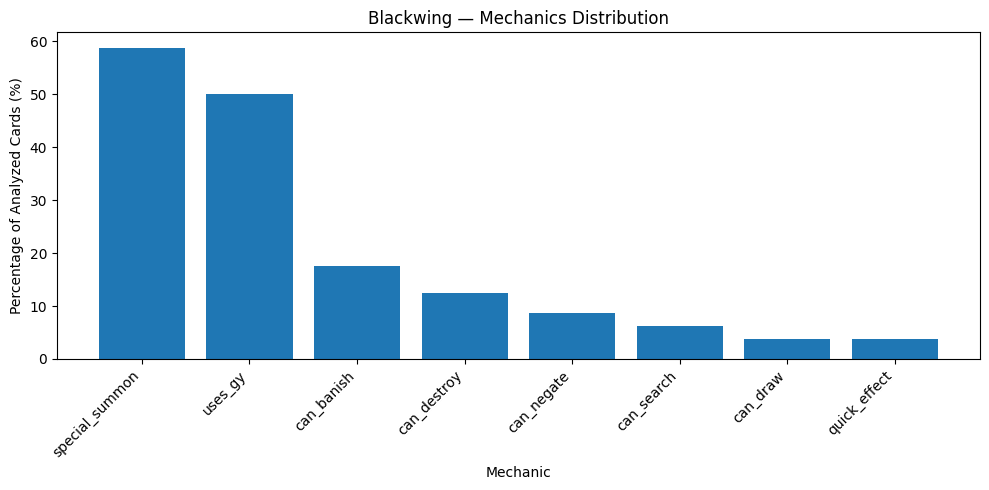

In [557]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    blackwing_mechanics["mechanic"],
    blackwing_mechanics["percentage"]
)

plt.title("Blackwing — Mechanics Distribution")
plt.xlabel("Mechanic")
plt.ylabel("Percentage of Analyzed Cards (%)")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [558]:
for archetype in [
    "Blackwing",
    "Elemental HERO",
    "Gimmick Puppet"
]:
    total = (cards["archetype"] == archetype).sum()

    analyzed = cards.loc[
        cards["archetype"] == archetype,
        "special_summon"
    ].notna().sum()

    print(
        f"{archetype}: "
        f"{analyzed}/{total} cards analyzed"
    )

Blackwing: 80/81 cards analyzed
Elemental HERO: 133/133 cards analyzed
Gimmick Puppet: 30/30 cards analyzed


In [559]:
# Phase 5.5 — Restore mechanics for banned cards

missing_mask = cards["special_summon"].isna()

# Apply the original Phase 3 formulas
desc = cards.loc[missing_mask, "desc"]

cards.loc[missing_mask, "special_summon"] = desc.str.contains(
    "Special Summon", case=False, na=False
)

cards.loc[missing_mask, "can_search"] = desc.str.contains(
    "from your Deck to your hand"
)

cards.loc[missing_mask, "can_draw"] = desc.str.contains(
    r"\bdraw\b[^.;\n]*\bcards?\b",
    case=False, na=False
)

cards.loc[missing_mask, "can_negate"] = desc.str.contains(
    "negate", case=False, na=False
)

cards.loc[missing_mask, "can_destroy"] = desc.str.contains(
    "destroy ", case=False, na=False
)

cards.loc[missing_mask, "uses_gy"] = (
    desc.str.contains("GY", case=False, na=False)
    | desc.str.contains("Graveyard", case=False, na=False)
)

cards.loc[missing_mask, "can_banish"] = desc.str.contains(
    r"\bbanish(?:ing)?\b",
    case=False, na=False
)

cards.loc[missing_mask, "quick_effect"] = desc.str.contains(
    "(Quick Effect)", case=False, na=False, regex=False
)

In [560]:
print("Total cards:", len(cards))

print("\nMissing mechanics values:")
print(cards[mechanics].isna().sum())

print("\nGofu's mechanics:")
display(
    cards.loc[
        cards["name"] == "Blackwing - Gofu the Vague Shadow",
        ["name"] + mechanics
    ]
)

Total cards: 13281

Missing mechanics values:
special_summon    0
can_search        0
can_draw          0
can_negate        0
can_destroy       0
uses_gy           0
can_banish        0
quick_effect      0
dtype: int64

Gofu's mechanics:


,name,special_summon,can_search,can_draw,can_negate,can_destroy,uses_gy,can_banish,quick_effect
1190,Blackwing - Gofu the Vague Shadow,True,False,False,False,False,True,True,False


In [561]:
blackwing_mechanics = archetype_mechanics("Blackwing")
hero_mechanics = archetype_mechanics("Elemental HERO")
puppet_mechanics = archetype_mechanics("Gimmick Puppet")

display(blackwing_mechanics)
display(hero_mechanics)
display(puppet_mechanics)

,mechanic,card_count,cards_analyzed,percentage
0,special_summon,48,81,59.26
1,uses_gy,41,81,50.62
2,can_banish,15,81,18.52
3,can_destroy,10,81,12.35
4,can_negate,7,81,8.64
5,can_search,5,81,6.17
6,can_draw,3,81,3.70
7,quick_effect,3,81,3.70


,mechanic,card_count,cards_analyzed,percentage
0,special_summon,79,133,59.40
1,uses_gy,53,133,39.85
2,can_destroy,32,133,24.06
3,can_search,11,133,8.27
4,can_negate,9,133,6.77
5,can_banish,8,133,6.02
6,can_draw,5,133,3.76
7,quick_effect,2,133,1.50


,mechanic,card_count,cards_analyzed,percentage
0,special_summon,25,30,83.33
1,uses_gy,19,30,63.33
2,can_banish,9,30,30.00
3,can_destroy,5,30,16.67
4,can_search,1,30,3.33
5,can_draw,1,30,3.33
6,can_negate,1,30,3.33
7,quick_effect,0,30,0.00


In [562]:
print(cards[mechanics].isna().sum())
print("Total cards:", len(cards))

special_summon    0
can_search        0
can_draw          0
can_negate        0
can_destroy       0
uses_gy           0
can_banish        0
quick_effect      0
dtype: int64
Total cards: 13281


### Phase 5f: Archetype Comparisons

##### Step 1

In [563]:
archetypes = [
    "Blackwing",
    "Elemental HERO",
    "Gimmick Puppet"
]

In [564]:
def compare_archetype_composition(archetype_names):
    results = []

    for name in archetype_names:
        archetype_cards = cards[
            cards["archetype"] == name
        ]

        category_counts = (
            archetype_cards["card_category"].value_counts()
        )

        results.append({
            "archetype": name,
            "total_cards": len(archetype_cards),
            "main_deck_monsters": category_counts.get(
                "Main Deck Monster", 0
            ),
            "extra_deck_monsters": category_counts.get(
                "Extra Deck Monster", 0
            ),
            "spells": category_counts.get("Spell", 0),
            "traps": category_counts.get("Trap", 0),
            "tokens": category_counts.get("Token", 0)
        })

    return pd.DataFrame(results)

In [565]:
composition_comparison = compare_archetype_composition(archetypes)

composition_comparison

,archetype,total_cards,main_deck_monsters,extra_deck_monsters,spells,traps,tokens
0,Blackwing,81,45,13,6,14,3
1,Elemental HERO,133,33,52,33,15,0
2,Gimmick Puppet,30,16,9,4,1,0


In [566]:
composition_comparison["category_total"] = (
    composition_comparison[
        [
            "main_deck_monsters",
            "extra_deck_monsters",
            "spells",
            "traps",
            "tokens"
        ]
    ].sum(axis=1)
)

composition_comparison[
    ["archetype", "total_cards", "category_total"]
]

,archetype,total_cards,category_total
0,Blackwing,81,81
1,Elemental HERO,133,133
2,Gimmick Puppet,30,30


##### Step 2

In [567]:
def compare_archetype_monster_stats(archetype_names):
    results = []

    for name in archetype_names:
        archetype_cards = cards[
            (cards["archetype"] == name)
            & cards["card_category"].isin([
                "Main Deck Monster",
                "Extra Deck Monster"
            ])
        ]

        results.append({
            "archetype": name,
            "monster_count": len(archetype_cards),
            "avg_atk": round(archetype_cards["atk"].mean(), 2),
            "avg_def": round(archetype_cards["def"].mean(), 2),
            "max_atk": archetype_cards["atk"].max(),
            "max_def": archetype_cards["def"].max()
        })

    return pd.DataFrame(results)

In [568]:
monster_comparison = compare_archetype_monster_stats(archetypes)

monster_comparison

,archetype,monster_count,avg_atk,avg_def,max_atk,max_def
0,Blackwing,58,1346.55,1115.52,3000.0,3000.0
1,Elemental HERO,85,2056.47,1777.78,4500.0,3000.0
2,Gimmick Puppet,25,1344.00,1350.00,3500.0,3100.0


In [569]:
monster_comparison["expected_monsters"] = (
    composition_comparison["main_deck_monsters"].values
    + composition_comparison["extra_deck_monsters"].values
)

monster_comparison[
    ["archetype", "monster_count", "expected_monsters"]
]

,archetype,monster_count,expected_monsters
0,Blackwing,58,58
1,Elemental HERO,85,85
2,Gimmick Puppet,25,25


##### Step 3

In [570]:
def compare_archetype_releases(archetype_names):
    results = []

    for name in archetype_names:
        history = archetype_release_history(name)

        if history.empty:
            results.append({
                "archetype": name,
                "first_year": None,
                "latest_year": None,
                "peak_year": None,
                "peak_cards": 0,
                "dated_cards": 0
            })
            continue

        peak = history.loc[history["new_cards"].idxmax()]

        results.append({
            "archetype": name,
            "first_year": int(history["release_year"].min()),
            "latest_year": int(history["release_year"].max()),
            "peak_year": int(peak["release_year"]),
            "peak_cards": int(peak["new_cards"]),
            "dated_cards": int(history["new_cards"].sum())
        })

    return pd.DataFrame(results)

In [571]:
release_comparison = compare_archetype_releases(archetypes)

release_comparison

,archetype,first_year,latest_year,peak_year,peak_cards,dated_cards
0,Blackwing,2009,2023,2009,18,78
1,Elemental HERO,2005,2024,2006,28,133
2,Gimmick Puppet,2012,2024,2014,9,29


In [572]:
for name in archetypes:
    total_cards = (cards["archetype"] == name).sum()

    dated_cards = cards.loc[
        cards["archetype"] == name,
        "release_year"
    ].notna().sum()

    print(
        f"{name}: {dated_cards}/{total_cards} "
        "cards have release dates"
    )

Blackwing: 78/81 cards have release dates
Elemental HERO: 133/133 cards have release dates
Gimmick Puppet: 29/30 cards have release dates


##### Step 4

In [573]:
def compare_archetype_mechanics(archetype_names):
    results = []

    for name in archetype_names:
        mechanic_stats = archetype_mechanics(name)

        for _, row in mechanic_stats.iterrows():
            results.append({
                "archetype": name,
                "mechanic": row["mechanic"],
                "card_count": row["card_count"],
                "percentage": row["percentage"]
            })

    return pd.DataFrame(results)

In [574]:
mechanics_comparison = compare_archetype_mechanics(archetypes)

mechanics_comparison

,archetype,mechanic,card_count,percentage
0,Blackwing,special_summon,48,59.26
1,Blackwing,uses_gy,41,50.62
2,Blackwing,can_banish,15,18.52
3,Blackwing,can_destroy,10,12.35
4,Blackwing,can_negate,7,8.64
5,Blackwing,can_search,5,6.17
6,Blackwing,can_draw,3,3.70
7,Blackwing,quick_effect,3,3.70
8,Elemental HERO,special_summon,79,59.40
9,Elemental HERO,uses_gy,53,39.85


In [575]:
mechanics_pivot = mechanics_comparison.pivot(
    index="mechanic",
    columns="archetype",
    values="percentage"
)

mechanics_pivot.round(2)

archetype,Blackwing,Elemental HERO,Gimmick Puppet
mechanic,,,
can_banish,18.52,6.02,30.00
can_destroy,12.35,24.06,16.67
can_draw,3.70,3.76,3.33
can_negate,8.64,6.77,3.33
can_search,6.17,8.27,3.33
quick_effect,3.70,1.50,0.00
special_summon,59.26,59.40,83.33
uses_gy,50.62,39.85,63.33


In [576]:
print("Total rows:", len(mechanics_comparison))

print(
    mechanics_comparison.groupby("archetype")[
        "mechanic"
    ].nunique()
)

print("Missing percentages:",
      mechanics_comparison["percentage"].isna().sum())

Total rows: 24
archetype
Blackwing         8
Elemental HERO    8
Gimmick Puppet    8
Name: mechanic, dtype: int64
Missing percentages: 0


In [577]:
def compare_archetypes(archetype_names):
    composition = compare_archetype_composition(archetype_names)
    monster_stats = compare_archetype_monster_stats(archetype_names)
    releases = compare_archetype_releases(archetype_names)

    comparison = composition.merge(
        monster_stats,
        on="archetype",
        how="left"
    )

    comparison = comparison.merge(
        releases,
        on="archetype",
        how="left"
    )

    return comparison

##### Step 5

In [578]:
def compare_archetypes(archetype_names):
    composition = compare_archetype_composition(archetype_names)
    monster_stats = compare_archetype_monster_stats(archetype_names)
    releases = compare_archetype_releases(archetype_names)

    comparison = composition.merge(
        monster_stats,
        on="archetype",
        how="left"
    )

    comparison = comparison.merge(
        releases,
        on="archetype",
        how="left"
    )

    return comparison

In [579]:
archetype_comparison = compare_archetypes(archetypes)

archetype_comparison

,archetype,total_cards,main_deck_monsters,extra_deck_monsters,spells,traps,tokens,monster_count,avg_atk,avg_def,max_atk,max_def,first_year,latest_year,peak_year,peak_cards,dated_cards
0,Blackwing,81,45,13,6,14,3,58,1346.55,1115.52,3000.0,3000.0,2009,2023,2009,18,78
1,Elemental HERO,133,33,52,33,15,0,85,2056.47,1777.78,4500.0,3000.0,2005,2024,2006,28,133
2,Gimmick Puppet,30,16,9,4,1,0,25,1344.00,1350.00,3500.0,3100.0,2012,2024,2014,9,29


In [580]:
def compare_archetypes(archetype_names):
    composition = compare_archetype_composition(archetype_names)
    monster_stats = compare_archetype_monster_stats(archetype_names)
    releases = compare_archetype_releases(archetype_names)
    mechanic_stats = compare_archetype_mechanics(archetype_names)

    mechanics_wide = mechanic_stats.pivot(
        index="archetype",
        columns="mechanic",
        values="percentage"
    ).reset_index()

    comparison = (
        composition
        .merge(monster_stats, on="archetype", how="left")
        .merge(releases, on="archetype", how="left")
        .merge(mechanics_wide, on="archetype", how="left")
    )

    return comparison

In [581]:
archetype_comparison = compare_archetypes(archetypes)

print("Shape:", archetype_comparison.shape)
print("Duplicate archetypes:",
      archetype_comparison["archetype"].duplicated().sum())
print("Missing values:",
      archetype_comparison.isna().sum().sum())

archetype_comparison

Shape: (3, 25)
Duplicate archetypes: 0
Missing values: 0


,archetype,total_cards,main_deck_monsters,extra_deck_monsters,spells,traps,tokens,monster_count,avg_atk,avg_def,...,peak_cards,dated_cards,can_banish,can_destroy,can_draw,can_negate,can_search,quick_effect,special_summon,uses_gy
0,Blackwing,81,45,13,6,14,3,58,1346.55,1115.52,...,18,78,18.52,12.35,3.70,8.64,6.17,3.7,59.26,50.62
1,Elemental HERO,133,33,52,33,15,0,85,2056.47,1777.78,...,28,133,6.02,24.06,3.76,6.77,8.27,1.5,59.40,39.85
2,Gimmick Puppet,30,16,9,4,1,0,25,1344.00,1350.00,...,9,29,30.00,16.67,3.33,3.33,3.33,0.0,83.33,63.33


In [582]:
print("Shape:", archetype_comparison.shape)

print(
    "Duplicate archetypes:",
    archetype_comparison["archetype"].duplicated().sum()
)

print(
    "Missing values:",
    archetype_comparison.isna().sum().sum()
)

print(
    "Archetypes:",
    archetype_comparison["archetype"].tolist()
)

Shape: (3, 25)
Duplicate archetypes: 0
Missing values: 0
Archetypes: ['Blackwing', 'Elemental HERO', 'Gimmick Puppet']


### Phase 5g: Streamlit Integration

##### Step 1

In [583]:
required_columns = [
    "id",
    "name",
    "archetype",
    "card_category",
    "monster_race",
    "spell_type",
    "trap_type",
    "atk",
    "def",
    "release_year",
    "level_type",
    "level_value"
] + mechanics

missing_columns = [
    col for col in required_columns
    if col not in cards.columns
]

print("Dataset shape:", cards.shape)
print("Missing required columns:", missing_columns)
print("Unique archetypes:", cards["archetype"].nunique())

Dataset shape: (13281, 60)
Missing required columns: []
Unique archetypes: 556


In [584]:
cards.to_csv(
    "ygo_cards_features.csv",
    index=False
)

print("Updated feature dataset exported successfully!")

Updated feature dataset exported successfully!


In [585]:
check = pd.read_csv("ygo_cards_features.csv")

check[
    ["name", "monster_race", "spell_type", "trap_type"]
].head(10)

,name,monster_race,spell_type,trap_type
0,"""A"" Cell Breeding Device",NaN,Continuous,NaN
1,"""A"" Cell Incubator",NaN,Continuous,NaN
2,"""A"" Cell Recombination Device",NaN,Quick-Play,NaN
3,"""A"" Cell Scatter Burst",NaN,Quick-Play,NaN
4,"""Infernoble Arms - Almace""",NaN,Equip,NaN
5,"""Infernoble Arms - Durendal""",NaN,Equip,NaN
6,"""Infernoble Arms - Hauteclere""",NaN,Equip,NaN
7,"""Infernoble Arms - Joyeuse""",NaN,Equip,NaN
8,1st Movement Solo,NaN,Normal,NaN
9,3-Hump Lacooda,Beast,NaN,NaN


In [586]:
print(check.columns.tolist())

['id', 'name', 'type', 'desc', 'atk', 'def', 'level', 'race', 'attribute', 'scale', 'archetype', 'linkval', 'linkmarkers', 'image_url', 'image_url_small', 'ban_tcg', 'ban_ocg', 'ban_goat', 'staple', 'views', 'viewsweek', 'upvotes', 'downvotes', 'formats', 'treated_as', 'tcg_date', 'ocg_date', 'konami_id', 'has_effect', 'card_category', 'monster_race', 'spell_type', 'trap_type', 'level_type', 'level_value', 'monster_level', 'monster_rank', 'monster_link_rating', 'release_year', 'special_summon', 'can_search', 'can_draw', 'can_negate', 'can_destroy', 'uses_gy', 'can_banish', 'quick_effect', 'from_your_hand', 'protection', 'atk_def_cards', 'piercing', 'burn', 'pay_lp', 'lp_gain', 'change_control', 'change_battle_position', 'tribute', 'discard', 'bounce', 'shuffle_into_deck']


In [587]:
cards.loc[
    cards["name"].isin([
        "Blackwing - Twin Shadow",
        "Black Whirlwind",
        "Blackwing - Gale the Whirlwind"
    ]),
    ["name", "monster_race", "spell_type", "trap_type"]
]

,name,monster_race,spell_type,trap_type
1154,Black Whirlwind,NaN,Continuous,NaN
1187,Blackwing - Gale the Whirlwind,Winged Beast,NaN,NaN
1215,Blackwing - Twin Shadow,NaN,NaN,Normal


In [588]:
numbers = [12, 45, 7, 89, 23]
largest = numbers[0]
largest

12

# Phase 6

In [589]:
# Check the dataset for Phase 6
print("Total cards:", len(cards))

print("\nRelease year range:")
print(cards["release_year"].min())
print(cards["release_year"].max())

print("\nCards missing release years:")
print(cards["release_year"].isna().sum())

print("\nAvailable card classifications:")
print(cards["card_category"].value_counts())

Total cards: 13281

Release year range:
2001.0
2024.0

Cards missing release years:
416

Available card classifications:
card_category
Main Deck Monster     6627
Spell                 2592
Trap                  1934
Extra Deck Monster    1897
Skill                  124
Token                  107
Name: count, dtype: int64


In [590]:
# Phase 6: Card releases by year

release_df = cards[
    cards["release_year"].notna()
].copy()

yearly_releases = (
    release_df
    .groupby("release_year")
    .size()
    .reset_index(name="new_cards")
    .sort_values("release_year")
)

yearly_releases["release_year"] = (
    yearly_releases["release_year"].astype(int)
)

yearly_releases

,release_year,new_cards
0,2001,1
1,2002,609
2,2003,551
3,2004,397
4,2005,289
5,2006,329
6,2007,414
7,2008,490
8,2009,475
9,2010,592


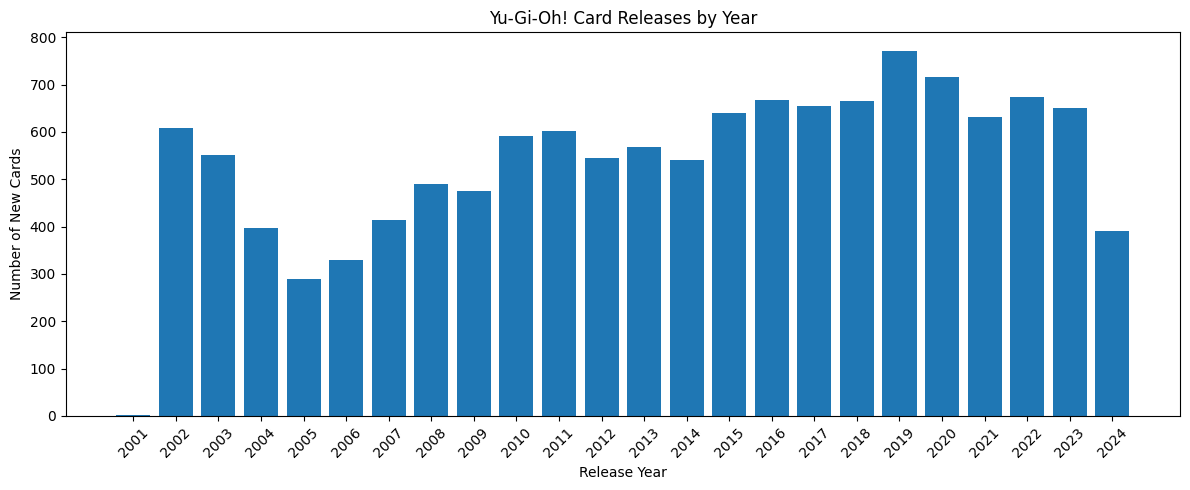

In [591]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.bar(
    yearly_releases["release_year"],
    yearly_releases["new_cards"]
)

plt.title("Yu-Gi-Oh! Card Releases by Year")
plt.xlabel("Release Year")
plt.ylabel("Number of New Cards")
plt.xticks(yearly_releases["release_year"], rotation=45)
plt.tight_layout()
plt.show()

##### Step 3A — Inspect the card types

In [592]:
cards["type"].value_counts()

type
Effect Monster                     4725
Spell Card                         2592
Trap Card                          1934
Normal Monster                      662
XYZ Monster                         521
Fusion Monster                      479
Tuner Monster                       462
Link Monster                        415
Synchro Monster                     413
Pendulum Effect Monster             273
Flip Effect Monster                 184
Skill Card                          124
Ritual Effect Monster               116
Token                               107
Gemini Monster                       45
Synchro Tuner Monster                41
Union Effect Monster                 39
Pendulum Normal Monster              36
Spirit Monster                       33
Toon Monster                         17
Ritual Monster                       15
Pendulum Effect Fusion Monster       11
XYZ Pendulum Effect Monster          10
Normal Tuner Monster                 10
Pendulum Tuner Effect Monster      

##### Step 3B — Create summoning-mechanic indicators

In [593]:
# Create binary indicators for summoning mechanics

summoning_mechanics = {
    "is_fusion": "Fusion",
    "is_synchro": "Synchro",
    "is_xyz": "XYZ",
    "is_pendulum": "Pendulum",
    "is_link": "Link",
    "is_ritual": "Ritual"
}

for column, keyword in summoning_mechanics.items():
    cards[column] = (
        cards["type"]
        .str.contains(keyword, case=False, na=False, regex=False)
        .astype(int)
    )

##### Step 3C — Validate the new columns

In [594]:
# Count cards belonging to each summoning mechanic

cards[list(summoning_mechanics.keys())].sum()

is_fusion      490
is_synchro     461
is_xyz         531
is_pendulum    347
is_link        415
is_ritual      132
dtype: int64

##### Step 3d - Summoning Mechanics by Release Year

In [595]:
# Count newly released cards for each summoning mechanic by year

mechanic_columns = list(summoning_mechanics.keys())

summoning_by_year = (
    cards.dropna(subset=["release_year"])
    .groupby("release_year")[mechanic_columns]
    .sum()
    .astype(int)
)

summoning_by_year.index = summoning_by_year.index.astype(int)

summoning_by_year

,is_fusion,is_synchro,is_xyz,is_pendulum,is_link,is_ritual
release_year,,,,,,
2001,0,0,0,0,0,0
2002,28,0,0,0,0,6
2003,15,0,0,0,0,5
2004,5,0,0,0,0,1
2005,15,0,0,0,0,3
2006,24,0,0,0,0,3
2007,17,0,0,0,0,5
2008,13,18,0,0,0,1
2009,4,29,0,0,0,1


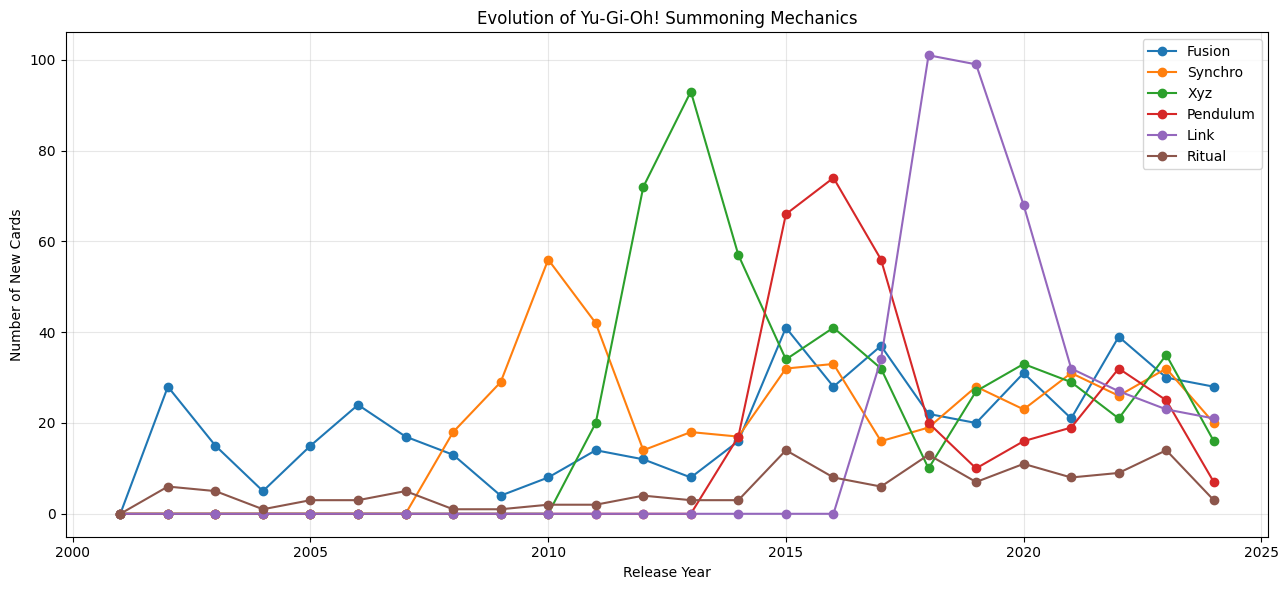

In [596]:
import matplotlib.pyplot as plt

summoning_by_year.plot(
    kind="line",
    figsize=(13, 6),
    marker="o"
)

plt.title("Evolution of Yu-Gi-Oh! Summoning Mechanics")
plt.xlabel("Release Year")
plt.ylabel("Number of New Cards")
plt.legend([
    "Fusion", "Synchro", "Xyz",
    "Pendulum", "Link", "Ritual"
])
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

###

##### Step 3E - Calculate percentages

In [597]:
# Keep only monsters with known release years

monster_df = cards[
    cards["card_category"].isin([
        "Main Deck Monster",
        "Extra Deck Monster"
    ])
    & cards["release_year"].notna()
].copy()

# Count total monsters released each year

monsters_per_year = (
    monster_df.groupby("release_year")
    .size()
)

# Calculate percentage for each mechanic

summoning_percentages = (
    summoning_by_year
    .div(monsters_per_year, axis=0)
    .mul(100)
    .round(2)
)

summoning_percentages

,is_fusion,is_synchro,is_xyz,is_pendulum,is_link,is_ritual
release_year,,,,,,
2001,0.00,0.00,0.00,0.00,0.00,0.00
2002,6.83,0.00,0.00,0.00,0.00,1.46
2003,4.93,0.00,0.00,0.00,0.00,1.64
2004,2.07,0.00,0.00,0.00,0.00,0.41
2005,8.29,0.00,0.00,0.00,0.00,1.66
2006,12.18,0.00,0.00,0.00,0.00,1.52
2007,7.11,0.00,0.00,0.00,0.00,2.09
2008,4.32,5.98,0.00,0.00,0.00,0.33
2009,1.34,9.70,0.00,0.00,0.00,0.33


##### Step 3F: Visualize percentages

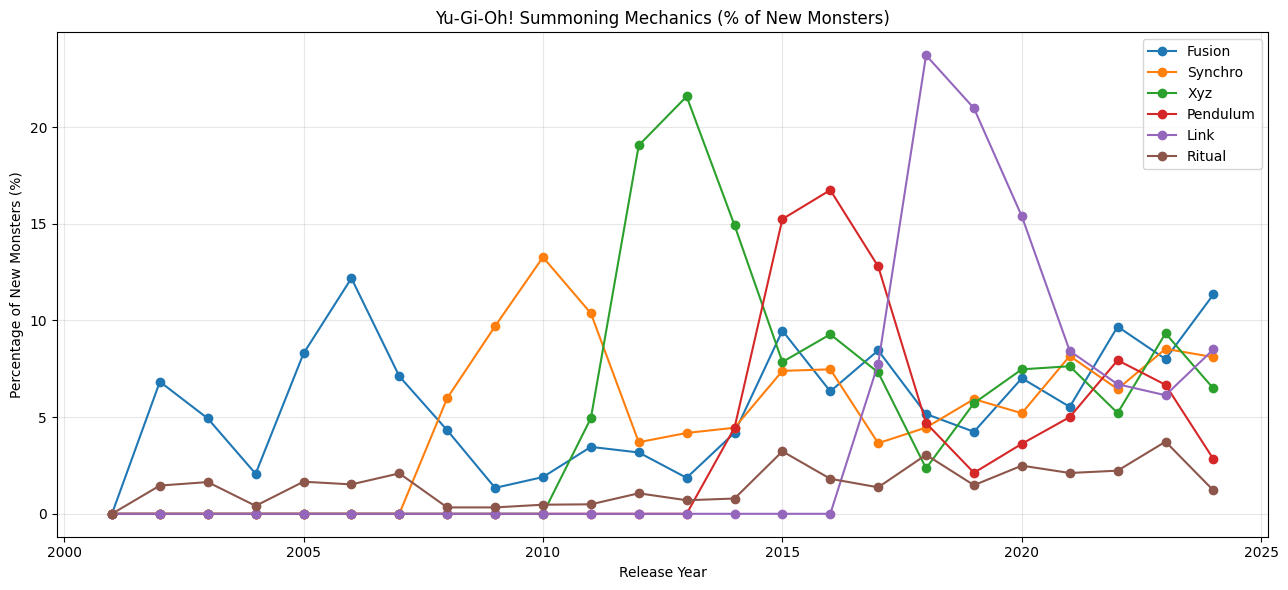

In [598]:
# Plot summoning mechanic percentages by year

summoning_percentages.plot(
    kind="line",
    figsize=(13, 6),
    marker="o"
)

plt.title("Yu-Gi-Oh! Summoning Mechanics (% of New Monsters)")
plt.xlabel("Release Year")
plt.ylabel("Percentage of New Monsters (%)")

plt.legend([
    "Fusion", "Synchro", "Xyz",
    "Pendulum", "Link", "Ritual"
])

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [599]:
monster_df.groupby("release_year").size().head()

release_year
2001.0      1
2002.0    410
2003.0    304
2004.0    242
2005.0    181
dtype: int64

##### Step 4a - Create the effect-text length feature

In [600]:
# Calculate the number of characters in each card's description

cards["effect_text_length"] = (
    cards["desc"]
    .fillna("")
    .str.len()
)

# Check the results
cards[["name", "type", "effect_text_length"]].head(10)

,name,type,effect_text_length
0,"""A"" Cell Breeding Device",Spell Card,96
1,"""A"" Cell Incubator",Spell Card,188
2,"""A"" Cell Recombination Device",Spell Card,356
3,"""A"" Cell Scatter Burst",Spell Card,145
4,"""Infernoble Arms - Almace""",Spell Card,477
5,"""Infernoble Arms - Durendal""",Spell Card,494
6,"""Infernoble Arms - Hauteclere""",Spell Card,494
7,"""Infernoble Arms - Joyeuse""",Spell Card,368
8,1st Movement Solo,Spell Card,263
9,3-Hump Lacooda,Effect Monster,107


In [601]:
cards["effect_text_length"].describe()

count    13281.000000
mean       298.044876
std        159.290729
min          2.000000
25%        159.000000
50%        290.000000
75%        428.000000
max       1005.000000
Name: effect_text_length, dtype: float64

##### Step 4C: Analyze Effect Monsters

In [602]:
# Select Effect Monsters with known release years

effect_monsters = cards[
    (cards["has_effect"] == 1)
    & (cards["card_category"].isin([
        "Main Deck Monster",
        "Extra Deck Monster"
    ]))
    & (cards["release_year"].notna())
].copy()

# Check our filtered dataset

print("Total Effect Monsters:", len(effect_monsters))

effect_monsters[
    ["name", "type", "release_year", "effect_text_length"]
].head(10)

Total Effect Monsters: 7633


,name,type,release_year,effect_text_length
9,3-Hump Lacooda,Effect Monster,2004.0,107
11,4-Starred Ladybug of Doom,Flip Effect Monster,2002.0,58
15,8-Claws Scorpion,Effect Monster,2003.0,204
16,A Cat of Ill Omen,Flip Effect Monster,2003.0,150
24,A Man with Wdjat,Effect Monster,2003.0,197
29,A-Assault Core,Union Effect Monster,2016.0,461
30,A-Team: Trap Disposal Unit,Effect Monster,2004.0,178
32,A-to-Z-Dragon Buster Cannon,Fusion Monster,2016.0,567
42,A/D Changer,Effect Monster,2010.0,109
43,ABC-Dragon Buster,Fusion Monster,2016.0,478


##### Step 4D: Average Effect-Text Length by Year

In [603]:
# Calculate average and median effect-text length by year

effect_length_by_year = (
    effect_monsters
    .groupby("release_year")["effect_text_length"]
    .agg(["count", "mean", "median"])
    .round(2)
)

effect_length_by_year.index = (
    effect_length_by_year.index.astype(int)
)

effect_length_by_year

,count,mean,median
release_year,,,
2002,135,158.28,142.0
2003,243,207.04,175.0
2004,208,165.40,144.0
2005,151,191.68,176.0
2006,171,210.91,197.0
2007,222,236.35,218.0
2008,294,228.39,201.5
2009,295,234.72,219.0
2010,411,208.55,190.0


In [604]:
effect_monsters["type"].value_counts()

type
Effect Monster                     4665
XYZ Monster                         508
Tuner Monster                       458
Fusion Monster                      405
Synchro Monster                     404
Link Monster                        400
Pendulum Effect Monster             268
Flip Effect Monster                 183
Ritual Effect Monster               116
Gemini Monster                       45
Synchro Tuner Monster                40
Union Effect Monster                 36
Spirit Monster                       33
Toon Monster                         17
Pendulum Effect Fusion Monster       11
XYZ Pendulum Effect Monster          10
Normal Tuner Monster                 10
Pendulum Tuner Effect Monster         8
Synchro Pendulum Effect Monster       7
Normal Monster                        5
Pendulum Normal Monster               2
Pendulum Effect Ritual Monster        1
Pendulum Flip Effect Monster          1
Name: count, dtype: int64

In [605]:
# Exclude Normal Monster classifications

normal_types = [
    "Normal Monster",
    "Normal Tuner Monster",
    "Pendulum Normal Monster"
]

effect_monsters = effect_monsters[
    ~effect_monsters["type"].isin(normal_types)
].copy()

# Verify the results
effect_monsters["type"].value_counts()

type
Effect Monster                     4665
XYZ Monster                         508
Tuner Monster                       458
Fusion Monster                      405
Synchro Monster                     404
Link Monster                        400
Pendulum Effect Monster             268
Flip Effect Monster                 183
Ritual Effect Monster               116
Gemini Monster                       45
Synchro Tuner Monster                40
Union Effect Monster                 36
Spirit Monster                       33
Toon Monster                         17
Pendulum Effect Fusion Monster       11
XYZ Pendulum Effect Monster          10
Pendulum Tuner Effect Monster         8
Synchro Pendulum Effect Monster       7
Pendulum Effect Ritual Monster        1
Pendulum Flip Effect Monster          1
Name: count, dtype: int64

##### Step 4D: Average Effect-Text Length by Year

In [606]:
effect_length_by_year = (
    effect_monsters
    .groupby("release_year")["effect_text_length"]
    .agg(["count", "mean", "median"])
    .round(2)
)

effect_length_by_year.index = (
    effect_length_by_year.index.astype(int)
)

effect_length_by_year

,count,mean,median
release_year,,,
2002,135,158.28,142.0
2003,243,207.04,175.0
2004,208,165.40,144.0
2005,151,191.68,176.0
2006,171,210.91,197.0
2007,222,236.35,218.0
2008,292,228.96,202.5
2009,294,235.15,220.0
2010,409,208.64,190.0


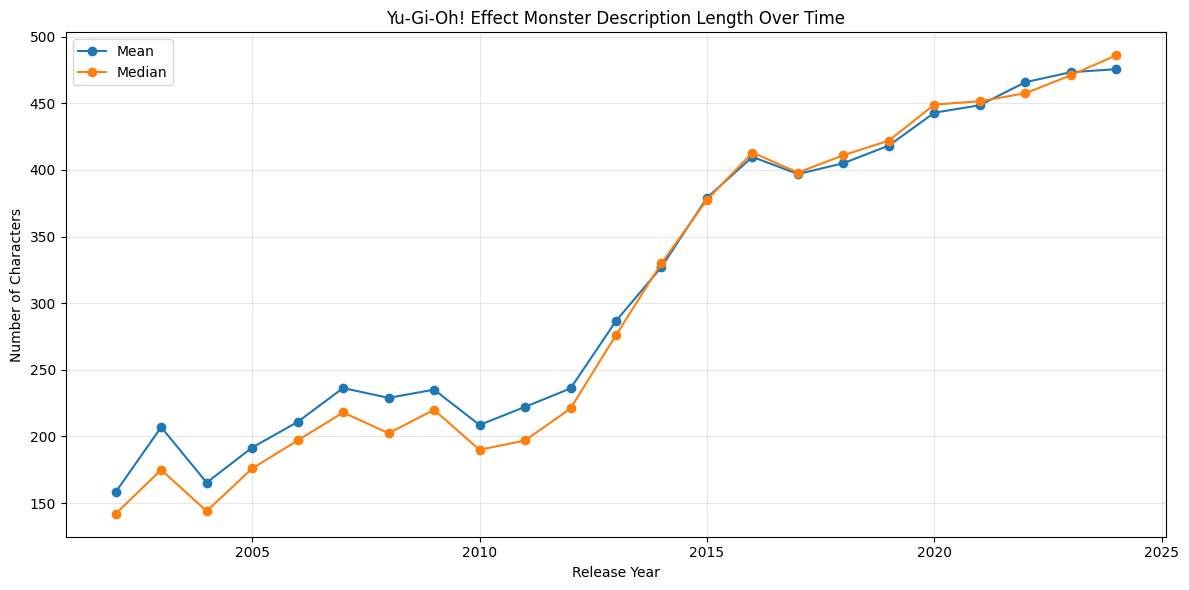

In [607]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    effect_length_by_year.index,
    effect_length_by_year["mean"],
    marker="o",
    label="Mean"
)

plt.plot(
    effect_length_by_year.index,
    effect_length_by_year["median"],
    marker="o",
    label="Median"
)

plt.title("Yu-Gi-Oh! Effect Monster Description Length Over Time")
plt.xlabel("Release Year")
plt.ylabel("Number of Characters")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

##### Step 5A: Create an OPT indicator

In [608]:
# Create an indicator for once-per-turn restrictions

effect_monsters["has_opt"] = (
    effect_monsters["desc"]
    .fillna("")
    .str.contains(
        r"once per turn|you can only use.*per turn|you can only activate.*per turn",
        case=False,
        regex=True
    )
    .astype(int)
)

# Count cards with and without OPT wording
effect_monsters["has_opt"].value_counts()

has_opt
1    4391
0    3225
Name: count, dtype: int64

##### Step 5B: Validate our OPT indicator

In [609]:
# Inspect cards where OPT wording was detected

effect_monsters.loc[
    effect_monsters["has_opt"] == 1,
    ["name", "release_year", "desc"]
].sample(5, random_state=42)

,name,release_year,desc
12236,Ultimate Flagship Ursatron,2021.0,"(This card is always treated as an ""Ursarctic"" and ""Drytron"" card.)\r\nMust be Special Summoned with ""Ursarctic Drytron"". Once per turn, if another Effect Monster is Special Summoned to your field (except during the Damage Step): You can add 1 ""Ursarctic"" or ""Drytron"" monster from your Deck to your hand. Once per turn: You can target 1 of your banished ""Ursarctic"" or ""Drytron"" monsters; add it to your hand."
947,Battlecruiser Dianthus,2013.0,"3 Level 3 monsters\nYou can detach 1 Xyz Material from this card; inflict 200 damage to your opponent for each card in their hand. You can only use the effect of ""Battlecruiser Dianthus"" once per turn."
9216,Raging Eria,2006.0,"Once per turn, you can Tribute 1 WATER monster (except this card) to Special Summon 1 WATER monster from your hand. The monster Special Summoned by this effect is destroyed if ""Raging Eria"" is removed from your side of the field."
9537,Rescue Interlacer,2019.0,"During damage calculation, if your Cyberse monster is attacked (Quick Effect): You can discard this card; you take no battle damage from that battle. You can only use this effect of ""Rescue Interlacer"" once per turn. Once per turn, during the End Phase, if this card is in the GY because it was discarded there to activate this effect this turn: Special Summon this card."
8377,Orbital Hydralander,2017.0,"Cannot be Normal Summoned/Set. Must be Special Summoned (from your hand) by having 5 or more monsters in your GY, and no monsters in your GY with the same name. Once per turn (Quick Effect): You can send the top 3 cards of your Deck to the GY; destroy 1 card on the field. You must have at least 2 monsters in your GY, and no monsters in your GY with the same name, to activate and to resolve this effect."


##### Step 5C: OPT prevalence by year

In [610]:
opt_by_year = (
    effect_monsters
    .groupby("release_year")["has_opt"]
    .agg(["count", "sum", "mean"])
)

opt_by_year["opt_percentage"] = (
    opt_by_year["mean"] * 100
).round(2)

opt_by_year.index = opt_by_year.index.astype(int)

opt_by_year

,count,sum,mean,opt_percentage
release_year,,,,
2002,135,9,0.066667,6.67
2003,243,32,0.131687,13.17
2004,208,22,0.105769,10.58
2005,151,25,0.165563,16.56
2006,171,31,0.181287,18.13
2007,222,47,0.211712,21.17
2008,292,59,0.202055,20.21
2009,294,73,0.248299,24.83
2010,409,91,0.222494,22.25


##### Step 5D: Create the visualization in Python

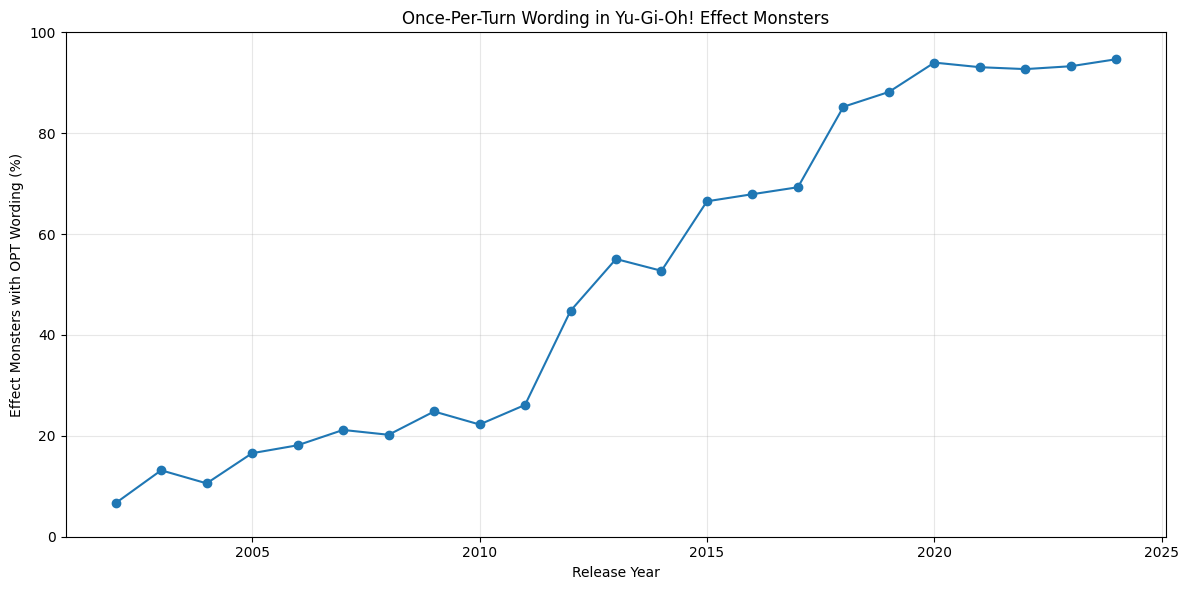

In [611]:
plt.figure(figsize=(12, 6))

plt.plot(
    opt_by_year.index,
    opt_by_year["opt_percentage"],
    marker="o"
)

plt.title("Once-Per-Turn Wording in Yu-Gi-Oh! Effect Monsters")
plt.xlabel("Release Year")
plt.ylabel("Effect Monsters with OPT Wording (%)")

plt.ylim(0, 100)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

##### Step 5E: Separating SOPT and HOPT

In [612]:
# Identify Hard Once Per Turn wording

effect_monsters["has_hopt"] = (
    effect_monsters["desc"]
    .fillna("")
    .str.contains(
        r"you can only (?:use|activate).*?per turn",
        case=False,
        regex=True
    )
    .astype(int)
)

effect_monsters["has_hopt"].value_counts()

has_hopt
0    4806
1    2810
Name: count, dtype: int64

##### Step 5F — Validate HOPT matches

In [613]:
effect_monsters.loc[
    effect_monsters["has_hopt"] == 1,
    ["name", "release_year", "desc"]
].sample(10, random_state=42)

,name,release_year,desc
7270,Mekk-Knight Spectrum Supreme,2018.0,"2+ ""Mekk-Knight"" monsters\nThis card can attack directly if it is the only card in its column. If this card in the Extra Monster Zone points to no monsters, it cannot be destroyed by card effects, also your opponent cannot target it with card effects. You can send 1 other card you control in this card's column to the GY: Special Summon 1 ""Mekk-Knight"" monster from your Deck in Defense Position. You can only use this effect of ""Mekk-Knight Spectrum Supreme"" once per turn."
11101,Superheavy Samurai General Coral,2016.0,"[ Pendulum Effect ] \nWhile you have a Spell/Trap Card(s) in your Graveyard, this card's Pendulum Scale becomes 4. Once per turn, when a ""Superheavy Samurai"" monster you control destroys an opponent's monster by battle: You can activate this effect; that monster can make a second attack in a row (even if this card leaves the field).\n[ Monster Effect ] \nIf you have no Spell/Trap Cards in your Graveyard: You can Tribute up to 2 ""Superheavy Samurai"" monsters; draw that many cards. You can only use this effect of ""Superheavy Samurai General Coral"" once per turn."
11231,Swordsoul Supreme Sovereign - Chengying,2021.0,"1 Tuner + 1+ non-Tuner monsters\r\nFor each banished card, this card gains 100 ATK/DEF and monsters your opponent controls lose 100 ATK/DEF. If this card would be destroyed by card effect, you can banish 1 card from your GY instead. If a card(s) is banished (except during the Damage Step): You can banish 1 card each from both your opponent's field and GY. You can only use this effect of ""Swordsoul Supreme Sovereign - Chengying"" once per turn."
7082,Marincess Basilalima,2020.0,"If a monster(s) you control would be destroyed by card effect, you can banish this card from your GY instead. You can only use each of the following effects of ""Marincess Basilalima"" once per turn.\r\n● You can banish 1 ""Marincess"" Trap from your GY; add 1 ""Marincess"" Trap with a different name from your Deck to your hand.\r\n● If this card is banished: You can target 1 face-up monster you control; it gains 600 ATK."
5300,Guardragon Elpy,2019.0,"1 Level 4 or lower Dragon monster\r\nYou cannot Special Summon monsters, except Dragon monsters. During your Main Phase: You can Special Summon 1 Dragon monster from your hand or Deck to your zone that 2 or more Link Monsters point to. You can only use this effect of ""Guardragon Elpy"" once per turn. You can only Special Summon ""Guardragon Elpy(s)"" once per turn."
10760,Splash Mage,2020.0,"2 Cyberse monsters\r\nYou can target 1 Cyberse monster in your GY; Special Summon it in Defense Position, but negate its effects, also you cannot Special Summon monsters for the rest of this turn, except Cyberse monsters. You can only use this effect of ""Splash Mage"" once per turn."
2718,Darklord Tezcatlipoca,2016.0,"If a ""Darklord"" monster(s) you control would be destroyed by battle or card effect, you can discard this card instead. During either player's turn: You can pay 1000 LP, then target 1 ""Darklord"" Spell/Trap Card in your Graveyard; apply that target's effect, then shuffle that target into the Deck. You can only use this effect of ""Darklord Tezcatlipoca"" once per turn. You can only Special Summon ""Darklord Tezcatlipoca(s)"" once per turn."
8034,Noble Knight Pellinore,2018.0,"You can target 1 ""Noble Arms"" Equip Spell equipped to this card and 1 face-up monster your opponent controls; destroy them, then draw 1 card, also, this card cannot attack for the rest of this turn. You can only use this effect of ""Noble Knight Pellinore"" once per turn."
10451,Skypalace Gangaridai,2013.0,"2 Level 10 monsters\nYou can detach 1 Xyz Material from this card, then target 1 card your opponent controls; destroy that target, and if you do, inflict 1000 damage to your opponent. You can only use the effect of ""Skypalace Gangaridai"" once per turn. This card cannot attack the turn you activate this effect."
7987,"Nina

In [614]:
# Inspect 10 cards classified as NOT having HOPT

effect_monsters.loc[
    effect_monsters["has_hopt"] == 0,
    ["name", "release_year", "desc"]
].sample(10, random_state=42)

,name,release_year,desc
3868,Evolzar Lars,2023.0,"2 Level 6 monsters\r\nWhile this card has material, your opponent cannot target it with monster effects. When your opponent activates a card or effect (Quick Effect): You can detach 2 materials from this card, or just 1 material if all this card's materials are Reptile and/or Dinosaur, then target 1 face-up card your opponent controls; negate its effects until the end of this turn."
7819,Naturia Gaiastrio,2015.0,"2 EARTH Synchro Monsters\nDuring either player's turn, when a card or effect is activated that targets exactly 1 card on the field (and no other cards): You can send 1 card from your hand to the Graveyard; negate the activation, and if you do, destroy that card."
2163,Crystal Beast Amber Mammoth,2007.0,"When another face-up ""Crystal Beast"" monster you control is targeted for an attack: You can make this card the attack target instead. If this face-up card is destroyed while it is in a Monster Card Zone, you can place it face-up in your Spell & Trap Card Zone as a Continuous Spell Card, instead of sending it to the Graveyard."
2773,Deep-Space Cruiser IX,2014.0,You can Special Summon this card (from your hand) by sending 1 other Machine-Type monster from your hand to the Graveyard.
42,A/D Changer,2010.0,"You can banish this card from your Graveyard, then target 1 monster on the field; change its battle position."
4714,Genex Ally Axel,2010.0,"1 ""Genex"" Tuner + 1 or more non-Tuner monsters\nOnce per turn, you can discard 1 card to select 1 Level 4 or lower Machine-Type monster from your Graveyard, and Special Summon it. The ATK of that monster is doubled until the End Phase, but it cannot attack your opponent directly. Remove that monster from play during your End Phase."
4925,Gladiator Beast Alexander,2007.0,"This card cannot be Special Summoned except by the effect of ""Gladiator Beast Dimacari"". If this card was Special Summoned, it is unaffected by the effects of Spell Cards. At the end of the Battle Phase, if this card attacked or was attacked, you can return it to the Deck to Special Summon 1 ""Gladiator Beast"" monster from your Deck, except ""Gladiator Beast Alexander""."
680,Aromage Cananga,2015.0,"While your LP is higher than your opponent's, face-up monsters your opponent controls lose 500 ATK and DEF. Once per turn, if you gain LP: Target 1 Spell/Trap Card your opponent controls; return it to the hand."
9191,R-Genex Undine,2024.0,"Once per turn: You can banish 1 ""Genex"" monster from your GY; this card gains that monster's Attribute, then if you banished a Tuner to activate this effect, you can treat this card as a Tuner until the end of this turn. If you control a ""Genex"" Synchro Monster: You can target 2 ""Genex"" monsters in your GY, including this card; add them to your hand, also for the rest of this turn, any card sent to your GY is banished instead."
11167,Surgical Striker - H.A.M.P.,2022.0,"(This card is always treated as a ""Sky Striker"" card.)\r\nIf you control a ""Sky Striker Ace"" monster, you can Special Summon this card (from your hand) to either field by Tributing 1 monster from that field. You can only Special Summon ""Surgical Striker - H.A.M.P."" once per turn this way. When this card is destroyed by battle: You can target 1 card your opponent controls; destroy it."


##### Step 5G: Create the SOPT indicator

In [615]:
# Detect common SOPT wording

effect_monsters["has_sopt"] = (
    effect_monsters["desc"]
    .fillna("")
    .str.contains(
        r"once per turn\s*[:,]",
        case=False,
        regex=True
    )
    .astype(int)
)

effect_monsters["has_sopt"].value_counts()

has_sopt
0    5954
1    1662
Name: count, dtype: int64

##### Step 5H — Validate SOPT detection

In [616]:
effect_monsters.loc[
    effect_monsters["has_sopt"] == 1,
    ["name", "release_year", "desc"]
].sample(10, random_state=42)

,name,release_year,desc
7663,Morphtronic Remoten,2009.0,"● Once per turn, while in Attack Position: You can target 1 ""Morphtronic"" monster in your Graveyard; banish that target and add 1 ""Morphtronic"" monster with the same Level as the target from your Deck to your hand.\n● Once per turn, while in Defense Position: You can send 1 ""Morphtronic"" monster from your hand to the Graveyard and add 1 other ""Morphtronic"" monster with the same Level as that monster from your Graveyard to your hand."
1303,Blue-Eyes Spirit Dragon,2016.0,"1 Tuner + 1 or more non-Tuner ""Blue-Eyes"" monsters\r\nNeither player can Special Summon 2 or more monsters at the same time. Once per turn, during either player's turn, when an effect of a card in the Graveyard is activated: You can negate the activation. During either player's turn: You can Tribute this Synchro Summoned card; Special Summon 1 LIGHT Dragon-Type Synchro Monster from your Extra Deck in Defense Position, except ""Blue-Eyes Spirit Dragon"", but destroy it during the End Phase of this turn."
1734,"Chaofeng, Phantom of the Yang Zing",2015.0,"1 Tuner + 1 or more non-Tuner monsters\r\nWhile this Synchro Summoned card is on the field, your opponent cannot activate effects of monsters with the same original Attribute(s) as the ""Yang Zing"" monster(s) used for the Synchro Summon of this card. When this Synchro Summoned card is destroyed by battle or card effect and sent to the Graveyard: You can add 1 Tuner monster from your Deck to your hand. Once per turn, when a monster(s) your opponent controls is destroyed by battle or card effect: You can Special Summon 1 Wyrm-Type monster from your Deck, in Defense Position, whose original Attribute matches the original Attribute that 1 of those destroyed monsters had on the field."
8957,Predaplant Moray Nepenthes,2016.0,"This card gains 200 ATK for each Predator Counter on the field. When this card destroys an opponent's monster by battle: You can equip that monster to this card. Once per turn: You can target 1 Monster Card equipped to this card by this card's effect; destroy it, and if you do, gain LP equal to its original ATK."
2712,Darklord Morningstar,2016.0,"Cannot be Special Summoned. If this card is Tribute Summoned: You can Special Summon ""Darklord"" monsters from your hand and/or Deck, up to the number of Effect Monsters your opponent controls. While you control another ""Darklord"" monster, your opponent cannot target this card with card effects. Once per turn: You can send cards from the top of your Deck to the Graveyard, equal to the number of ""Darklord"" monsters on the field, and if you do, gain 500 LP for each ""Darklord"" card sent to the Graveyard by this effect."
2255,Cyber Angel Dakini,2016.0,"You can Ritual Summon this card with ""Machine Angel Ritual"". If this card is Ritual Summoned: You can make your opponent send 1 monster they control to the GY (their choice). If a Ritual Monster you control attacks a Defense Position monster, inflict piercing battle damage to your opponent. Once per turn, during your End Phase: You can target 1 Ritual Monster or 1 ""Machine Angel Ritual"" in your GY; add it to your hand."
9254,Raidraptor - Mimicry Lanius,2015.0,"Once per turn, during your Main Phase, if this card was Normal or Special Summoned this turn: You can increase the Levels of all ""Raidraptor"" monsters you currently control by 1. During your Main Phase, if this card is in the Graveyard because it was sent there this turn: You can banish this card; add 1 ""Raidraptor"" card from your Deck to your hand, except ""Raidraptor - Mimicry Lanius"". You can only use this effect of ""Raidraptor - Mimicry Lanius"" once per turn."
9747,Royal Keeper,2003.0,"Once per turn, you can flip this card into face-down Defense Position. When this card is flipped face-up, it gains 300 ATK and DEF until the end of the turn. (If attacked, this effect resolves after damage calculation.)"
12681,War Rock Meteoragon,2021.0,"Cannot be destroyed by an oppon

##### Step 5I — Check SOPT negative samples

In [617]:
effect_monsters.loc[
    effect_monsters["has_sopt"] == 0,
    ["name", "release_year", "desc"]
].sample(10, random_state=42)

,name,release_year,desc
8813,Pile Armed Dragon,2022.0,"You can send 1 other WIND Dragon monster or 1 other Level 7 or higher Dragon monster from your hand to the GY; Special Summon this card from your hand. You can send 1 ""Armed Dragon"" monster from your hand or Deck to the GY, except ""Pile Armed Dragon"", then target 1 face-up monster you control; that targeted monster gains ATK equal to the Level of the monster sent to the GY x 300, until the end of this turn, also you can only attack with 1 monster this turn. You can only use each effect of ""Pile Armed Dragon"" once per turn."
9258,Raidraptor - Noir Lanius,2024.0,"During your Main Phase, if this card was Normal or Special Summoned this turn: You can target 1 ""Raidraptor"" monster you control; add 1 ""Raidraptor"" monster with a different Level than that monster from your Deck to your hand. You can banish this card from your GY; increase or decrease the Levels of all ""Raidraptor"" monsters you currently control by 1. You can only use each effect of ""Raidraptor - Noir Lanius"" once per turn."
4293,Flying Pegasus Railroad Stampede,2019.0,"If this card is Normal or Special Summoned: You can target 1 EARTH Machine monster in your GY, except ""Flying Pegasus Railroad Stampede""; Special Summon it in Defense Position, but negate its effects. You can target 1 other face-up monster you control; the Level of that monster or this card becomes the Level of the other. You cannot declare attacks the turn you activate this effect, except with Xyz Monsters. You can only use each effect of ""Flying Pegasus Railroad Stampede"" once per turn."
10432,Sky Striker Ace - Roze,2020.0,"If a ""Sky Striker Ace"" monster(s) is Normal or Special Summoned, except ""Sky Striker Ace - Roze"" (except during the Damage Step): You can Special Summon this card from your hand. If an opponent's monster in the Extra Monster Zone is destroyed by battle, or leaves the field because of your card effect, while this card is in your GY: You can Special Summon this card, then you can negate the effects of 1 face-up monster your opponent controls, until the end of this turn. You can only use each effect of ""Sky Striker Ace - Roze"" once per turn."
3035,Dinowrestler King T Wrextle,2018.0,"2+ ""Dinowrestler"" monsters\r\nIf this card battles, your opponent cannot activate Spell/Trap Cards until the end of the Damage Step. Your opponent's monsters cannot target monsters for attacks, except this one. At the start of your opponent's Battle Phase: You can target 1 Attack Position monster your opponent controls; this Battle Phase, your opponent cannot attack with other monsters until that one has, and if it does not declare an attack, destroy it at the end of the Battle Phase."
11560,The Great Emperor Penguin,2011.0,"You can Tribute this card; Special Summon up to 2 ""Penguin"" monsters from your Deck, except ""The Great Emperor Penguin""."
4143,Fire Trooper,2008.0,"When this card is Summoned, you can send it to the Graveyard to inflict 1000 damage to your opponent."
8634,Performapal Friendonkey,2015.0,"When this card is Normal Summoned: You can Special Summon 1 Level 4 or lower ""Performapal"" monster from your hand or Graveyard."
10541,Sonic Chick,2008.0,Cannot be destroyed by battle with a monster that has 1900 or more ATK.
6252,Kitsuni Kitsunebi,2023.0,"All face-up monsters on the field become FIRE. If your opponent has a FIRE monster on their field or in their GY, while this card is in your GY: You can Special Summon this card. You can only use this effect of ""Kitsuni Kitsunebi"" once per turn."


In [618]:
effect_monsters.loc[
    (effect_monsters["has_sopt"] == 0) &
    (effect_monsters["desc"].str.contains(
        r"you can use this effect once per turn",
        case=False,
        na=False
    )),
    ["name", "release_year", "desc"]
]

,name,release_year,desc


##### Step 5J — Compare SOPT and HOPT together

In [619]:
# Count each combination of SOPT and HOPT

effect_monsters.groupby(
    ["has_sopt", "has_hopt"]
).size().reset_index(name="count")

,has_sopt,has_hopt,count
0,0,0,3381
1,0,1,2573
2,1,0,1425
3,1,1,237


##### Step 5K — How did SOPT and HOPT change over time?

In [620]:
opt_types_by_year = (
    effect_monsters
    .groupby("release_year")[["has_sopt", "has_hopt"]]
    .mean()
    .mul(100)
    .round(2)
)

opt_types_by_year.index = opt_types_by_year.index.astype(int)

opt_types_by_year

,has_sopt,has_hopt
release_year,,
2002,4.44,1.48
2003,11.11,0.41
2004,8.65,2.40
2005,15.23,0.66
2006,18.13,0.00
2007,21.17,0.00
2008,19.52,0.00
2009,23.47,1.02
2010,22.00,0.00


##### Step 5L — Create the comparison chart in Python

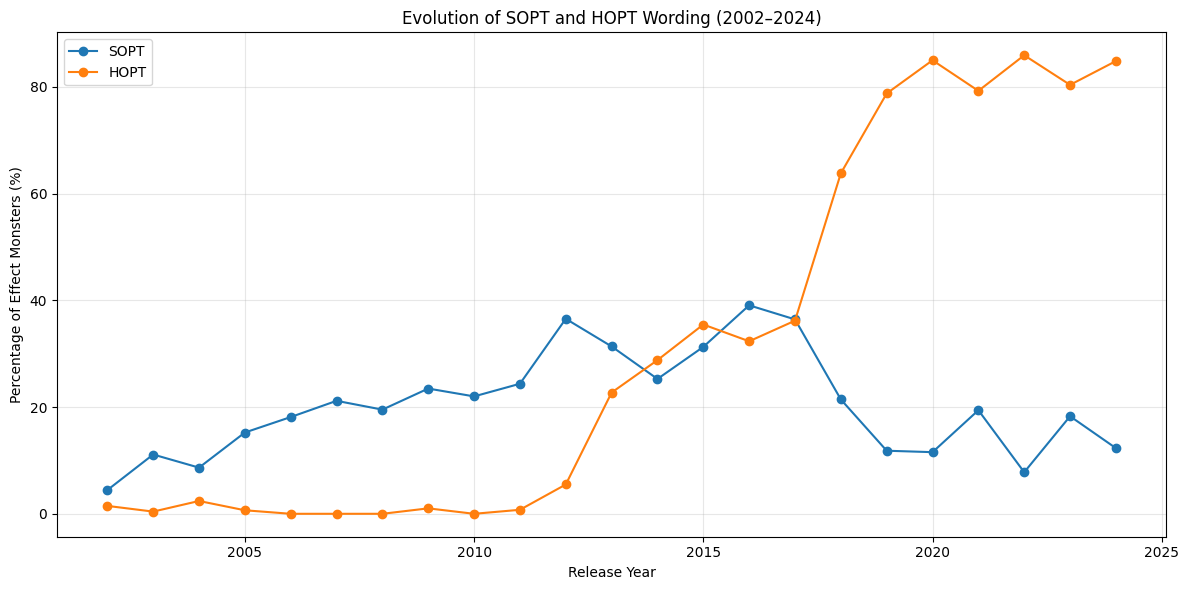

In [621]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    opt_types_by_year.index,
    opt_types_by_year["has_sopt"],
    marker="o",
    label="SOPT"
)

plt.plot(
    opt_types_by_year.index,
    opt_types_by_year["has_hopt"],
    marker="o",
    label="HOPT"
)

plt.title("Evolution of SOPT and HOPT Wording (2002–2024)")
plt.xlabel("Release Year")
plt.ylabel("Percentage of Effect Monsters (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

##### Step 5M — Investigate the 2017–2018 jump

In [622]:
effect_monsters.loc[
    effect_monsters["release_year"].isin([2017, 2018])
].groupby("release_year")["has_hopt"].agg(
    ["count", "sum", "mean"]
)

,count,sum,mean
release_year,,,
2017.0,420,152,0.361905
2018.0,420,268,0.638095


##### Step 5N — Break down HOPT by monster category

In [623]:
hopt_by_category = (
    effect_monsters[
        effect_monsters["release_year"].isin([2017, 2018])
    ]
    .groupby(["release_year", "card_category"])["has_hopt"]
    .agg(["count", "sum", "mean"])
    .round(3)
)

hopt_by_category

count  sum   mean
release_year card_category                        
2017.0       Extra Deck Monster    114   23  0.202
             Main Deck Monster     306  129  0.422
2018.0       Extra Deck Monster    150   83  0.553
             Main Deck Monster     270  185  0.685

##### Step 5O — Investigate Extra Deck summoning mechanics

In [624]:
# Compare HOPT across Extra Deck summoning mechanics

extra_2017_2018 = effect_monsters[
    (effect_monsters["release_year"].isin([2017, 2018])) &
    (effect_monsters["card_category"] == "Extra Deck Monster")
].copy()

mechanics = ["Fusion", "Synchro", "Xyz", "Link"]

for mechanic in mechanics:
    subset = extra_2017_2018[
        extra_2017_2018["type"].str.contains(
            mechanic, case=False, na=False
        )
    ]

    print(f"\n{mechanic} Monsters")
    print(
        subset.groupby("release_year")["has_hopt"]
        .agg(["count", "sum", "mean"])
        .round(3)
    )


Fusion Monsters
              count  sum   mean
release_year                   
2017.0           33    6  0.182
2018.0           22    9  0.409

Synchro Monsters
              count  sum   mean
release_year                   
2017.0           16    5  0.312
2018.0           19   12  0.632

Xyz Monsters
              count  sum   mean
release_year                   
2017.0           32    3  0.094
2018.0           10    4  0.400

Link Monsters
              count  sum   mean
release_year                   
2017.0           33    9  0.273
2018.0           99   58  0.586


##### Step 5P — Check for a dataset limitation

In [625]:
hopt_category_trend = (
    effect_monsters[
        effect_monsters["release_year"].between(2015, 2020)
    ]
    .groupby(["release_year", "card_category"])["has_hopt"]
    .mean()
    .mul(100)
    .unstack()
    .round(2)
)

hopt_category_trend

card_category,Extra Deck Monster,Main Deck Monster
release_year,,
2015.0,20.95,40.53
2016.0,14.43,37.54
2017.0,20.18,42.16
2018.0,55.33,68.52
2019.0,70.35,83.86
2020.0,74.84,90.65


##### Step 6A, Evolution of card mechanics

In [626]:
effect_monsters.columns.tolist()

['id',
 'name',
 'type',
 'desc',
 'atk',
 'def',
 'level',
 'race',
 'attribute',
 'scale',
 'archetype',
 'linkval',
 'linkmarkers',
 'image_url',
 'image_url_small',
 'ban_tcg',
 'ban_ocg',
 'ban_goat',
 'staple',
 'views',
 'viewsweek',
 'upvotes',
 'downvotes',
 'formats',
 'treated_as',
 'tcg_date',
 'ocg_date',
 'konami_id',
 'has_effect',
 'card_category',
 'monster_race',
 'spell_type',
 'trap_type',
 'level_type',
 'level_value',
 'monster_level',
 'monster_rank',
 'monster_link_rating',
 'release_year',
 'special_summon',
 'can_search',
 'can_draw',
 'can_negate',
 'can_destroy',
 'uses_gy',
 'can_banish',
 'quick_effect',
 'from_your_hand',
 'protection',
 'atk_def_cards',
 'piercing',
 'burn',
 'pay_lp',
 'lp_gain',
 'change_control',
 'change_battle_position',
 'tribute',
 'discard',
 'bounce',
 'shuffle_into_deck',
 'is_fusion',
 'is_synchro',
 'is_xyz',
 'is_pendulum',
 'is_link',
 'is_ritual',
 'effect_text_length',
 'has_opt',
 'has_hopt',
 'has_sopt']

In [627]:
# Find columns related to card mechanics

mechanic_columns = [
    col for col in effect_monsters.columns
    if any(keyword in col.lower() for keyword in [
        "summon", "search", "draw", "negate",
        "destroy", "gy", "banish", "quick"
    ])
]

mechanic_columns

['special_summon',
 'can_search',
 'can_draw',
 'can_negate',
 'can_destroy',
 'uses_gy',
 'can_banish',
 'quick_effect']

In [628]:
for col in effect_monsters.columns:
    print(col)

id
name
type
desc
atk
def
level
race
attribute
scale
archetype
linkval
linkmarkers
image_url
image_url_small
ban_tcg
ban_ocg
ban_goat
staple
views
viewsweek
upvotes
downvotes
formats
treated_as
tcg_date
ocg_date
konami_id
has_effect
card_category
monster_race
spell_type
trap_type
level_type
level_value
monster_level
monster_rank
monster_link_rating
release_year
special_summon
can_search
can_draw
can_negate
can_destroy
uses_gy
can_banish
quick_effect
from_your_hand
protection
atk_def_cards
piercing
burn
pay_lp
lp_gain
change_control
change_battle_position
tribute
discard
bounce
shuffle_into_deck
is_fusion
is_synchro
is_xyz
is_pendulum
is_link
is_ritual
effect_text_length
has_opt
has_hopt
has_sopt


##### Step 6B: Verify our indicators

In [629]:
mechanic_columns = [
    "special_summon",
    "can_search",
    "can_draw",
    "can_negate",
    "can_destroy",
    "uses_gy",
    "can_banish",
    "quick_effect"
]

effect_monsters[mechanic_columns].agg(
    ["count", "sum", "mean"]
).round(3)

,special_summon,can_search,can_draw,can_negate,can_destroy,uses_gy,can_banish,quick_effect
count,7616.000,7616.000,7616.000,7616.000,7616.000,7616.000,7616.000,7616.000
sum,4366.000,801.000,397.000,795.000,1544.000,4076.000,1207.000,868.000
mean,0.573,0.105,0.052,0.104,0.203,0.535,0.158,0.114


##### Step 6C — Analyze mechanic prevalence by year

In [630]:
mechanics_by_year = (
    effect_monsters
    .groupby("release_year")[mechanic_columns]
    .mean()
    .mul(100)
    .round(2)
)

mechanics_by_year.index = mechanics_by_year.index.astype(int)

mechanics_by_year

,special_summon,can_search,can_draw,can_negate,can_destroy,uses_gy,can_banish,quick_effect
release_year,,,,,,,,
2002,19.259259,3.703704,1.481481,0.740741,17.777778,19.259259,0.0,2.962963
2003,33.333333,2.057613,2.469136,9.876543,27.160494,28.395062,5.349794,1.646091
2004,29.807692,1.923077,5.288462,5.769231,16.826923,38.461538,5.288462,1.442308
2005,38.410596,1.324503,3.311258,3.97351,17.880795,31.125828,3.311258,0.662252
2006,41.520468,1.169591,4.678363,7.017544,15.789474,35.672515,2.339181,1.169591
2007,38.288288,6.306306,5.855856,3.603604,29.72973,49.54955,5.855856,1.351351
2008,43.150685,3.082192,4.452055,8.219178,24.657534,50.684932,8.219178,2.054795
2009,42.857143,4.761905,4.421769,7.482993,25.170068,50.340136,4.761905,1.360544
2010,38.875306,7.823961,4.645477,7.334963,19.804401,48.899756,6.601467,2.200489


##### Step 6d

In [631]:
effect_monsters.loc[
    effect_monsters["special_summon"] == 1,
    ["name", "release_year", "desc"]
].sample(10, random_state=42)

,name,release_year,desc
4776,Ghost Sister & Spooky Dogwood,2019.0,"During either turn, except the End Phase (Quick Effect): You can discard this card; apply this effect this turn. You can only use this effect of ""Ghost Sister & Spooky Dogwood"" once per turn.\r\n● Each time your opponent Special Summons an Effect Monster(s) during the Main Phase or Battle Phase, you gain LP equal to that monster's ATK. If you did not gain LP by this effect, your LP are halved during the End Phase."
1738,Chaos Beast,2023.0,"1 LIGHT Tuner + 1+ non-Tuner DARK monsters\r\nIf any card(s) have been banished this turn, this card gains 1000 ATK. You can only use each of the following effects of ""Chaos Beast"" once per turn. You can target 1 of your banished LIGHT or DARK monsters; add it to your hand. During your Main Phase, except the turn this card was sent to the GY: You can banish 1 LIGHT and 1 DARK monster from your hand and/or GY, except this card; Special Summon this card from your GY."
1889,Clear Wing Fast Dragon,2017.0,"[ Pendulum Effect ] \nYou can send 1 face-up ""Speedroid"" Tuner and 1 face-up non-Tuner monster you control to the GY, whose total Levels equal 7; Special Summon this card from your Pendulum Zone. You can only use this effect of ""Clear Wing Fast Dragon"" once per turn.\n[ Monster Effect ] \n1 Tuner + 1+ non-Tuner WIND monsters\r\n(Quick Effect): You can target 1 face-up monster your opponent controls that was Special Summoned from the Extra Deck; until the end of this turn, change its ATK to 0, also negate that face-up monster's effects. You can only use this effect of ""Clear Wing Fast Dragon"" once per turn. If this card in the Monster Zone is destroyed by battle or card effect: You can place this card in your Pendulum Zone."
9603,Revolution Synchron,2023.0,"If you Synchro Summon a ""Power Tool"" monster or a Level 7 or 8 Dragon monster, this card in your hand can also be used as material. You can only use this effect of ""Revolution Synchron"" once per turn. If you control a Level 7 or higher Synchro Monster while this card is in your GY: You can send the top card of your Deck to the GY, and if you do, Special Summon this card, also its Level becomes 1. You can only use this effect of ""Revolution Synchron"" once per Duel."
4929,Gladiator Beast Augustus,2014.0,"When this card is Special Summoned by the effect of a ""Gladiator Beast"" monster: You can Special Summon 1 ""Gladiator Beast"" monster from your hand in Defense Position. Shuffle it into the Deck during the End Phase. At the end of the Battle Phase, if this card attacked or was attacked: You can shuffle it into the Deck; Special Summon 1 ""Gladiator Beast"" monster from your Deck, except ""Gladiator Beast Augustus""."
10608,Speaker for the Ice Barriers,2021.0,"While you control another ""Ice Barrier"" monster, Defense Position monsters your opponent controls cannot change their battle positions. You can only use each of the following effects of ""Speaker for the Ice Barriers"" once per turn. If you control an ""Ice Barrier"" monster: You can Special Summon this card from your hand. If you control an ""Ice Barrier"" monster: You can banish this card from your GY; Special Summon 1 ""Ice Barrier Token"" (Aqua/WATER/Level 1/ATK 0/DEF 0)."
4558,Galaxy Worm,2017.0,"When this card is Normal Summoned while you control no other monsters: You can Special Summon 1 Level 3 or lower ""Galaxy"" Effect Monster from your Deck, but it has its effects negated."
3180,Dotscaper,2017.0,"If this card is sent to the GY: You can Special Summon this card. If this card is banished: You can Special Summon this card. You can only use 1 ""Dotscaper"" effect per turn, and only once that turn. You can only use each effect of ""Dotscaper"" once per Duel."
6921,Magicore Warrior of the Relics,2022.0,"Cannot attack unless you control an ""Adventurer Token"". You can only use each of the following effects of ""Magicore Warrior of the Relics"" once per turn. If you control an ""Adventurer Token"": 

##### Step 6e: Improving our Special Summoning indicator

In [632]:
effect_monsters["mentions_special_summon"] = (
    effect_monsters["special_summon"].copy()
)

effect_monsters["mentions_special_summon"].value_counts()

mentions_special_summon
True     4366
False    3250
Name: count, dtype: int64

##### Step 6F: Examine Special Summoning language

In [633]:
effect_monsters.loc[
    effect_monsters["mentions_special_summon"],
    ["name", "desc"]
].sample(15, random_state=25)

,name,desc
2459,D/D/D Gust King Alexander,"1 ""D/D"" Tuner + 1 or more non-Tuner monsters\nIf another ""D/D"" monster(s) is Normal or Special Summoned to your field, while you control this face-up card (except during the Damage Step): You can target 1 Level 4 or lower ""D/D"" monster in your Graveyard; Special Summon it. You can only use this effect of ""D/D/D Gust King Alexander"" once per turn."
6425,Latency,"If this card is added from your GY to your hand by a card effect: You can Special Summon it from your hand. If this card Summoned this way is sent to the GY as Link Material: You can draw 1 card. You can only use each effect of ""Latency"" once per turn."
421,Ancient Gear Megaton Golem,"3 ""Ancient Gear"" monsters\r\nIf this card attacks, your opponent cannot activate Spell/Trap Cards until the end of the Damage Step. If this card was Fusion Summoned using 2 or more ""Ancient Gear Golem"" and/or ""Ancient Gear Golem - Ultimate Pound"" as material, it can attack up to that many times during each Battle Phase. If this face-up Fusion Summoned card in its owner's control leaves the field because of an opponent's card effect: You can Special Summon 1 ""Ultimate Ancient Gear Golem"" from your Extra Deck, ignoring its Summoning conditions."
11085,Superancient Deepsea King Coelacanth,"Once per turn: You can discard 1 card; Special Summon as many Level 4 or lower Fish-Type monsters as possible from your Deck, but they cannot declare an attack and their effects are negated. During either player's turn, when this face-up card on the field is targeted by a card effect: You can Tribute 1 other Fish-Type monster; negate the activation, and if you do, destroy that card."
7197,Mayosenju Daibak,"[ Pendulum Effect ] \nWhen a ""Yosenju"" monster you control declares an attack: You can have that attacking monster gain 300 ATK until the end of the Battle Phase.\n[ Monster Effect ] \nCannot be Special Summoned, except by Pendulum Summon. This card's Pendulum Summon cannot be negated. If this card is Normal or Special Summoned: You can target up to 2 cards on the field; return them to the hand. Once per turn, during the End Phase, if this card was Special Summoned this turn: Return it to the hand."
8753,Phantom Magician,"When this card is destroyed by battle and sent to the Graveyard: You can Special Summon 1 ""HERO"" monster with 1000 or less ATK from your Deck in face-up Defense Position."
2103,"Crealtar, the Impcantation Originator","You can Ritual Summon this card with ""Impcantation Inception"". During the Main Phase (Quick Effect): You can reveal this card in your hand; discard 1 card, then Special Summon ""Impcantation"" monsters from your GY whose total Levels equal 10, but shuffle them into the Deck during the End Phase. You can only use this effect of ""Crealtar, the Impcantation Originator"" once per turn. Non-Ritual ""Impcantation"" monsters you control gain 2000 ATK, but their effects are negated."
7413,Metaphys Nephthys,"If this card is Special Summoned by the effect of a ""Metaphys"" monster: You can banish all Set Spells and Traps on the field. If this card is banished, during the Standby Phase of the next turn: You can shuffle this banished card into the Deck; add 1 ""Metaphys"" card from your Deck to your hand, except ""Metaphys Nephthys""."
9443,Red-Eyes Black Metal Dragon,"Cannot be Normal Summoned/Set. Must first be Special Summoned (from your Deck) by Tributing ""Red-Eyes B. Dragon"" equipped with ""Metalmorph""."
4172,Fishborg Blaster,"If you control a face-up Level 3 or lower WATER monster: You can discard 1 card; Special Summon this card from your Graveyard. If this card is used as a Synchro Material Monster, all other Synchro Material Monsters must be WATER."


In [634]:
import re

summon_pattern = (
    r"(?<!cannot be )(?<!cannot )"
    r"(?<!can't be )"
    r"(?<!cannot be )Special Summon "
    r"(?:this card|it|them|1 |2 |up to |"
    r"as many |\"|a |any number)"
    r"|Must (?:first )?be Special Summoned"
)

effect_monsters["can_special_summon"] = (
    effect_monsters["desc"]
    .fillna("")
    .str.contains(summon_pattern, case=False, regex=True)
)

effect_monsters["can_special_summon"].value_counts()

can_special_summon
False    4286
True     3330
Name: count, dtype: int64

In [635]:
excluded_cards = effect_monsters[
    (effect_monsters["mentions_special_summon"] == True) &
    (effect_monsters["can_special_summon"] == False)
]

print("Excluded cards:", len(excluded_cards))

excluded_cards[
    ["name", "release_year", "desc"]
].sample(15, random_state=42)

Excluded cards: 1036


,name,release_year,desc
7700,Mulcharmy Purulia,2024.0,"If you control no cards (Quick Effect): You can discard this card; apply these effects this turn.\r\n● Each time your opponent Normal or Special Summons a monster(s) from the hand, immediately draw 1 card.\r\n● Once, during this End Phase, if the number of cards in your hand is more than the number of cards your opponent controls +6, you must randomly shuffle cards from your hand into the Deck so the number in your hand equals the number your opponent controls +6.\r\nYou can only activate 1 other ""Mulcharmy"" monster effect, the turn you activate this effect."
1248,Blazing Bombardment Beast,2024.0,"1 Machine monster + 1 Pyro monster\r\nIf this card is Special Summoned: You can destroy all monsters your opponent controls with 1900 or less ATK. If this card is sent to the GY: You can target 1 monster your opponent controls with 1900 or less ATK; destroy that monster, and if you do, inflict damage to your opponent equal to its original ATK. You can only use each effect of ""Blazing Bombardment Beast"" once per turn."
7992,Ninja Grandmaster Hanzo,2012.0,"When this card is Normal Summoned: You can add 1 ""Ninjitsu Art"" card from your Deck to your hand. When this card is Flip or Special Summoned: You can add 1 ""Ninja"" monster from your Deck to your hand, except ""Ninja Grandmaster Hanzo""."
5309,Guiding Light,2014.0,When this card is Normal Summoned: You can target 1 Level 1 LIGHT monster in your GY; Special Summon that target.
6439,Laval Cannon,2012.0,"When this card is Normal or Flip Summoned: You can target 1 of your banished ""Laval"" monsters; Special Summon that target."
6093,Junk Synchron,2008.0,"When this card is Normal Summoned: You can target 1 Level 2 or lower monster in your Graveyard; Special Summon that target in Defense Position, but it has its effects negated."
1183,Blackwing - Decay the Ill Wind,2016.0,"Once per turn, during the End Phase, if this card is in the Graveyard because it was sent there this turn: Take 1000 damage. When this card is Normal or Special Summoned: You can target 1 ""Blackwing"" monster you control, then activate 1 of these effects;\n● Increase its Level by 1.\n● Reduce its Level by 1.\nYou can only use this effect of ""Blackwing - Decay the Ill Wind"" once per turn."
6234,King Tiger Wanghu,2003.0,When a monster(s) with 1400 or less ATK is Normal Summoned or Special Summoned: Destroy those monsters with 1400 or less ATK. This card must be face-up on the field to activate and to resolve this effect.
8963,Predaplant Squid Drosera,2016.0,"You can send this card from your hand to the Graveyard, then target 1 face-up monster you control; this turn, it can attack all monsters your opponent controls with a Predator Counter, once each. If this face-up card leaves the field: Place 1 Predator Counter on each Special Summoned monster your opponent controls, and if you do, any of those monsters that are Level 2 or higher become Level 1 as long as they have a Predator Counter."
12890,Witch Doctor of Sparta,2007.0,Inflict 500 damage to your opponent each time a monster(s) is Special Summoned from either player's Deck.


In [636]:
summon_pattern_v2 = (
    r"Special Summon (?:"
    r"this card|it|them|that target|those targets|"
    r"\d+ |up to |as many |a |\"|"
    r"any number|monsters"
    r")"
    r"|Must (?:first )?be Special Summoned"
    r"|or Special Summoned .*?by Tributing"
)

effect_monsters["can_special_summon_v2"] = (
    effect_monsters["desc"]
    .fillna("")
    .str.contains(
        summon_pattern_v2,
        case=False,
        regex=True
    )
)

effect_monsters["can_special_summon_v2"].value_counts()

can_special_summon_v2
False    4084
True     3532
Name: count, dtype: int64

In [637]:
test_cards = [
    "Guiding Light",
    "Laval Cannon",
    "Junk Synchron",
    "Masked Chameleon",
    "Thunder Dragon Colossus"
]

effect_monsters.loc[
    effect_monsters["name"].isin(test_cards),
    [
        "name",
        "mentions_special_summon",
        "can_special_summon",
        "can_special_summon_v2"
    ]
]

,name,mentions_special_summon,can_special_summon,can_special_summon_v2
5309,Guiding Light,True,False,True
6093,Junk Synchron,True,False,True
6439,Laval Cannon,True,False,True
7128,Masked Chameleon,True,False,True
11750,Thunder Dragon Colossus,True,False,True


In [638]:
newly_detected = effect_monsters[
    (~effect_monsters["can_special_summon"]) &
    (effect_monsters["can_special_summon_v2"])
]

print("Newly detected cards:", len(newly_detected))

newly_detected[
    ["name", "release_year", "desc"]
].sample(15, random_state=42)

Newly detected cards: 202


,name,release_year,desc
5962,Inzektor Giga-Weevil,2012.0,"You can target 1 face-up ""Inzektor"" monster you control; equip this card from your hand to that target. While this card is equipped to a monster, that monster's original DEF becomes 2600. If this card is sent to the Graveyard while equipped to a monster: You can target 1 ""Inzektor"" monster in your Graveyard; Special Summon that target. This effect of ""Inzektor Giga-Weevil"" can only be used once per turn."
958,Battlewasp - Dart the Hunter,2019.0,"When your ""Battlewasp"" monster destroys a monster by battle that is owned by your opponent: You can discard this card; inflict damage to your opponent equal to that destroyed monster's original ATK. You can target 1 other Insect monster you control; it is treated as a Tuner this turn, also you cannot Special Summon monsters from the Extra Deck for the rest of this turn, except Insect monsters. You can only use each effect of ""Battlewasp - Dart the Hunter"" once per turn."
1381,Brain Crusher,2007.0,"Once per turn, during the End Phase, if this card destroyed an opponent's monster by battle and sent it to the Graveyard this turn while you controlled it: You can target 1 of those destroyed monsters in the Graveyard; Special Summon that target."
10571,Soul Resonator,2023.0,"If this card is Normal or Special Summoned: You can add 1 Level 4 or lower Fiend monster from your Deck to your hand, except ""Soul Resonator"", also you cannot Special Summon monsters from the Extra Deck for the rest of this turn, except DARK Synchro Monsters. If a card(s) you control would be destroyed by card effect, while you control ""Red Dragon Archfiend"" or a Synchro Monster that mentions it, you can banish this card from your GY instead. You can only use each effect of ""Soul Resonator"" once per turn."
12636,Vylon Hept,2012.0,"Once per turn: You can target 1 ""Vylon"" Monster Card you control that is an Equip Card; Special Summon that target in face-up Defense Position. Banish it when it leaves the field."
7128,Masked Chameleon,2013.0,"Cannot be Normal Summoned if you control a Level 5 or higher monster. When this card is Normal Summoned: You can target 1 monster with 0 DEF in your Graveyard; Special Summon that target in face-up Defense Position. Its effects are negated. You cannot Special Summon any other monsters, except from the Extra Deck, during the turn you activate this effect."
4361,Fossil Dyna Pachycephalo,2008.0,If this card is flipped face-up: Destroy all Special Summoned monsters on the field. Neither player can Special Summon monsters.
11455,Testudo erat Numen,2010.0,Neither player can Special Summon monsters with 1800 or more ATK.
10633,Speedroid Marble Machine,2020.0,"[ Pendulum Effect ] \nOnce per turn, when your Defense Position monster is targeted for an attack: You can change it to face-up Attack Position, also it cannot be destroyed by battle this turn (even if this card leaves the field).\n[ Monster Effect ] \nWhen this card is Normal Summoned: You can activate this effect; add 1 ""Speedroid"" monster from your Deck to your hand, also you cannot Special Summon monsters for the rest of this turn, except WIND monsters. You can only use this effect of ""Speedroid Marble Machine"" once per turn."
2269,Cyber Dragon Herz,2018.0,"This card's name becomes ""Cyber Dragon"" while on the field or in the GY. You can only use 1 of the following effects of ""Cyber Dragon Herz"" per turn, and only once that turn.\r\n● If this card is Special Summoned: You can make this card's Level become 5 until the end of this turn, also, you cannot Special Summon monsters for the rest of this turn, except Machine monsters. \r\n● If this card is sent to the GY: You can add 1 other ""Cyber Dragon"" from your Deck or GY to your hand."


In [639]:
import re

def extract_summon_clauses(text):
    if not isinstance(text, str):
        return []

    clauses = re.split(r"[.;:\n]", text)

    return [
        clause.strip()
        for clause in clauses
        if re.search(r"special summon", clause, re.I)
    ]

test_names = [
    "Fossil Dyna Pachycephalo",
    "Soul Resonator",
    "Junk Synchron",
    "Inzektor Giga-Weevil",
    "Thunder Dragon Colossus"
]

for _, card in effect_monsters[
    effect_monsters["name"].isin(test_names)
].iterrows():
    print(f"\n{card['name']}")
    for clause in extract_summon_clauses(card["desc"]):
        print("-", clause)


Fossil Dyna Pachycephalo
- Destroy all Special Summoned monsters on the field
- Neither player can Special Summon monsters

Inzektor Giga-Weevil
- Special Summon that target

Junk Synchron
- Special Summon that target in Defense Position, but it has its effects negated

Soul Resonator
- If this card is Normal or Special Summoned
- You can add 1 Level 4 or lower Fiend monster from your Deck to your hand, except "Soul Resonator", also you cannot Special Summon monsters from the Extra Deck for the rest of this turn, except DARK Synchro Monsters

Thunder Dragon Colossus
- Must be either Fusion Summoned, or Special Summoned during the turn a Thunder monster's effect was activated in the hand, by Tributing 1 Thunder Effect non-Fusion Monster (in which case you do not use "Polymerization")


In [640]:
import re

def detects_special_summon(text):
    if not isinstance(text, str):
        return False

    clauses = re.split(r"[.;:\n]", text)

    for clause in clauses:
        clause = clause.strip()

        # Ignore clauses without Special Summoning
        if not re.search(r"special summon", clause, re.I):
            continue

        # Detect alternative Summoning procedures
        if re.search(
            r"must (?:first )?be .*?special summoned",
            clause,
            re.I
        ):
            return True

        # Detect active Special Summoning actions
        match = re.search(
            r"\bspecial summon\b(?!ed|ing)",
            clause,
            re.I
        )

        if match:
            prefix = clause[:match.start()]

            # Exclude common restrictions
            if re.search(
                r"(?:cannot|can't|neither player can|"
                r"your opponent cannot|you cannot)\s*$",
                prefix,
                re.I
            ):
                continue

            # Exclude references to opponent's actions
            if re.search(
                r"(?:opponent|each time|whenever).*?$",
                prefix,
                re.I
            ):
                continue

            return True

    return False


effect_monsters["can_special_summon_v3"] = (
    effect_monsters["desc"]
    .apply(detects_special_summon)
)

effect_monsters["can_special_summon_v3"].value_counts()

can_special_summon_v3
False    4046
True     3570
Name: count, dtype: int64

In [641]:
validation_cards = {
    "Junk Synchron": True,
    "Inzektor Giga-Weevil": True,
    "Thunder Dragon Colossus": True,
    "Fantastical Dragon Phantazmay": True,
    "Guiding Light": True,
    "Fossil Dyna Pachycephalo": False,
    "Soul Resonator": False,
    "Ghost Sister & Spooky Dogwood": False,
    "King Tiger Wanghu": False,
    "Mulcharmy Purulia": False
}

validation = effect_monsters[
    effect_monsters["name"].isin(validation_cards)
][["name", "can_special_summon_v3"]].copy()

validation["expected"] = validation["name"].map(validation_cards)

validation["correct"] = (
    validation["can_special_summon_v3"] == validation["expected"]
)

print("Correct:", validation["correct"].sum())
print("Total:", len(validation))

validation

Correct: 10
Total: 10


,name,can_special_summon_v3,expected,correct
4019,Fantastical Dragon Phantazmay,True,True,True
4361,Fossil Dyna Pachycephalo,False,False,True
4776,Ghost Sister & Spooky Dogwood,False,False,True
5309,Guiding Light,True,True,True
5962,Inzektor Giga-Weevil,True,True,True
6093,Junk Synchron,True,True,True
6234,King Tiger Wanghu,False,False,True
7700,Mulcharmy Purulia,False,False,True
10571,Soul Resonator,False,False,True
11750,Thunder Dragon Colossus,True,True,True


In [642]:
random_validation = effect_monsters[
    ["name", "release_year", "desc", "can_special_summon_v3"]
].sample(20, random_state=625)

for _, card in random_validation.iterrows():
    print("=" * 70)
    print("Card:", card["name"])
    print("Year:", int(card["release_year"]))
    print("V3 Prediction:", card["can_special_summon_v3"])
    print("Effect:", card["desc"])
    print()

Card: Shadowpriestess of Ohm
Year: 2008
V3 Prediction: False
Effect: You can Tribute 1 face-up DARK monster you control to inflict 800 damage to your opponent.

Card: Firewall Dragon Darkfluid - Neo Tempest Terahertz
Year: 2023
V3 Prediction: False
Effect: 3+ Cyberse monsters
Negate any monster effects activated by your opponent during the Battle Phase. (Quick Effect): You can send 1 Cyberse monster from your Deck or Extra Deck to the GY, and if you do, this card gains the Attribute of that monster sent to the GY, also it gains 2500 ATK. You can only use this effect of "Firewall Dragon Darkfluid - Neo Tempest Terahertz" once per turn. This card can attack monsters a number of times each Battle Phase, up to the number of different Attributes it has.

Card: Megalith Aratron
Year: 2020
V3 Prediction: False
Effect: You can Ritual Summon this card with a "Megalith" card. During the Main Phase (Quick Effect): You can discard this card; Ritual Summon 1 "Megalith" Ritual Monster from your hand

In [643]:
for _, card in random_validation.iterrows():
    print("=" * 50)
    print("Card:", card["name"])
    print("V3:", card["can_special_summon_v3"])

    clauses = extract_summon_clauses(card["desc"])

    if clauses:
        for clause in clauses:
            print("Effect:", clause)
    else:
        print("No Special Summoning text detected")

    print()

Card: Shadowpriestess of Ohm
V3: False
No Special Summoning text detected

Card: Firewall Dragon Darkfluid - Neo Tempest Terahertz
V3: False
No Special Summoning text detected

Card: Megalith Aratron
V3: False
No Special Summoning text detected

Card: Flower Cardian Clover with Boar
V3: True
Effect: Must first be Special Summoned (from your hand) by Tributing 1 "Flower Cardian" monster, except "Flower Cardian Clover with Boar"
Effect: If this card is Special Summoned

Card: Clear Kuriboh
V3: True
Effect: draw 1 card, and if it is a monster, you can Special Summon it, then change the attack target to it

Card: Trident Warrior
V3: True
Effect: You can Special Summon 1 Level 3 monster from your hand

Card: Jurrac Titano
V3: False
Effect: Cannot be Special Summoned

Card: Orcust Brass Bombard
V3: True
Effect: Special Summon 1 "Orcust" monster from your hand, except "Orcust Brass Bombard", also you cannot Special Summon monsters for the rest of this turn, except DARK monsters

Card: Teardro

In [644]:
validation_export = random_validation.copy()

validation_export["summon_clauses"] = (
    validation_export["desc"]
    .apply(extract_summon_clauses)
    .apply(lambda x: " | ".join(x))
)

validation_export[
    ["name", "release_year", "can_special_summon_v3", "summon_clauses"]
].to_csv(
    "special_summon_validation.csv",
    index=False
)

print("Validation file saved!")

Validation file saved!


In [645]:
summon_trends = (
    effect_monsters
    .groupby("release_year")[
        ["mentions_special_summon", "can_special_summon_v3"]
    ]
    .mean()
    .mul(100)
    .round(2)
)

summon_trends.columns = [
    "Mentions Special Summoning (%)",
    "Can Special Summon V3 (%)"
]

summon_trends

,Mentions Special Summoning (%),Can Special Summon V3 (%)
release_year,,
2002.0,19.259259,14.81
2003.0,33.333333,23.05
2004.0,29.807692,24.04
2005.0,38.410596,30.46
2006.0,41.520468,27.49
2007.0,38.288288,26.58
2008.0,43.150685,35.62
2009.0,42.857143,29.93
2010.0,38.875306,28.36


In [649]:
effect_monsters["is_extra_deck"] = (
    effect_monsters[
        ["is_fusion", "is_synchro", "is_xyz", "is_link"]
    ].any(axis=1)
)

effect_monsters["deck_type"] = (
    effect_monsters["is_extra_deck"]
    .map({True: "Extra Deck", False: "Main Deck"})
)

effect_monsters["deck_type"].value_counts()

deck_type
Main Deck     5831
Extra Deck    1785
Name: count, dtype: int64

In [652]:
summon_by_deck = (
    effect_monsters
    .groupby(["release_year", "deck_type"])["can_special_summon_v3"]
    .agg(["mean", "count"])
    .reset_index()
)

summon_by_deck["percentage"] = (
    summon_by_deck["mean"] * 100
).round(2)

summon_comparison = summon_by_deck.pivot(
    index="release_year",
    columns="deck_type",
    values="percentage"
)

summon_comparison

deck_type,Extra Deck,Main Deck
release_year,,
2002.0,0.00,14.93
2003.0,53.85,21.30
2004.0,33.33,23.90
2005.0,64.29,27.01
2006.0,63.16,23.03
2007.0,70.59,22.93
2008.0,53.33,33.59
2009.0,30.30,29.89
2010.0,20.97,29.68


In [653]:
deck_sample_sizes = summon_by_deck.pivot(
    index="release_year",
    columns="deck_type",
    values="count"
)

deck_sample_sizes

deck_type,Extra Deck,Main Deck
release_year,,
2002.0,1,134
2003.0,13,230
2004.0,3,205
2005.0,14,137
2006.0,19,152
2007.0,17,205
2008.0,30,262
2009.0,33,261
2010.0,62,347


In [654]:
effect_monsters["has_summoning_ability"] = (
    effect_monsters["can_special_summon_v3"]
)

print(
    effect_monsters["has_summoning_ability"]
    .value_counts()
)

print(
    "Percentage:",
    round(
        effect_monsters["has_summoning_ability"].mean() * 100,
        2
    )
)

has_summoning_ability
False    4046
True     3570
Name: count, dtype: int64
Percentage: 46.88


In [655]:
print(effect_monsters["can_search"].value_counts())

search_examples = effect_monsters[
    ["name", "desc", "can_search"]
].sample(10, random_state=625)

for _, card in search_examples.iterrows():
    print("=" * 60)
    print("Card:", card["name"])
    print("Search:", card["can_search"])
    print("Effect:", card["desc"][:350])
    print()

can_search
False    6815
True      801
Name: count, dtype: int64
Card: Shadowpriestess of Ohm
Search: False
Effect: You can Tribute 1 face-up DARK monster you control to inflict 800 damage to your opponent.

Card: Firewall Dragon Darkfluid - Neo Tempest Terahertz
Search: False
Effect: 3+ Cyberse monsters
Negate any monster effects activated by your opponent during the Battle Phase. (Quick Effect): You can send 1 Cyberse monster from your Deck or Extra Deck to the GY, and if you do, this card gains the Attribute of that monster sent to the GY, also it gains 2500 ATK. You can only use this effect of "Firewall Dragon Darkfluid - N

Card: Megalith Aratron
Search: False
Effect: You can Ritual Summon this card with a "Megalith" card. During the Main Phase (Quick Effect): You can discard this card; Ritual Summon 1 "Megalith" Ritual Monster from your hand, by Tributing monsters from your hand or field whose total Levels equal or exceed its Level. When your opponent activates a card or effect t

In [656]:
search_candidates = effect_monsters[
    effect_monsters["desc"].str.contains(
        r"add .*? from your Deck .*? to your hand",
        case=False,
        regex=True,
        na=False
    )
]

print("Potential searchers:", len(search_candidates))

search_candidates[
    ["name", "can_search", "desc"]
].sample(
    min(10, len(search_candidates)),
    random_state=625
).apply(
    lambda row: print(
        f"\nCard: {row['name']}\n"
        f"Original: {row['can_search']}\n"
        f"Effect: {row['desc'][:250]}"
    ),
    axis=1
)

Potential searchers: 92

Card: Performapal Trump Witch
Original: False
Effect: [ Pendulum Effect ] 
Once per turn: You can Fusion Summon 1 Fusion Monster from your Extra Deck, using monsters you control as Fusion Materials.
[ Monster Effect ] 
You can Tribute this card; add 1 "Polymerization" from your Deck or Graveyard to your

Card: Cattycorn
Original: True
Effect: If this card is Special Summoned while you control no card in your Field Zone: You can add 1 Field Spell from your Deck to your hand. If this card is destroyed by battle or card effect and sent to the GY: You can target 1 Field Spell in your GY; add 

Card: Magician's Rod
Original: True
Effect: When this card is Normal Summoned: You can add 1 Spell/Trap from your Deck to your hand, that specifically lists the card "Dark Magician" in its text. During your opponent's turn, if you activate a Spell/Trap Card or effect while this card is in your

Card: Plunder Patrollship Jord
Original: True
Effect: [ Pendulum Effect ] 
You can

8700     None
1667     None
6912     None
8850     None
10253    None
1295     None
6151     None
5600     None
2968     None
9444     None
dtype: object

In [658]:
missed_searchers = search_candidates[
    search_candidates["can_search"] == False
]

print("Potential searchers:", len(search_candidates))
print("Missed by original:", len(missed_searchers))

print(
    missed_searchers[
        ["name", "can_search"]
    ].to_string(index=False)
)

Potential searchers: 92
Missed by original: 48
                                        name can_search
              Amazement Abomination Arlekino      False
                 Arcana Force XV - The Fiend      False
                     Aron, the Ogdoadic King      False
                          Beast-Warrior Puma      False
            Buster Gundil the Cubic Behemoth      False
                           Bystial Magnamhut      False
                    Chronomaly Crystal Skull      False
                          Cyber Angel Idaten      False
                           Cyber Dragon Herz      False
                          Dimension Conjurer      False
                     Double Disruptor Dragon      False
                                   Dupe Frog      False
               Earthbound Greater Linewalker      False
             Earthbound Prisoner Line Walker      False
               Earthbound Servant Geo Kraken      False
                       El Shaddoll Apkallone      False
 

In [659]:
test_search_cards = [
    "Bystial Magnamhut",
    "Gear Gigant X",
    "Volcanic Rocket",
    "Cyber Dragon Herz",
    "Performapal Trump Witch"
]

for _, card in effect_monsters[
    effect_monsters["name"].isin(test_search_cards)
].iterrows():

    print("=" * 60)
    print("Card:", card["name"])
    print("Original:", card["can_search"])
    print("Effect:", card["desc"])
    print()

Card: Bystial Magnamhut
Original: False
Effect: You can target 1 LIGHT or DARK monster in either GY; banish it, and if you do, Special Summon this card from your hand. This is a Quick Effect if your opponent controls a monster. If this card is Special Summoned: You can activate this effect; during the End Phase of this turn, add 1 Dragon monster from your Deck or GY to your hand, except "Bystial Magnamhut". You can only use each effect of "Bystial Magnamhut" once per turn.

Card: Cyber Dragon Herz
Original: False
Effect: This card's name becomes "Cyber Dragon" while on the field or in the GY. You can only use 1 of the following effects of "Cyber Dragon Herz" per turn, and only once that turn.
● If this card is Special Summoned: You can make this card's Level become 5 until the end of this turn, also, you cannot Special Summon monsters for the rest of this turn, except Machine monsters. 
● If this card is sent to the GY: You can add 1 other "Cyber Dragon" from your Deck or GY to your ha

In [660]:
import re

def detects_search(text):
    if not isinstance(text, str):
        return False

    # Split card effects into clauses
    clauses = re.split(r"[.;:\n]", text)

    for clause in clauses:
        clause = clause.strip()

        # Find an "add" action followed by "to your hand"
        matches = re.finditer(
            r"\badd\b[^.;:\n]*?\bto your hand\b",
            clause,
            re.I
        )

        for match in matches:
            action = match.group()

            # Deck must be a possible source
            if re.search(
                r"\bfrom (?:your|the) Deck\b",
                action,
                re.I
            ):
                return True

    return False


effect_monsters["can_search_v2"] = (
    effect_monsters["desc"].apply(detects_search)
)

print(effect_monsters["can_search_v2"].value_counts())

can_search_v2
False    6789
True      827
Name: count, dtype: int64


In [661]:
# Make sure both columns are Boolean
v1 = effect_monsters["can_search"].astype(bool)
v2 = effect_monsters["can_search_v2"].astype(bool)

# Cards detected by V2 but missed by V1
new_searchers = effect_monsters[v2 & ~v1]

# Cards detected by V1 but missed by V2
lost_searchers = effect_monsters[v1 & ~v2]

print("Detected by both:", (v1 & v2).sum())
print("Newly detected by V2:", len(new_searchers))
print("Detected by V1 but missed by V2:", len(lost_searchers))

print("\nExamples newly detected by V2:")
print(new_searchers["name"].head(10).to_string(index=False))

print("\nExamples missed by V2:")
print(lost_searchers["name"].head(10).to_string(index=False))

Detected by both: 780
Newly detected by V2: 47
Detected by V1 but missed by V2: 21

Examples newly detected by V2:
  Amazement Abomination Arlekino
     Arcana Force XV - The Fiend
         Aron, the Ogdoadic King
Buster Gundil the Cubic Behemoth
               Bystial Magnamhut
        Chronomaly Crystal Skull
              Cyber Angel Idaten
               Cyber Dragon Herz
              Dimension Conjurer
         Double Disruptor Dragon

Examples missed by V2:
Blackwing - Breeze the Zephyr
                Bujin Arasuda
        Dark Infant @Ignister
             Doshin @Ignister
          F.A. Auto Navigator
       Gagaku-P.U.N.K. Wa Gon
Joruri-P.U.N.K. Madame Spider
      Noh-P.U.N.K. Ogre Dance
         Noh-P.U.N.K. Ze Amin
             Pikari @Ignister


In [662]:
print("Cards detected by V1 but missed by V2:\n")

for _, card in lost_searchers.iterrows():
    print("=" * 60)
    print("Card:", card["name"])

    # Show the full description
    print("Effect:", card["desc"])
    print()

Cards detected by V1 but missed by V2:

Card: Blackwing - Breeze the Zephyr
Effect: If this card is added from your Deck to your hand by a card effect: You can Special Summon this card from your hand. Cannot be used as a Synchro Material, except for the Synchro Summon of a "Blackwing" monster.

Card: Bujin Arasuda
Effect: If a "Bujin" monster in your Graveyard or face-up on your side of the field is banished (except during the Damage Step): You can Special Summon this card from your hand in face-up Defense Position. Once per turn, during the End Phase, if a "Bujin" card was added from your Deck to your hand this turn, except by drawing it, while you controlled this face-up card: You can draw 1 card, then discard 1 card. You can only control 1 "Bujin Arasuda".

Card: Dark Infant @Ignister
Effect: 1 non-Link "@Ignister" monster
If this card is Link Summoned: You can add 1 "Ignister A.I.Land" from your Deck to your hand. When a Cyberse monster with 2300 original ATK activates its effect (

In [663]:
for _, card in lost_searchers.head(5).iterrows():
    print("=" * 60)
    print("Card:", card["name"])
    print("Effect:", card["desc"])
    print()


Card: Blackwing - Breeze the Zephyr
Effect: If this card is added from your Deck to your hand by a card effect: You can Special Summon this card from your hand. Cannot be used as a Synchro Material, except for the Synchro Summon of a "Blackwing" monster.

Card: Bujin Arasuda
Effect: If a "Bujin" monster in your Graveyard or face-up on your side of the field is banished (except during the Damage Step): You can Special Summon this card from your hand in face-up Defense Position. Once per turn, during the End Phase, if a "Bujin" card was added from your Deck to your hand this turn, except by drawing it, while you controlled this face-up card: You can draw 1 card, then discard 1 card. You can only control 1 "Bujin Arasuda".

Card: Dark Infant @Ignister
Effect: 1 non-Link "@Ignister" monster
If this card is Link Summoned: You can add 1 "Ignister A.I.Land" from your Deck to your hand. When a Cyberse monster with 2300 original ATK activates its effect (Quick Effect): You can move this card to

In [664]:
import re

def detects_search_v3(text):
    if not isinstance(text, str):
        return False

    # Split at effect separators, but preserve periods
    clauses = re.split(r"[;:\n]", text)

    for clause in clauses:
        matches = re.finditer(
            r"\badd\b.*?\bto your hand\b",
            clause,
            re.I
        )

        for match in matches:
            action = match.group()

            if re.search(
                r"\bfrom (?:your|the) Deck\b",
                action,
                re.I
            ):
                return True

    return False


effect_monsters["can_search_v3"] = (
    effect_monsters["desc"].apply(detects_search_v3)
)

print(effect_monsters["can_search_v3"].value_counts())

can_search_v3
False    6773
True      843
Name: count, dtype: int64


In [665]:
search_validation = {
    "Blackwing - Breeze the Zephyr": False,
    "Bujin Arasuda": False,
    "Dark Infant @Ignister": True,
    "Doshin @Ignister": True,
    "F.A. Auto Navigator": True,
    "Bystial Magnamhut": True,
    "Cyber Dragon Herz": True,
    "Gear Gigant X": True,
    "Performapal Trump Witch": True,
    "Volcanic Rocket": True
}

validation = effect_monsters[
    effect_monsters["name"].isin(search_validation)
][["name", "can_search_v3"]].copy()

validation["expected"] = (
    validation["name"].map(search_validation)
)

validation["correct"] = (
    validation["can_search_v3"] == validation["expected"]
)

print("Correct:", validation["correct"].sum())
print("Total:", len(validation))

validation

Correct: 10
Total: 10


,name,can_search_v3,expected,correct
1178,Blackwing - Breeze the Zephyr,False,False,True
1484,Bujin Arasuda,False,False,True
1567,Bystial Magnamhut,True,True,True
2269,Cyber Dragon Herz,True,True,True
2608,Dark Infant @Ignister,True,True,True
3178,Doshin @Ignister,True,True,True
3930,F.A. Auto Navigator,True,True,True
4626,Gear Gigant X,True,True,True
8700,Performapal Trump Witch,True,True,True
12608,Volcanic Rocket,True,True,True


In [666]:
v1 = effect_monsters["can_search"].astype(bool)
v3 = effect_monsters["can_search_v3"].astype(bool)

new_searchers_v3 = effect_monsters[v3 & ~v1]
lost_searchers_v3 = effect_monsters[v1 & ~v3]

print("Detected by both:", (v1 & v3).sum())
print("Newly detected by V3:", len(new_searchers_v3))
print("Detected by V1 but missed by V3:", len(lost_searchers_v3))

print("\nCards missed by V3:")
print(lost_searchers_v3["name"].to_string(index=False))

Detected by both: 795
Newly detected by V3: 48
Detected by V1 but missed by V3: 6

Cards missed by V3:
Blackwing - Breeze the Zephyr
                Bujin Arasuda
          R-Genex Accelerator
               R-Genex Oracle
                   Rose Fairy
                      Watapon


In [667]:
remaining_cards = [
    "R-Genex Accelerator",
    "R-Genex Oracle",
    "Rose Fairy",
    "Watapon"
]

for _, card in effect_monsters[
    effect_monsters["name"].isin(remaining_cards)
].iterrows():

    print("=" * 60)
    print("Card:", card["name"])
    print("Effect:", card["desc"])
    print()

Card: R-Genex Accelerator
Effect: When a "Genex" monster is added from your Deck to your hand, you can reveal that monster to Special Summon it.

Card: R-Genex Oracle
Effect: If this card is added from your Deck to your hand by the effect of a "Genex" monster, you can Special Summon this card. This card cannot be used as a Synchro Material Monster, except for the Synchro Summon of a "Genex" monster.

Card: Rose Fairy
Effect: If this card is added from your Deck to your hand by a card effect: You can Special Summon this card.

Card: Watapon
Effect: If this card is added from your Deck to your hand by a card effect: You can Special Summon this card.



In [668]:
positive_sample = effect_monsters[
    effect_monsters["can_search_v3"] == True
].sample(10, random_state=625)

negative_sample = effect_monsters[
    effect_monsters["can_search_v3"] == False
].sample(10, random_state=625)

search_random_validation = (
    pd.concat([positive_sample, negative_sample])
    .sample(frac=1, random_state=625)
)

search_random_validation[
    ["name", "can_search_v3", "desc"]
].to_csv(
    "search_validation.csv",
    index=False
)

print("Saved 20 cards to search_validation.csv")

Saved 20 cards to search_validation.csv


In [669]:
effect_monsters["has_search_ability"] = (
    effect_monsters["can_search_v3"]
)

print(effect_monsters["has_search_ability"].value_counts())

print(
    "Percentage:",
    round(
        effect_monsters["has_search_ability"].mean() * 100,
        2
    )
)

has_search_ability
False    6773
True      843
Name: count, dtype: int64
Percentage: 11.07


In [670]:
search_trends = (
    effect_monsters
    .groupby("release_year")[
        ["can_search", "has_search_ability"]
    ]
    .mean()
    .mul(100)
    .round(2)
)

search_trends.columns = [
    "Original Search (%)",
    "Search V3 (%)"
]

search_trends

,Original Search (%),Search V3 (%)
release_year,,
2002.0,3.703704,3.70
2003.0,2.057613,2.06
2004.0,1.923077,1.44
2005.0,1.324503,1.32
2006.0,1.169591,1.17
2007.0,6.306306,7.21
2008.0,3.082192,3.42
2009.0,4.761905,5.10
2010.0,7.823961,6.85


In [671]:
search_by_deck = (
    effect_monsters
    .groupby(["release_year", "deck_type"])["has_search_ability"]
    .agg(["mean", "count"])
    .reset_index()
)

search_by_deck["percentage"] = (
    search_by_deck["mean"] * 100
).round(2)

search_comparison = search_by_deck.pivot(
    index="release_year",
    columns="deck_type",
    values="percentage"
)

search_comparison

deck_type,Extra Deck,Main Deck
release_year,,
2002.0,0.00,3.73
2003.0,0.00,2.17
2004.0,0.00,1.46
2005.0,0.00,1.46
2006.0,0.00,1.32
2007.0,0.00,7.80
2008.0,0.00,3.82
2009.0,3.03,5.36
2010.0,4.84,7.20


In [672]:
print(effect_monsters["can_draw"].value_counts())

draw_examples = effect_monsters[
    effect_monsters["can_draw"] == True
][["name", "desc"]].sample(10, random_state=625)

for _, card in draw_examples.iterrows():
    print("=" * 60)
    print("Card:", card["name"])
    print("Effect:", card["desc"][:300])
    print()

can_draw
False    7219
True      397
Name: count, dtype: int64
Card: Number 7: Lucky Straight
Effect: 3 Level 7 monsters
You can detach 1 Xyz Material from this card; roll a six-sided die twice and this card's ATK becomes the larger number rolled x 700 until your opponent's next End Phase, then if the total roll was exactly 7, apply 1 of these effects.
● Send all other cards on the field to the Grav

Card: The Cuckoo Commanded to Croon
Effect: You can activate 1 of these effects;
● Destroy this card, then draw 1 card.
● Discard 1 card, then draw 1 card.
● During the End Phase of this turn, draw 1 card.
You can only use this effect of "The Cuckoo Commanded to Croon" once per turn.

Card: Celtic Guard of Noble Arms
Effect: Cannot attack while you have any cards in your hand. Once per turn: You can Special Summon 1 "Celtic Guard" monster from your hand. When this attacking card inflicts battle damage to your opponent: You can draw cards equal to the number of "Celtic Guard" monsters you c

In [673]:
# Cards mentioning drawing
effect_monsters["mentions_draw"] = (
    effect_monsters["desc"]
    .str.contains(
        r"\bdraw\b",
        case=False,
        regex=True,
        na=False
    )
)

# Cards mentioning drawing but missed by original classifier
missed_draw = effect_monsters[
    (effect_monsters["mentions_draw"] == True) &
    (effect_monsters["can_draw"] == False)
]

print("Cards mentioning draw:",
      effect_monsters["mentions_draw"].sum())

print("Original drawing indicator:",
      effect_monsters["can_draw"].sum())

print("Potential missed cards:",
      len(missed_draw))

print("\nExamples:")
print(missed_draw["name"].head(15).to_string(index=False))

Cards mentioning draw: 409
Original drawing indicator: 397
Potential missed cards: 12

Examples:
             Dark General Freed
              Doom Virus Dragon
                Dr. Frankenderp
                         Fenrir
                   Fire Cracker
         Flying Saucer Muusik'i
    Freed the Matchless General
Harr, Generaider Boss of Storms
               Hino-Kagu-Tsuchi
                    Skull Flame
                    Yata-Garasu
                          Yowie


In [674]:
for _, card in missed_draw.iterrows():
    print("=" * 60)
    print("Card:", card["name"])
    print("Effect:", card["desc"])
    print()

Card: Dark General Freed
Effect: Cannot be Special Summoned. Negate any Spell effects that target a face-up DARK monster(s) you control, and if you do, destroy that Spell Card. During your Draw Phase, instead of conducting your normal draw: You can add 1 Level 4 DARK monster from your Deck to your hand. This card must be face-up on the field to activate and to resolve this effect.

Card: Doom Virus Dragon
Effect: Must be Special Summoned with "The Fang of Critias", using "Crush Card Virus". If this card is Special Summoned: Look at your opponent's hand, all monsters they control, and all cards they draw until the end of their 3rd turn after this effect's activation, and destroy all those monsters with 1500 or more ATK.

Card: Dr. Frankenderp
Effect: If this card is Normal or Special Summoned: You can pay 500 LP; look at the top card of your Deck, then place it on the bottom of your Deck, OR reveal it and add it to your hand, but skip your next Draw Phase if added to the hand. You can o

In [675]:
remaining_draw = missed_draw[
    ~missed_draw["name"].isin([
        "Dark General Freed",
        "Doom Virus Dragon",
        "Dr. Frankenderp",
        "Fenrir",
        "Fire Cracker",
        "Flying Saucer Muusik'i",
        "Yowie"
    ])
]

for _, card in remaining_draw.iterrows():
    print("=" * 60)
    print(card["name"])
    print(card["desc"])
    print()

Freed the Matchless General
Negate any Spell effects that target this card, and if you do, destroy that Spell Card. During your Draw Phase, instead of conducting your normal draw: You can add 1 Level 4 or lower Warrior-Type monster from your Deck to your hand. This card must be face-up on the field to activate and to resolve this effect.

Harr, Generaider Boss of Storms
You can only control 1 "Harr, Generaider Boss of Storms". Once per turn, if your opponent adds a card(s) from the Deck to their hand, except during the Draw Phase (Quick Effect): You can make your opponent send 1 monster from their hand or field to the GY (their choice). When a card or effect is activated (Quick Effect): You can Tribute 2 "Generaider" and/or Spellcaster monsters; negate the activation, and if you do, destroy that card. You can only use this effect of "Harr, Generaider Boss of Storms" once per turn.

Hino-Kagu-Tsuchi
This card cannot be Special Summoned. This card returns to its owner's hand during the E

In [676]:
draw_positive_sample = (
    effect_monsters[
        effect_monsters["can_draw"] == True
    ]
    .sample(20, random_state=625)
)

draw_positive_sample[
    ["name", "can_draw", "desc"]
].to_csv(
    "draw_validation.csv",
    index=False
)

print("Saved 20 cards to draw_validation.csv")

Saved 20 cards to draw_validation.csv


In [677]:
import re

def detects_draw_v2(text):
    if not isinstance(text, str):
        return False

    # Detect explicit drawing instructions
    draw_patterns = [
        r"\bdraw\s+\d+\s+cards?\b",
        r"\bdraw\s+(?:a|one)\s+card\b",
        r"\bdraw\s+cards?\s+equal\s+to\b",
        r"\bdraw\s+that\s+many\s+cards?\b",
        r"\bdraw\s+the\s+same\s+number\s+of\s+cards?\b"
    ]

    return any(
        re.search(pattern, text, re.I)
        for pattern in draw_patterns
    )

effect_monsters["can_draw_v2"] = (
    effect_monsters["desc"].apply(detects_draw_v2)
)

print("Original classifier:")
print(effect_monsters["can_draw"].value_counts())

print("\nDrawing V2:")
print(effect_monsters["can_draw_v2"].value_counts())

print("\nOriginal True → V2 False:")
print(
    effect_monsters.loc[
        effect_monsters["can_draw"] &
        ~effect_monsters["can_draw_v2"],
        "name"
    ].to_string(index=False)
)

Original classifier:
can_draw
False    7219
True      397
Name: count, dtype: int64

Drawing V2:
can_draw_v2
False    7252
True      364
Name: count, dtype: int64

Original True → V2 False:
              Arcana Force XXI - The World
                   Aron, the Ogdoadic King
Black Luster Soldier - Legendary Swordsman
                   Converging Wills Dragon
          Couplet the Melodious Songstress
                         Cursed Bride Doll
                           Cyber Archfiend
                     Destiny HERO - Dasher
               Diabolos, King of the Abyss
                         Droll & Lock Bird
                              Fabled Ragin
                               Flame Tiger
                         Fortune Fairy Ann
                          Fortune Fairy En
                      Fortune Fairy Hikari
                          Fortune Fairy Hu
                        Fortune Fairy Swee
                       Infernity Archfiend
                            Infernit

In [678]:
draw_disagreements = effect_monsters[
    effect_monsters["can_draw"] !=
    effect_monsters["can_draw_v2"]
].copy()

print("Total disagreements:", len(draw_disagreements))

print("\nOriginal True → V2 False:",
      (
          draw_disagreements["can_draw"] &
          ~draw_disagreements["can_draw_v2"]
      ).sum())

print("\nOriginal False → V2 True:",
      (
          ~draw_disagreements["can_draw"] &
          draw_disagreements["can_draw_v2"]
      ).sum())

draw_disagreements[
    ["name", "can_draw", "can_draw_v2", "desc"]
].to_csv(
    "draw_disagreements.csv",
    index=False
)

print("\nSaved draw_disagreements.csv")

Total disagreements: 33

Original True → V2 False: 33

Original False → V2 True: 0

Saved draw_disagreements.csv


In [682]:
import re

def detects_draw_v3(text):
    if not isinstance(text, str):
        return False

    draw_patterns = [
        # Original V2 patterns
        r"\bdraw\s+\d+\s+cards?\b",
        r"\bdraw\s+(?:a|one)\s+card\b",
        r"\bdraw\s+cards?\s+equal\s+to\b",
        r"\bdraw\s+that\s+many\s+cards?\b",
        r"\bdraw\s+the\s+same\s+number\s+of\s+cards?\b",

        # Additional patterns from manual review
        r"\bdraw\s+(?:cards?\s+)?until\s+you\s+have\b",
        r"\bdraw\s+a\s+number\s+of\s+cards\b",
        r"\bdraw\s+cards?\s+during\b",
        r"\bdraw\s+and\s+reveal\b",
        r"\bdraw\s+\d+\s+more\s+cards?\b"
    ]

    return any(
        re.search(pattern, text, re.I)
        for pattern in draw_patterns
    )

effect_monsters["can_draw_v3"] = (
    effect_monsters["desc"].apply(detects_draw_v3)
)

print("Original:", effect_monsters["can_draw"].sum())
print("V2:", effect_monsters["can_draw_v2"].sum())
print("V3:", effect_monsters["can_draw_v3"].sum())

print("\nV3 vs Original:")
print(pd.crosstab(
    effect_monsters["can_draw"],
    effect_monsters["can_draw_v3"]
))

Original: 397
V2: 364
V3: 373

V3 vs Original:
can_draw_v3  False  True 
can_draw                 
False         7219      0
True            24    373


In [683]:
known_draw_cards = [
    "Cyber Archfiend",
    "Fabled Ragin",
    'Karakuri Ninja mdl 7749 "Nanashick"',
    "Koa'ki Meiru Speeder",
    "Mystic Piper",
    "Ragnaraika Wicked Butterfly",
    "Spirit of the Pot of Greed",
    "Superheavy Samurai Brave Masurawo",
    "Yamata Dragon"
]

draw_check = effect_monsters[
    effect_monsters["name"].isin(known_draw_cards)
][
    ["name", "can_draw", "can_draw_v2", "can_draw_v3"]
]

print(draw_check.to_string(index=False))

                               name can_draw  can_draw_v2  can_draw_v3
                    Cyber Archfiend     True        False         True
                       Fabled Ragin     True        False         True
Karakuri Ninja mdl 7749 "Nanashick"     True        False         True
               Koa'ki Meiru Speeder     True        False         True
                       Mystic Piper     True        False         True
        Ragnaraika Wicked Butterfly     True        False         True
         Spirit of the Pot of Greed     True        False         True
  Superheavy Samurai Brave Masurawo     True        False         True
                      Yamata Dragon     True        False         True


In [684]:
card = effect_monsters[
    effect_monsters["name"] == "Yamata Dragon"
]

print(card["desc"].iloc[0])

This card cannot be Special Summoned. This card returns to its owner's hand during the End Phase of the turn it is Normal Summoned or flipped face-up. When this card inflicts Battle Damage to your opponent, draw cards until you have 5 cards in your hand.


In [685]:
print("Drawing V3:", effect_monsters["can_draw_v3"].sum())

print("\nYamata Dragon:")
print(
    effect_monsters.loc[
        effect_monsters["name"] == "Yamata Dragon",
        ["name", "can_draw_v3"]
    ].to_string(index=False)
)

print("\nOriginal vs V3:")
print(pd.crosstab(
    effect_monsters["can_draw"],
    effect_monsters["can_draw_v3"]
))

Drawing V3: 373

Yamata Dragon:
         name  can_draw_v3
Yamata Dragon         True

Original vs V3:
can_draw_v3  False  True 
can_draw                 
False         7219      0
True            24    373


In [686]:
draw_positive = effect_monsters[
    effect_monsters["can_draw_v3"] == True
].sample(10, random_state=625)

draw_negative = effect_monsters[
    effect_monsters["can_draw_v3"] == False
].sample(10, random_state=625)

draw_random_validation = (
    pd.concat([draw_positive, draw_negative])
    .sample(frac=1, random_state=625)
)

draw_random_validation[
    ["name", "can_draw_v3", "desc"]
].to_csv(
    "draw_random_validation.csv",
    index=False
)

print("Saved 20 cards to draw_random_validation.csv")

Saved 20 cards to draw_random_validation.csv


In [687]:
effect_monsters["has_draw_ability"] = (
    effect_monsters["can_draw_v3"]
)

print(effect_monsters["has_draw_ability"].value_counts())

print(
    "Percentage:",
    round(
        effect_monsters["has_draw_ability"].mean() * 100,
        2
    )
)

has_draw_ability
False    7243
True      373
Name: count, dtype: int64
Percentage: 4.9


In [688]:
draw_trends = (
    effect_monsters
    .groupby("release_year")[
        ["can_draw", "has_draw_ability"]
    ]
    .mean()
    .mul(100)
    .round(2)
)

draw_trends.columns = [
    "Original Draw (%)",
    "Draw V3 (%)"
]

draw_trends

,Original Draw (%),Draw V3 (%)
release_year,,
2002.0,1.481481,1.48
2003.0,2.469136,2.06
2004.0,5.288462,4.81
2005.0,3.311258,3.31
2006.0,4.678363,4.09
2007.0,5.855856,5.41
2008.0,4.452055,4.11
2009.0,4.421769,4.08
2010.0,4.645477,4.40


In [689]:
draw_by_deck = (
    effect_monsters
    .groupby(["release_year", "deck_type"])["has_draw_ability"]
    .agg(["mean", "count"])
    .reset_index()
)

draw_by_deck["percentage"] = (
    draw_by_deck["mean"] * 100
).round(2)

draw_comparison = draw_by_deck.pivot(
    index="release_year",
    columns="deck_type",
    values="percentage"
)

draw_comparison

deck_type,Extra Deck,Main Deck
release_year,,
2002.0,0.00,1.49
2003.0,0.00,2.17
2004.0,0.00,4.88
2005.0,0.00,3.65
2006.0,0.00,4.61
2007.0,0.00,5.85
2008.0,3.33,4.20
2009.0,3.03,4.21
2010.0,9.68,3.46
